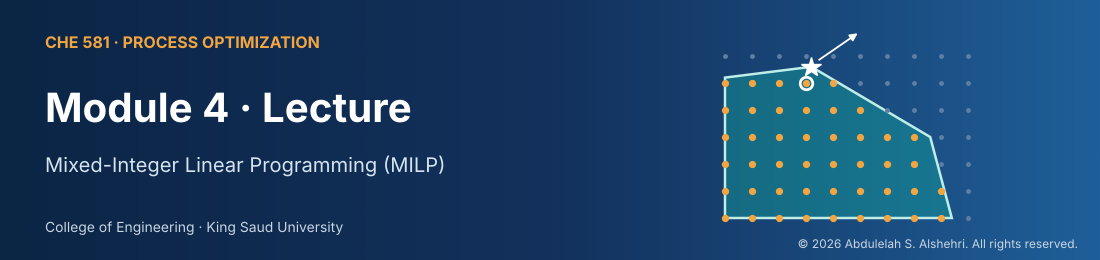

# Module 4 — Mixed-Integer Linear Programming (MILP)
### CHE 581: Process Optimization
**College of Engineering — King Saud University** · Instructor: **Dr. Abdulelah S. Alshehri**

>  Many of the most valuable decisions in a chemical plant are not "how much?" but "**which one?**", "**whether?**" and "**in what order?**". This lecture shows how to model them as a **mixed-integer linear program** and how solvers find the optimum.

<sub>© 2026 Abdulelah S. Alshehri. All rights reserved.</sub>

In [ ]:
# ⚙️ Setup: run this cell first (it is hidden in slide mode)
import itertools, time, warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import milp, linprog, LinearConstraint, Bounds
warnings.filterwarnings("ignore")
try:                                   # sliders work in Colab / Jupyter with ipywidgets
    from ipywidgets import interact, FloatSlider
    HAS_WIDGETS = True
except ImportError:                    # otherwise we simply draw a static plot
    HAS_WIDGETS = False

NAVY, BLUE, TEAL, GOLD, RED, GRAY, GREEN = "#0B2545", "#1F6FB2", "#13A89E", "#F2A541", "#D64545", "#8D99AE", "#2E9E5B"
plt.rcParams.update({"figure.figsize": (8, 3.4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})

def solve_milp(c, A_ub=None, b_ub=None, A_eq=None, b_eq=None, integrality=None, lb=0, ub=np.inf, maximize=False):
    """Thin wrapper around scipy.optimize.milp (HiGHS). integrality: 1 = integer, 0 = continuous (default: all integer)."""
    c = np.asarray(c, float); cons = []
    if A_ub is not None: cons.append(LinearConstraint(np.atleast_2d(A_ub), -np.inf, b_ub))
    if A_eq is not None: cons.append(LinearConstraint(np.atleast_2d(A_eq), b_eq, b_eq))
    integ = np.ones(len(c)) if integrality is None else np.asarray(integrality)
    res = milp(-c if maximize else c, constraints=cons, integrality=integ, bounds=Bounds(lb, ub))
    obj = None if res.x is None else (-res.fun if maximize else res.fun)
    return res.x, obj, res

print("✅ Setup complete. scipy.optimize.milp calls the open-source HiGHS solver, so nothing needs installing.")

✅ Setup complete. scipy.optimize.milp calls the open-source HiGHS solver, so nothing needs installing.


##  Roadmap & Learning Outcomes

| Part | Slides | Topics |
|---|---|---|
| **A · Why integers?** | 1 – 4 | discrete decisions, LP / IP / MILP / MINLP, the rounding trap, project selection |
| **B · The modeling toolkit** | 5 – 11 | logic with binaries, fixed charges, big-M, products, absolute values, piecewise-linear costs, logic → inequalities, strong vs. weak formulations |
| **C · Classic structures & process applications** | 12 – 18 | knapsack, covering, assignment, facility location, TSP, unit commitment, batch scheduling, **distillation-sequence synthesis** |
| **D · How MILP solvers work** | 19 – 29 | relaxations & bounds, **branch & bound**, search strategies, cutting planes (Gomory, cover), branch-and-cut, formulation tips |

**By the end of this lecture you will be able to:**
1. Spot the **discrete decisions** in a process problem and write them with **binary / integer variables**.
2. Use the standard **modeling toolkit**: logic constraints, fixed charges, big-M, linearized products, piecewise-linear costs.
3. Formulate the classic MILPs (knapsack, covering, assignment, facility location, TSP, unit commitment, superstructure synthesis).
4. Explain how **branch & bound** uses LP relaxations, bounds and fathoming to avoid complete enumeration.
5. Derive **valid inequalities** (Gomory, cover) and explain why they tighten the relaxation.
6. Judge the **strength** of a formulation and read a solver's incumbent, bound and gap.

# Part A
## Why integers?
### *When the decision is yes/no, which one, or how many*

## 1 · Discrete decisions are everywhere in process engineering

| ❓ Decision | Type | Variable |
|---|---|---|
| Build the new plant in Jubail? | binary | $y$ |
| CSTR, PFR or membrane reactor? | one-of choice | $y_1, y_2, y_3$ |
| How many parallel compressors? | general integer | $n$ |
| Is gas turbine 2 **on** at 15:00? | binary (operations) | $u_t$ |
| In which **order** do we run A, B, C? | binary (sequencing) | $x_{ij}$ |
| How much steam, flow, capacity? | continuous | $x$ |

A **mixed-integer linear program (MILP)**:

$$\min_{x,\,y}\; c^\top x + d^\top y \qquad \text{s.t.}\qquad A\,x + B\,y \le b,\qquad x \ge 0,\quad y \in \{0,1\}^m$$

- The objective and **all** constraints are **linear**.
- Some variables are **continuous** ($x$: flows, capacities); some are **discrete** ($y$: decisions).

>  No $y$ ⇒ **LP**. No $x$ ⇒ pure **integer program (IP)**. Both ⇒ **MILP**. Nonlinear terms as well ⇒ **MINLP**.

## 2 · LP, IP, MILP, MINLP: what integrality does to the feasible set

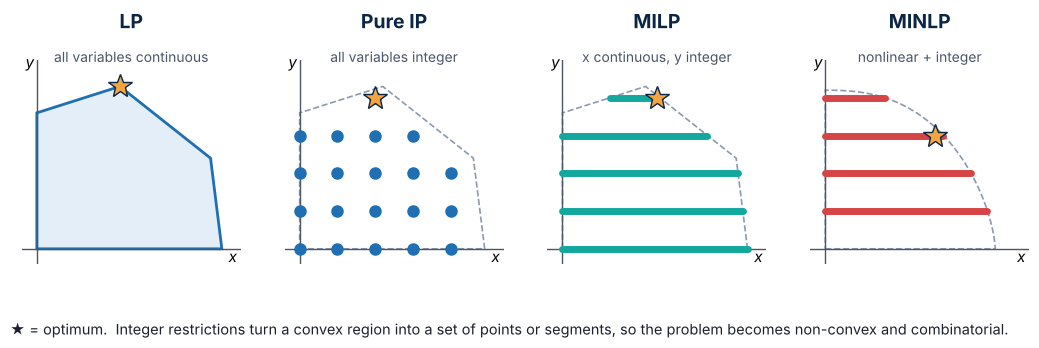

| | LP | MILP / IP |
|---|---|---|
| Feasible set | one **convex** polyhedron | points or parallel segments: **non-convex** |
| Optimum | at a vertex (simplex, interior point) | anywhere inside: no local test of optimality |
| Complexity | polynomial | **NP-hard** in general |
| In practice | millions of variables | 10⁴ – 10⁶ variables are routine with modern solvers (Part D) |

## 3 · Why not just solve the LP and round?

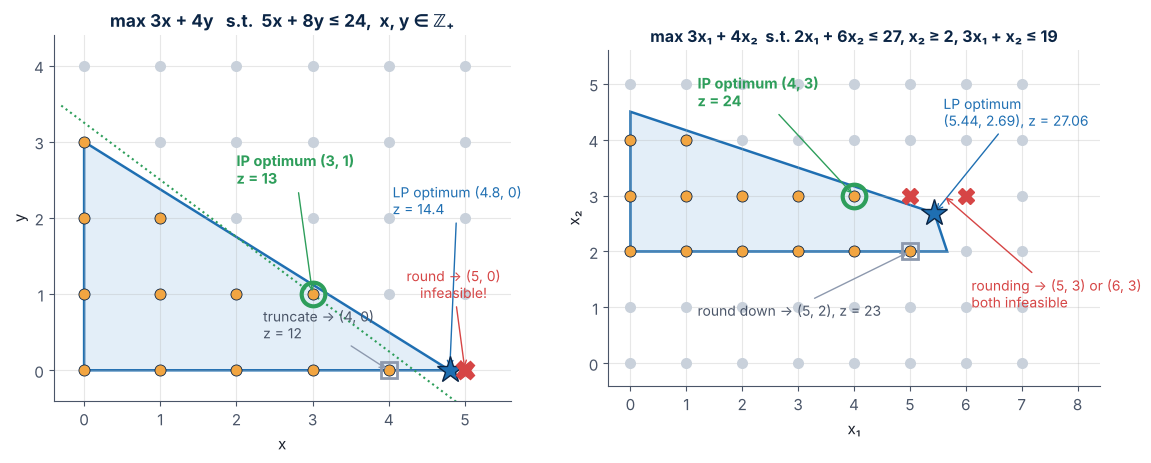

| Strategy | Example 1 (left) | Example 2 (right) |
|---|---|---|
| LP relaxation | (4.8, 0), z = 14.4 | (5.44, 2.69), z = 27.06 |
| Round to nearest | (5, 0) ❌ **infeasible** | (5, 3) ❌ **infeasible** |
| Round down | (4, 0), z = 12 (suboptimal) | (5, 2), z = 23 (suboptimal) |
| **True MILP optimum** | **(3, 1), z = 13** | **(4, 3), z = 24** |

> ⚠️ Rounding can be **infeasible** or far from optimal, and the integer optimum may be **nowhere near** the LP optimum. For binaries it is meaningless: what is "0.43 of a plant"?

In [ ]:
# 🔬 Example 1: LP relaxation vs. MILP (integrality = 0 → continuous, 1 → integer)
c, A, b = [3, 4], [[5, 8]], [24]
x_lp, z_lp, _ = solve_milp(c, A, b, integrality=[0, 0], maximize=True)
x_ip, z_ip, _ = solve_milp(c, A, b, integrality=[1, 1], maximize=True)
x_rd = np.round(x_lp)

print(f"LP relaxation : x = {x_lp.round(3)},  z = {z_lp:.2f}")
print(f"rounded LP    : x = {x_rd},  feasible? {bool(np.all(np.array(A) @ x_rd <= b))}")
print(f"MILP optimum  : x = {x_ip},  z = {z_ip:.0f}")
print(f"integrality gap = (z_LP − z_IP) / z_IP = {(z_lp - z_ip) / z_ip:.1%}")

LP relaxation : x = [4.8 0. ],  z = 14.40
rounded LP    : x = [5. 0.],  feasible? False
MILP optimum  : x = [3. 1.],  z = 13
integrality gap = (z_LP − z_IP) / z_IP = 10.8%


## 4 · Project selection: the 0-1 knapsack

A company can build new facilities in Los Angeles and San Francisco, with **\$10M** of capital available.

| $i$ | Project | Capital needed | Expected profit |
|---|---|---|---|
| 1 | factory in LA | \$6M | \$9M |
| 2 | factory in SF | \$3M | \$5M |
| 3 | warehouse in LA | \$5M | \$6M |
| 4 | warehouse in SF | \$2M | \$4M |

With $y_i = 1$ if project $i$ is built (0 otherwise):

$$\max\; 9y_1 + 5y_2 + 6y_3 + 4y_4 \qquad \text{s.t.}\qquad 6y_1 + 3y_2 + 5y_3 + 2y_4 \le 10,\qquad y_i \in \{0,1\}$$

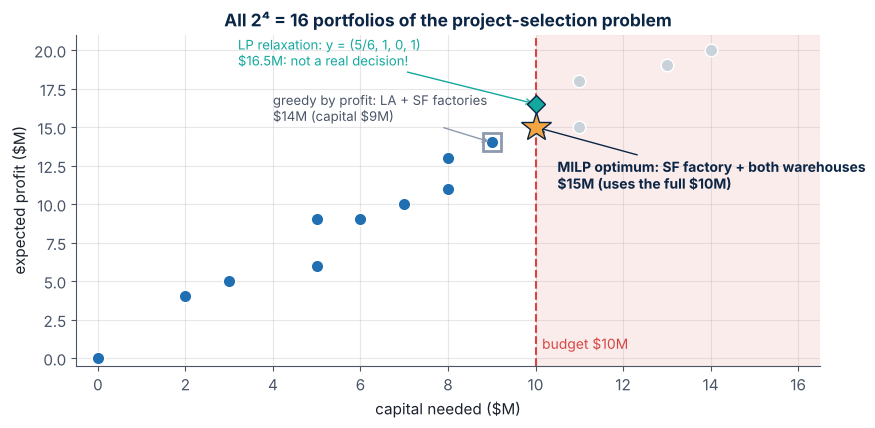

>  The single most profitable project (LA factory) is **not** in the optimal portfolio. Picking "the biggest first" gives **\$14M**; the MILP finds **\$15M**.

In [ ]:
profit, capital, budget = np.array([9, 5, 6, 4]), np.array([6, 3, 5, 2]), 10
names = ["factory LA", "factory SF", "warehouse LA", "warehouse SF"]

y, z, _ = solve_milp(profit, [capital], [budget], ub=1, maximize=True)            # binary: integer in [0, 1]
print("MILP   → build", [n for n, yi in zip(names, y) if yi > 0.5], f"profit = ${z:.0f}M")

# sanity check by brute force (fine for 2^4 = 16 options, hopeless for 2^60)
best = max((int(profit @ np.array(s)), s) for s in itertools.product([0, 1], repeat=4) if capital @ np.array(s) <= budget)
print("brute force → profit, y =", best)

y_lp, z_lp, _ = solve_milp(profit, [capital], [budget], ub=1, integrality=np.zeros(4), maximize=True)
print("LP relaxation → y =", y_lp.round(3), f"profit = ${z_lp:.2f}M  (an upper bound, not a decision)")

MILP   → build ['factory SF', 'warehouse LA', 'warehouse SF'] profit = $15M
brute force → profit, y = (15, (0, 1, 1, 1))
LP relaxation → y = [0.833 1.    0.    1.   ] profit = $16.50M  (an upper bound, not a decision)


##  Check Your Understanding 1 — Why integers?

*Try each question yourself first, then click to reveal the answer.*

**Q1.** For a **maximization** MILP, the LP relaxation gives $z = 120$ and the best integer solution found so far is $z = 112$. What do you know about the true optimum $z^*$?

<details><summary><b> Show answer</b></summary>

$112 \le z^* \le 120$. The LP relaxation is an **upper bound** and any feasible integer point is a **lower bound**. The relative gap is $(120 - 112)/112 \approx 7.1\%$.

</details>

**Q2.** Classify each problem: (a) choose the diameters of 5 pipes from a catalog *and* the flows through them; (b) find flows in a fixed network with linear costs; (c) choose which of 8 reactors to build, with nonlinear kinetics.

<details><summary><b> Show answer</b></summary>

(a) **MILP** (catalog choice = binaries, flows = continuous, if the hydraulics are linearized). (b) **LP**. (c) **MINLP**.

</details>

**Q3.** In project selection, add the rule *"the SF warehouse may only be built if the SF factory is built."* Write the constraint. Does the optimum change?

<details><summary><b> Show answer</b></summary>

$y_4 \le y_2$. The optimum $\{y_2, y_3, y_4\}$ already has $y_2 = 1$, so it is unchanged.

</details>

**Q4.** **Predict, then run the cell below:** if the budget grows from **\$10M** to **\$11M**, what is the new optimal portfolio and profit?

<details><summary><b> Show answer</b></summary>

LA factory + SF factory + SF warehouse: capital **\$11M**, profit **\$18M**. One extra **\$1M** of budget brings **+\$3M** of profit, because the best combination changes completely.

</details>

In [ ]:
y, z, _ = solve_milp(profit, [capital], [11], ub=1, maximize=True)
print("budget $11M → build", [n for n, yi in zip(names, y) if yi > 0.5], f"profit = ${z:.0f}M")

budget $11M → build ['factory LA', 'factory SF', 'warehouse SF'] profit = $18M


# Part B
## The modeling toolkit
### *Binary variables as switches, logic and costs*

## 5 · Binary variables as logic switches

| Requirement | Linear constraint |
|---|---|
| **at least one** unit of set $I$ | $\sum_{i\in I} y_i \ge 1$ |
| **exactly one** technology | $\sum_{i\in I} y_i = 1$ |
| **at most one** | $\sum_{i\in I} y_i \le 1$ |
| at most $K$ of $N$ | $\sum_{i} y_i \le K$ |
| **if** $i$ is selected **then** $k$ must be selected | $y_i \le y_k$ |
| $i$ **if and only if** $k$ | $y_i = y_k$ |

**General integers from binaries.** For $n \in \{0, 1, \dots, N\}$:

- **Unary (one-hot):** $\;n = \sum_{k=0}^{N} k\,y_k,\;\; \sum_{k} y_k = 1$ → $N+1$ binaries (8 for $N = 7$), **tighter** relaxation.
- **Binary expansion:** $\;n = \sum_{k=0}^{K} 2^k\,y_k$ → only $\lceil \log_2(N+1)\rceil$ binaries (3 for $N = 7$: $\,n = y_0 + 2y_1 + 4y_2$), **weaker** relaxation.

🛠️ *How many parallel compressors (0 to 7)?* Both encodings work; fewer binaries is **not** automatically faster.

## 6 · Semi-continuous variables & fixed charges

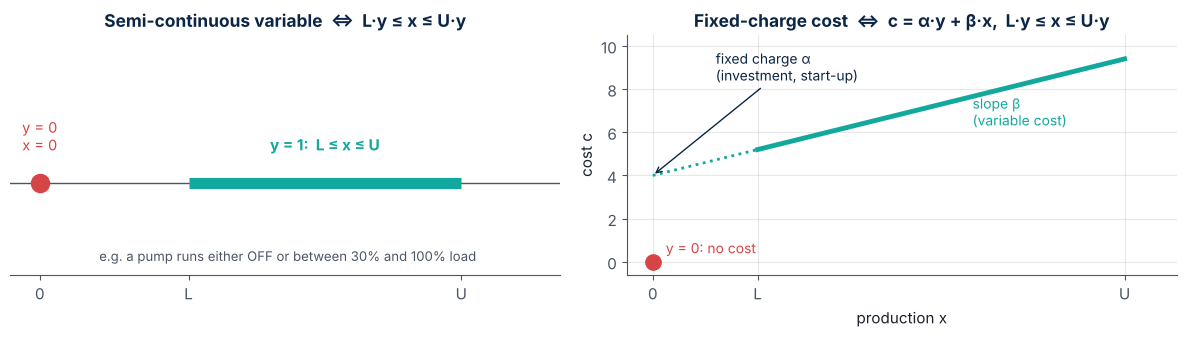

$$x = 0 \;\;\text{or}\;\; L \le x \le U \quad\Longleftrightarrow\quad L\,y \le x \le U\,y,\qquad y \in \{0,1\}$$

$$c(x) = \begin{cases} 0 & x = 0 \\ \alpha + \beta x & L \le x \le U \end{cases} \quad\Longleftrightarrow\quad c = \alpha\,y + \beta\,x,\qquad L\,y \le x \le U\,y$$

 **Where they appear:** the minimum turndown of a furnace or compressor, the minimum flow of a pump, equipment investment (fixed + size-dependent cost), start-up costs.

>  The binary does two jobs: it **switches the domain** ($y = 0$ forces $x = 0$) and **charges the fixed cost** $\alpha$ only when the unit exists.

## 7 ·  Process planning: should we build the plant?

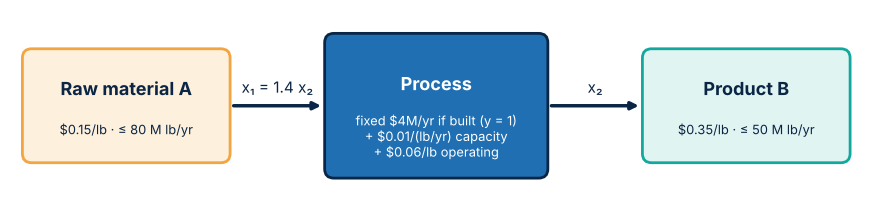

**Variables:** $x_1$ = A consumed, $x_2$ = B produced (million lb/yr); $y = 1$ if the process is built.

**Annual profit** (million dollars per year):
$$P = \underbrace{0.35x_2}_{\text{sales}} - \underbrace{0.15x_1}_{\text{raw material}} - \underbrace{(4y + 0.01x_2)}_{\text{investment}} - \underbrace{0.06x_2}_{\text{operations}}$$

$$\max\; -4y - 0.15x_1 + 0.28x_2 \quad\text{s.t.}\quad x_1 = 1.4\,x_2,\quad 0 \le x_1 \le 80\,y,\quad 0 \le x_2 \le 50\,y,\quad y \in \{0,1\}$$

**Think:** can the constraint $x_1 \le 80y$ be replaced by $x_1 \le 80$?

<details><summary><b> Show answer</b></summary>

**Yes.** $x_1 = 1.4x_2 \le 1.4 \cdot 50y = 70y \le 80y$, so the link between $x_1$ and $y$ is already implied. **But** the link $x_2 \le 50y$ is essential: without it the model would produce B without paying the 4 million-dollar-per-year fixed charge.

</details>

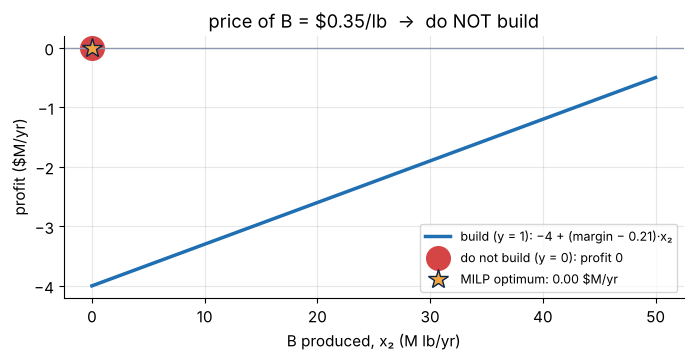

break-even production = 4 / 0.07 = 57.1 M lb/yr (demand = 50)


In [ ]:
#  Interactive: change the price and demand of B. When does building pay off?
def plan(price_B=0.35, demand_B=50.0):
    margin = price_B - 0.06 - 0.01                       # $/lb B after operating and variable investment cost
    c = [-0.15, margin, -4.0]                            # variables [x1, x2, y], profit in $M/yr
    x, z, _ = solve_milp(c, A_ub=[[1, 0, -80], [0, 1, -demand_B]], b_ub=[0, 0], A_eq=[[1, -1.4, 0]], b_eq=[0],
                         integrality=[0, 0, 1], ub=[np.inf, np.inf, 1], maximize=True)
    x2 = np.linspace(0, demand_B, 50)
    plt.plot(x2, -4 + (margin - 0.21) * x2, color=BLUE, lw=2.5, label="build (y = 1): −4 + (margin − 0.21)·x₂")
    plt.plot(0, 0, "o", ms=17, color=RED, label="do not build (y = 0): profit 0")
    plt.plot(x[1], z, "*", ms=15, color=GOLD, mec=NAVY, zorder=5, label=f"MILP optimum: {z + 0:.2f} $M/yr")
    plt.axhline(0, color=GRAY, lw=1); plt.xlabel("B produced, x₂ (M lb/yr)"); plt.ylabel("profit ($M/yr)")
    plt.title(f"price of B = ${price_B:.2f}/lb  →  " + ("BUILD the plant" if x[2] > 0.5 else "do NOT build"))
    plt.legend(fontsize=9, loc="lower right"); plt.show()
    print(f"break-even production = 4 / {margin - 0.21:.2f} = {4 / max(margin - 0.21, 1e-9):.1f} M lb/yr (demand = {demand_B:.0f})")

if HAS_WIDGETS:
    interact(plan, price_B=FloatSlider(value=0.35, min=0.30, max=0.45, step=0.005, readout_format=".3f"),
             demand_B=FloatSlider(value=50, min=20, max=57, step=1))
else:
    plan()

## 8 · Big-M, products of variables & absolute values

**Binary × continuous** $p = x \cdot y$ with $x \in [L, U]$ (Glover, 1975):
$$L\,y \le p \le U\,y, \qquad x - U(1-y) \le p \le x - L(1-y)$$

**Binary × binary** $p = y_1 y_2$: $\quad p \le y_1,\quad p \le y_2,\quad p \ge y_1 + y_2 - 1,\quad p \ge 0$

**Absolute value** $z = \lvert x \rvert$ with $x \in [L, U]$, $L < 0 < U$: $\;x = x^+ - x^-,\; z = x^+ + x^-,\; 0 \le x^+ \le U y,\; 0 \le x^- \le \lvert L\rvert(1-y)$
(When you only **minimize** $\lvert x\rvert$, the LP trick $z \ge x,\, z \ge -x$ suffices with no binary. The binary is needed when $\lvert x\rvert$ is maximized or fixed.)
🛠️ $\lvert x\rvert$ appears in deviations from a setpoint or blend specification, and in the **LASSO** penalty $\lVert\theta\rVert_1$ used to fit sparse data-driven process models.

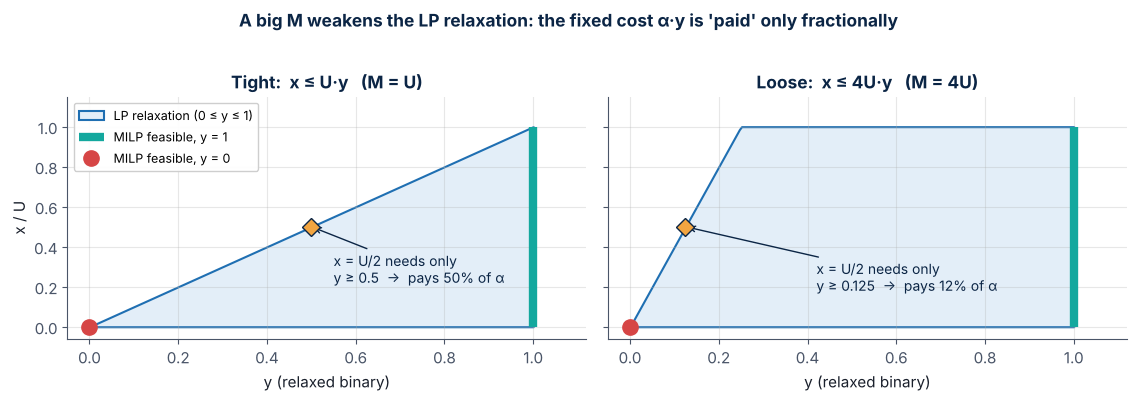

> ⚠️ Choose $M$ as **small as the physics allows** (equipment capacity, total feed, …). A huge $M$ weakens the relaxation and invites numerical trouble: $y = 10^{-6}$ is "zero" to the solver yet still allows a **trickle flow** $x = My > 0$.

## 9 · Piecewise-linear costs: economies of scale

Capital cost follows the **six-tenths rule** $C = a\,q^{0.6}$: **concave**, so the cost per unit of capacity falls with size.

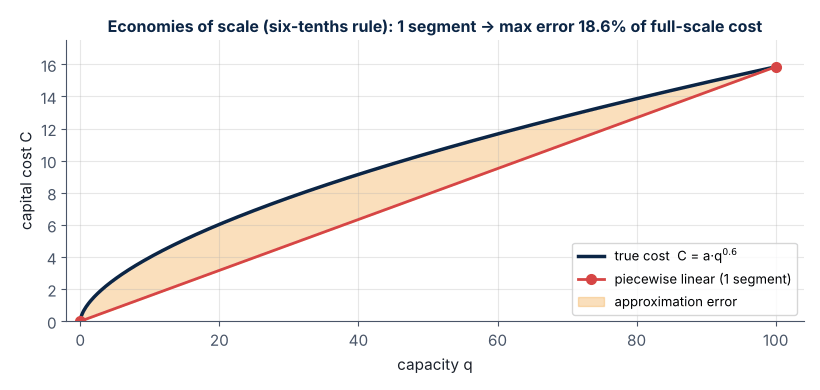

With breakpoints $B_0 < B_1 < \dots < B_P$, slope $\alpha_p = \frac{f(B_p) - f(B_{p-1})}{B_p - B_{p-1}}$ and intercept $\beta_p = f(B_p) - \alpha_p B_p$:

$$f(x) = \sum_p \big(\alpha_p z_p + \beta_p y_p\big),\qquad \sum_p y_p = 1,\qquad \sum_p z_p = x,\qquad B_{p-1}\,y_p \le z_p \le B_p\,y_p,\quad y_p \in \{0,1\}$$

>  **Minimizing a convex** piecewise-linear cost needs **no** binaries (the LP picks the cheap segments first). **Minimizing a concave** cost (economies of scale) **does** need binaries, otherwise the LP would "skip" the expensive first segment. Solvers also offer **SOS2** constraints and Pyomo has `Piecewise` (see the Tutorial).

## 10 · From logic to linear inequalities

**Recipe:** write the rule in propositional logic → convert it to **conjunctive normal form (CNF)** → one inequality per clause.

1. Remove implications: $P_1 \Rightarrow P_2 \;\equiv\; \neg P_1 \vee P_2$
2. Move negations inward (De Morgan): $\neg(P_1 \wedge P_2) \equiv \neg P_1 \vee \neg P_2$, $\;\neg(P_1 \vee P_2) \equiv \neg P_1 \wedge \neg P_2$
3. Distribute OR over AND: $(P_1 \wedge P_2) \vee P_3 \equiv (P_1 \vee P_3) \wedge (P_2 \vee P_3)$
4. Each clause becomes $\sum_{P_i} y_i + \sum_{\neg P_j} (1 - y_j) \ge 1$

| Logic | Inequality |
|---|---|
| $P_1 \vee P_2 \vee \dots \vee P_n$ | $y_1 + y_2 + \dots + y_n \ge 1$ |
| $P_1 \wedge P_2$ | $y_1 \ge 1,\; y_2 \ge 1$ |
| $P_1 \Rightarrow P_2$ | $1 - y_1 + y_2 \ge 1 \;\Leftrightarrow\; y_2 \ge y_1$ |

 **Product recovery:** "If the absorber (A) **or** the membrane separator (M) is selected, do **not** use cryogenic separation (C)."

$$(P_A \vee P_M) \Rightarrow \neg P_C \;\equiv\; (\neg P_A \wedge \neg P_M) \vee \neg P_C \;\equiv\; (\neg P_A \vee \neg P_C) \wedge (\neg P_M \vee \neg P_C) \;\Rightarrow\; \boxed{y_A + y_C \le 1,\quad y_M + y_C \le 1}$$

In [ ]:
# 🔬 Always verify a logic model by brute force over the truth table
print(" yA yM yC | logic  inequalities")
for yA, yM, yC in itertools.product([0, 1], repeat=3):
    logic = (not (yA or yM)) or (not yC)                 # (A ∨ M) ⇒ ¬C
    ineq  = (yA + yC <= 1) and (yM + yC <= 1)
    print(f"  {yA}  {yM}  {yC} | {str(logic):5s}  {str(ineq):5s} {'✔' if logic == ineq else '✘ MISMATCH'}")

 yA yM yC | logic  inequalities
  0  0  0 | True   True  ✔
  0  0  1 | True   True  ✔
  0  1  0 | True   True  ✔
  0  1  1 | False  False ✔
  1  0  0 | True   True  ✔
  1  0  1 | False  False ✔
  1  1  0 | True   True  ✔
  1  1  1 | False  False ✔


## 11 · Strong vs. weak formulations & integer cuts

"If task 1 **or** task 2 runs, unit $z$ must be selected." Two correct models of the **same** binary points:

| Intuitive (aggregated) | Logic-based (disaggregated) |
|---|---|
| $y_1 + y_2 \le 2z$ (1 constraint) | $y_1 \le z,\; y_2 \le z$ (2 constraints) |

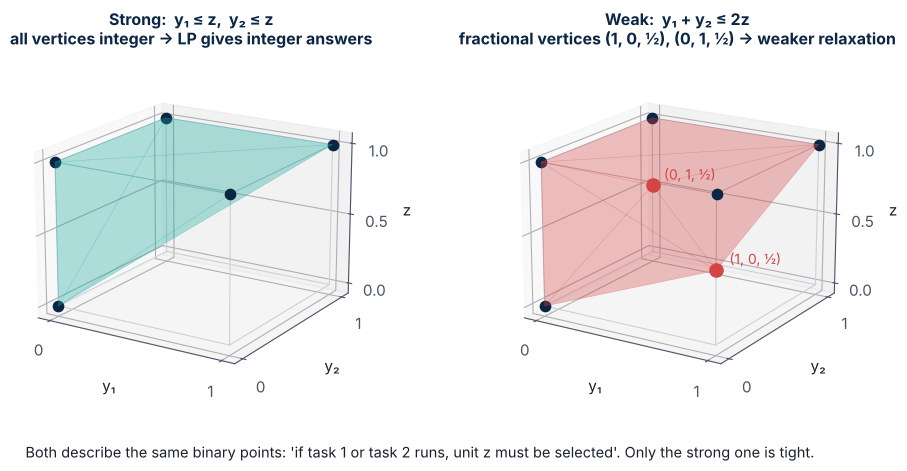

>  **More constraints can make a model faster.** What matters is how close the LP relaxation is to the **convex hull** of the integer points.

**Integer cut:** to forbid one 0-1 combination $y^*$, with $B = \{j : y^*_j = 1\}$ and $N = \{j : y^*_j = 0\}$:
$$\sum_{j \in B} y_j - \sum_{j \in N} y_j \le \lvert B\rvert - 1$$
Used to find the **2nd-best, 3rd-best, …** designs (slide 18).

## Check Your Understanding 2 — The modeling toolkit

*Try each question yourself first, then click to reveal the answer.*

**Q1.** A feed pump must be either **off** or deliver between **20 and 100 kg/h**. Model it.

<details><summary><b> Show answer</b></summary>

$20\,y \le x \le 100\,y$, $y \in \{0,1\}$. A pump cost $\alpha y + \beta x$ adds the fixed charge only when $y = 1$.

</details>

**Q2.** Linearize $p = y_1 y_2$ for binary $y_1, y_2$.

<details><summary><b> Show answer</b></summary>

$p \le y_1,\; p \le y_2,\; p \ge y_1 + y_2 - 1,\; p \ge 0$. Check: $p = 1$ only when both are 1.

</details>

**Q3.** "If the reactor is selected ($y_R$), then a flash ($y_F$) **or** a column ($y_D$) must follow." Write the inequality.

<details><summary><b> Show answer</b></summary>

$P_R \Rightarrow (P_F \vee P_D) \equiv \neg P_R \vee P_F \vee P_D \;\Rightarrow\; (1 - y_R) + y_F + y_D \ge 1 \;\Leftrightarrow\; y_F + y_D \ge y_R$.

</details>

**Q4.** A student writes $x \le 10^6\,y$ for a stream that can never exceed 100 kg/h. What two problems can this cause?

<details><summary><b> Show answer</b></summary>

(1) A **weak relaxation**: $y = 10^{-4}$ already allows $x = 100$, so the fixed cost is almost ignored, the bounds are poor and branch & bound explodes. (2) **Numerical issues**: with an integrality tolerance of ~$10^{-6}$, $y \approx 10^{-6}$ counts as 0 yet allows $x = 1$ kg/h ("trickle flow"). Use $M = 100$.

</details>

**Q5.** Why does **minimizing** a six-tenths-rule cost need binaries, while minimizing a convex piecewise cost does not?

<details><summary><b> Show answer</b></summary>

For a concave cost the first segment is the **steepest**. A pure LP would fill the cheaper later segments first, which is physically impossible. Binaries force the segments to be used in order. For a convex cost the cheap segments come first anyway.

</details>

# Part C
## Classic structures & process applications
### *Recognize the pattern, reuse the formulation*

## 12 · A gallery of classic MILP structures

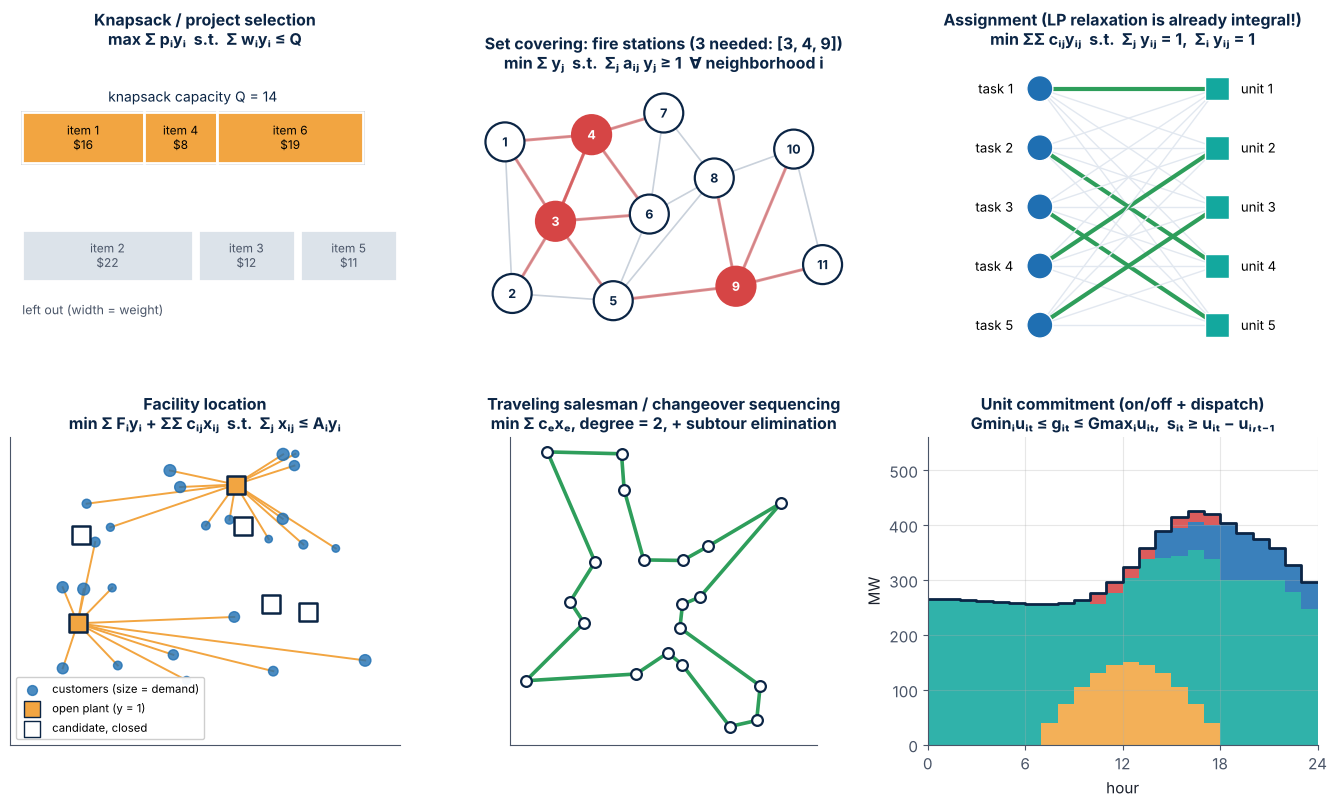

| Structure | Typical ChE use | Key constraint |
|---|---|---|
| **Knapsack** | equipment / project selection under a budget | $\sum_i w_i y_i \le Q$ |
| **Set covering** | place gas detectors or analyzers so every unit is watched | $\sum_j a_{ij} y_j \ge 1\;\; \forall i$ |
| **Assignment** | operators → control rooms, orders → reactors | $\sum_j y_{ij} = 1,\; \sum_i y_{ij} = 1$ |
| **Facility location** | where to build plants, depots, hydrogen hubs | $\sum_j x_{ij} \le A_i\,y_i$ |
| **TSP** | product changeover sequence, delivery routes | degree = 2 + subtour elimination |
| **Unit commitment** | on/off schedule of boilers, turbines, compressors | $G^{\min}_i u_{it} \le g_{it} \le G^{\max}_i u_{it}$ |
| **Integer allocation** | crews or analyzers per unit per day; operating rooms per hospital department per day | $\sum_i x_{it} \le N,\;\; x_{it} \in \{0, 1, \dots, N\}$ |

>  Assignment (and transportation / network-flow) matrices are **totally unimodular**, so their LP relaxation already has integer vertices. Knapsack, covering, facility location and TSP are **NP-hard**.

## 13 · TSP: too many constraints? Generate them only when needed

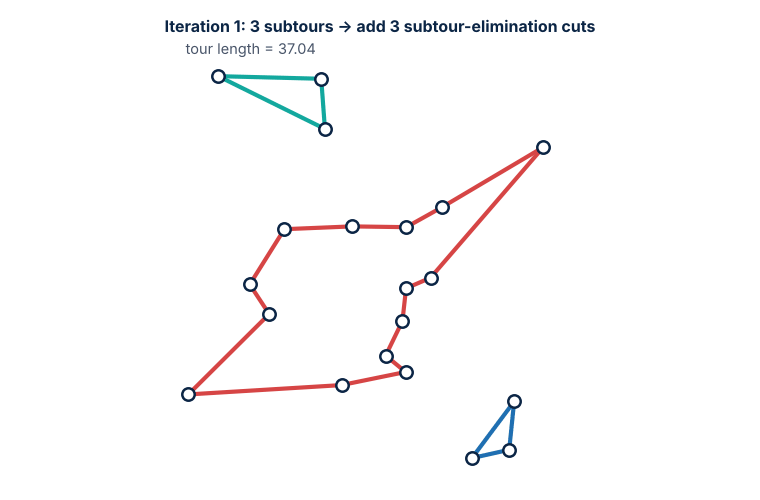

$$\min \sum_{e} c_e x_e \quad\text{s.t.}\quad \underbrace{\sum_{e \in \delta(i)} x_e = 2 \;\;\forall i}_{\text{degree}},\qquad \underbrace{\sum_{e \subseteq S} x_e \le \lvert S\rvert - 1 \;\;\forall S \subset N,\; 2 \le \lvert S\rvert \le n-1}_{\text{subtour elimination: }2^n\text{ of them!}},\qquad x_e \in \{0,1\}$$

**Constraint generation (lazy constraints):** solve with the degree constraints only → find the subtours → add their elimination cuts → re-solve, until a single tour remains. Here **4 solves** were enough instead of writing $2^{20} \approx 10^6$ constraints.

🛠️ **ChE twist:** a multiproduct batch reactor needs sequence-dependent **cleaning time** between products. The best production cycle is a TSP (see the Tutorial).

## 14 · Unit commitment: on/off decisions + dispatch

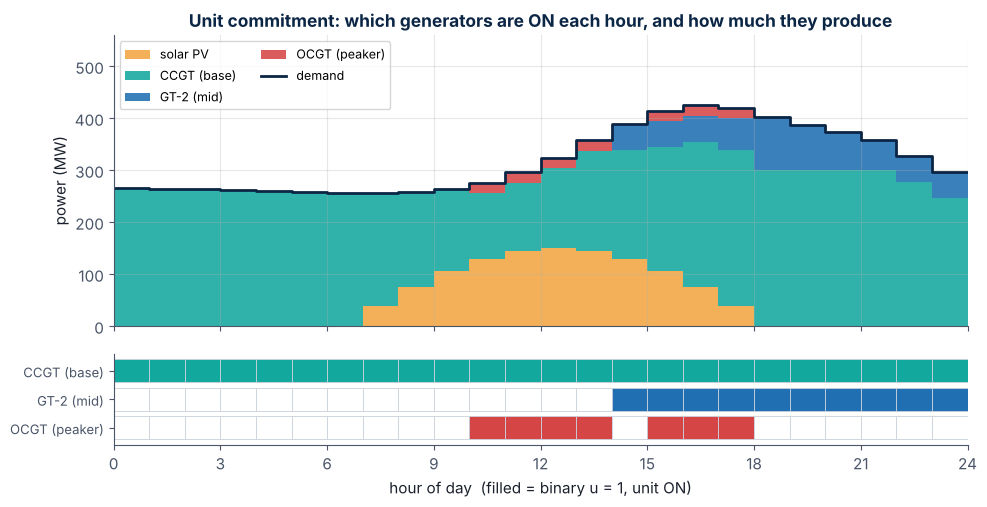

$$\begin{aligned}
\min\;\; & \sum_{t}\sum_{i} \big(CG_i\,g_{it} + CU_i\,u_{it} + SU_i\,s_{it}\big) && \text{fuel + no-load + start-up cost}\\
\text{s.t.}\;\; & \sum_i g_{it} + pv_t = D_t && \text{meet the demand every hour}\\
& G^{\min}_i u_{it} \le g_{it} \le G^{\max}_i u_{it} && \text{an ON unit runs between min and max (semi-continuous)}\\
& s_{it} \ge u_{it} - u_{i,t-1} && \text{start-up indicator}\\
& \sum_i G^{\max}_i u_{it} \ge 1.1\,D_t && \text{10\% spinning reserve}\\
& u_{it},\, s_{it} \in \{0,1\},\;\; g_{it} \ge 0
\end{aligned}$$

Extensions: minimum up/down times, ramp limits, emissions, storage. Binaries decide **which** units run; continuous variables decide **how much**. The noon solar peak lets the base unit turn down; after sunset the mid-merit unit must start.

## 15 · Batch scheduling: State-Task Networks in discrete time

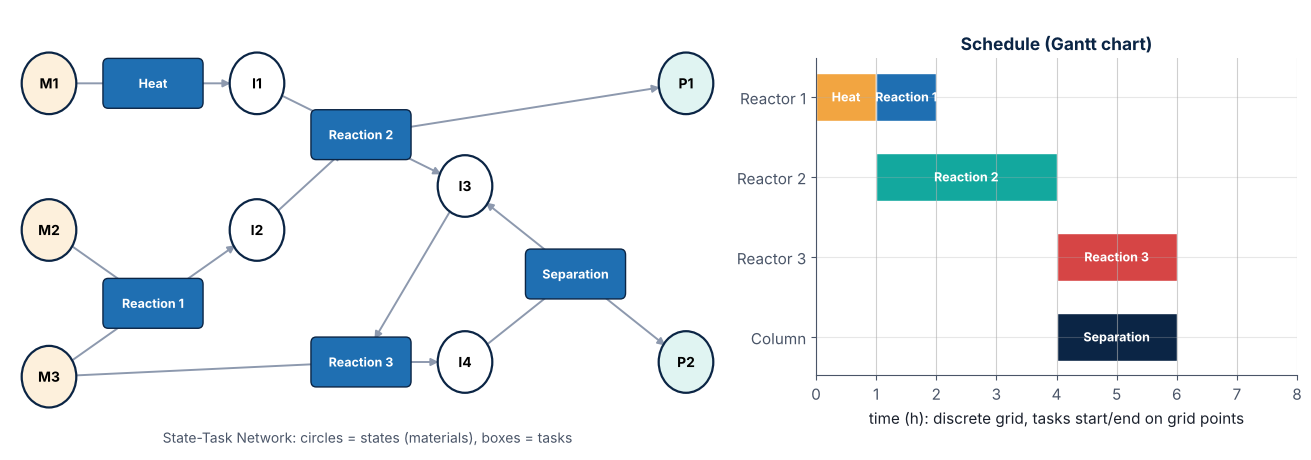

**STN** (Kondili, Pantelides & Sargent, 1993): **states** (materials) are consumed and produced by **tasks** that run in **units**.

**Discrete time:** split the horizon into intervals; $W_{ijt} = 1$ if task $i$ **starts** in unit $j$ at time $t$; $B_{ijt}$ = batch size.
- One task per unit at a time: $\sum_i \sum_{t' = t - p_i + 1}^{t} W_{ijt'} \le 1$
- Batch size: $V^{\min}_{ij} W_{ijt} \le B_{ijt} \le V^{\max}_{ij} W_{ijt}$ (semi-continuous again!)
- Material balance on every state, at every time point.

✅ simple, and resources are checked only at grid points · ❌ size grows with the number of intervals, durations are rounded to the grid, changeovers are awkward.

##  Check Your Understanding 3 — Recognize the structure

*Try each question yourself first, then click to reveal the answer.*

**Q1.** Name the classic structure: (a) choose the fewest H₂S detectors so that every compressor is within range of at least one; (b) order 6 products in one reactor with sequence-dependent cleaning; (c) assign 5 operators to 5 control rooms one-to-one; (d) decide which of 4 candidate sites gets a new depot and which customers each depot serves.

<details><summary><b> Show answer</b></summary>

(a) **Set covering** · (b) **TSP** · (c) **Assignment** (the LP relaxation is already integral) · (d) **Facility location**.

</details>

**Q2.** In unit commitment, why do we need the start-up variable $s_{it}$ at all? Couldn't we charge start-up cost on $u_{it}$?

<details><summary><b> Show answer</b></summary>

$u_{it}$ says the unit **is on**; the cost is incurred only when it **switches** off → on. $s_{it} \ge u_{it} - u_{i,t-1}$ (with $s$ minimized) equals 1 exactly at a start. Charging on $u$ would be a no-load (running) cost instead.

</details>

**Q3.** The TSP has $\approx 2^n$ subtour constraints. Why is it still solvable for thousands of cities?

<details><summary><b> Show answer</b></summary>

Most of them are never **active**. Constraint generation (and, in solvers, lazy constraints / cutting planes) adds only the violated ones. Usually a few rounds suffice.

</details>

## 16 ·  Process synthesis: which distillation sequence?

Separate **ABCD** (A lightest) into pure products with sharp-split simple columns, at **minimum annualized cost**.
Feed: 1000 kmol/h with $z$ = (0.15, 0.30, 0.35, 0.20).

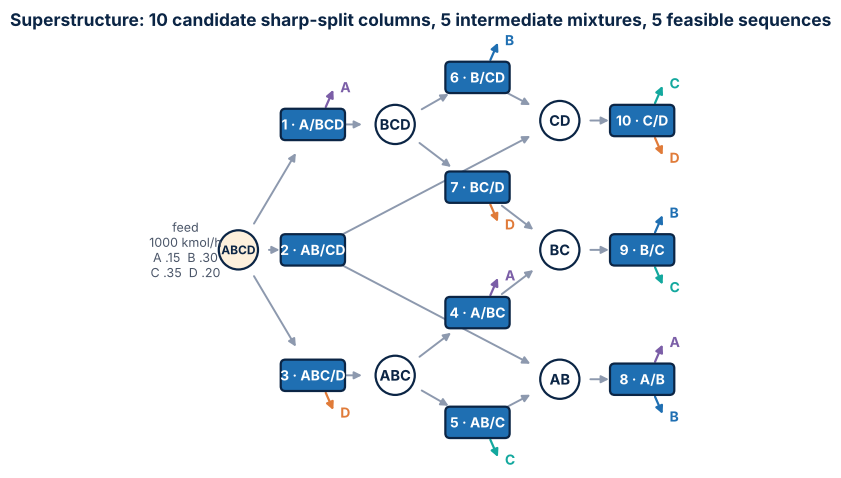

| $k$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| split | A/BCD | AB/CD | ABC/D | A/BC | AB/C | B/CD | BC/D | A/B | B/C | C/D |
| $\alpha_k$ fixed (k USD/yr) | 145 | 52 | 76 | 25 | 44 | 38 | 66 | 112 | 37 | 58 |
| $\beta_k$ variable | 0.42 | 0.12 | 0.25 | 0.78 | 0.11 | 0.14 | 0.21 | 0.39 | 0.08 | 0.19 |
| $K_k$ heat duty | 0.028 | 0.042 | 0.054 | 0.024 | 0.039 | 0.040 | 0.047 | 0.022 | 0.036 | 0.044 |

Units: $\alpha_k$ in k USD/yr, $\beta_k$ in k USD·h/(kmol·yr), $K_k$ in 10⁶ kJ/kmol. Utilities: steam $C_H = 34$ and cooling water $C_C = 1.3$ k USD·h/(10⁶ kJ·yr), with $Q_R = Q_C = K_k F_k$.
*Data: Biegler, Grossmann & Westerberg (1997).*

## 17 · The superstructure MILP

$$\begin{aligned}
\min\;\; & C = \sum_{k=1}^{10} \Big[\underbrace{\alpha_k y_k + \beta_k F_k}_{\text{investment}} + \underbrace{(C_H + C_C) K_k F_k}_{\text{steam + cooling water}}\Big] & & \\
\text{s.t.}\;\; & F_1 + F_2 + F_3 = 1000 && \text{feed ABCD}\\
& F_6 + F_7 = 0.85\,F_1 && \text{BCD (from column 1)}\\
& F_4 + F_5 = 0.80\,F_3 && \text{ABC (from column 3)}\\
& F_8 = 0.45\,F_2 + 0.5625\,F_5 && \text{AB (from columns 2, 5)}\\
& F_9 = 0.8125\,F_4 + 0.7647\,F_7 && \text{BC (from columns 4, 7)}\\
& F_{10} = 0.55\,F_2 + 0.6471\,F_6 && \text{CD (from columns 2, 6)}\\
& 0 \le F_k \le 1000\,y_k,\quad y_k \in \{0,1\} && \text{column } k \text{ exists only if } y_k = 1
\end{aligned}$$

The split fractions $\xi$ follow from the feed composition with sharp splits, e.g. $\xi^{BC}_7 = \frac{0.30 + 0.35}{0.30 + 0.35 + 0.20} = 0.7647$.

>  With sharp splits the network is **linear in the flows**: all the nonlinearity hides in the fixed split fractions. And $M = 1000$ is the **tightest natural big-M**, since no column can process more than the total feed.

## 18 · Solving it: the MILP vs. checking every sequence

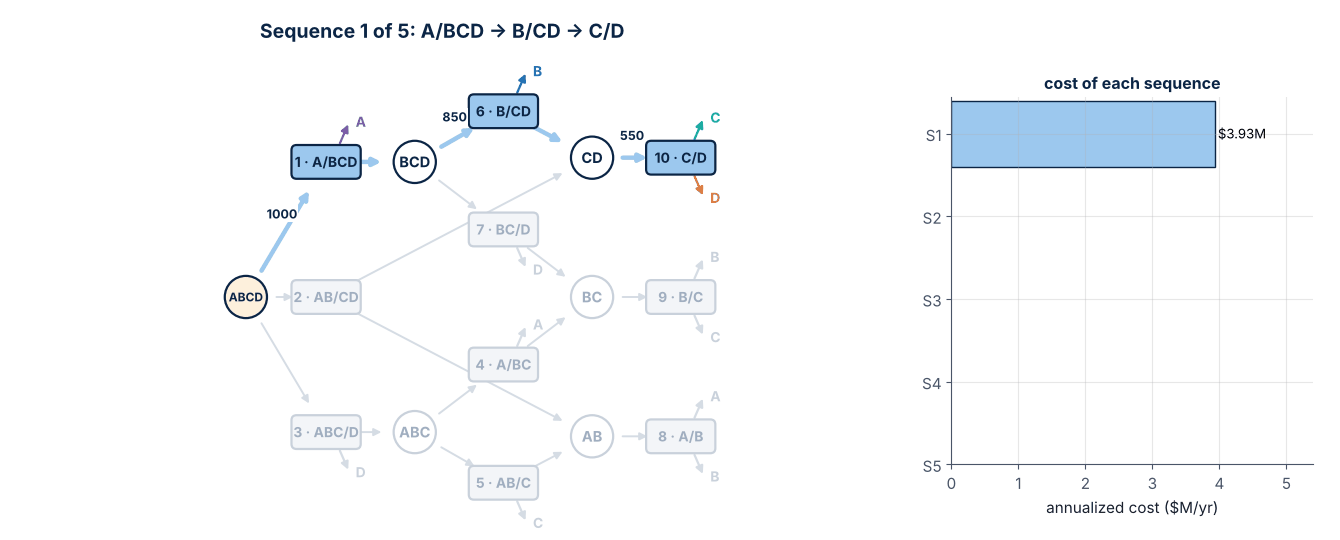

| Rank | Sequence | Cost (M USD/yr) | Total flow processed (kmol/h) |
|---|---|---|---|
| 🥇 1 | **AB/CD → A/B + C/D** | **3.308** | **2000** |
| 2 | A/BCD → B/CD → C/D | 3.927 | 2400 |
| 3 | ABC/D → AB/C → A/B | 4.103 | 2250 |
| 4 | A/BCD → BC/D → B/C | 4.123 | 2500 |
| 5 | ABC/D → A/BC → B/C | 4.474 | 2450 |

The ranking comes from repeatedly adding **integer cuts**, e.g. $y_2 + y_8 + y_{10} \le 2$ forbids the optimum and returns the 2nd best.

In [ ]:
# 🔬 Distillation-sequencing superstructure solved with scipy.optimize.milp, then ranked with integer cuts
z = {"A": .15, "B": .30, "C": .35, "D": .20}
cols = {1: ("A", "BCD", 145, .42, .028), 2: ("AB", "CD", 52, .12, .042), 3: ("ABC", "D", 76, .25, .054),
        4: ("A", "BC", 25, .78, .024), 5: ("AB", "C", 44, .11, .039), 6: ("B", "CD", 38, .14, .040),
        7: ("BC", "D", 66, .21, .047), 8: ("A", "B", 112, .39, .022), 9: ("B", "C", 37, .08, .036), 10: ("C", "D", 58, .19, .044)}
K, n, CH, CC, F = list(cols), 10, 34.0, 1.3, 1000.0
xi = lambda k, part: sum(z[c] for c in part) / sum(z[c] for c in cols[k][0] + cols[k][1])      # sharp-split fraction
cost = np.r_[[cols[k][3] + (CH + CC) * cols[k][4] for k in K], [cols[k][2] for k in K]]          # [F_1..F_10, y_1..y_10]

A_eq, b_eq = [np.r_[[1 if k <= 3 else 0 for k in K], np.zeros(n)]], [F]                          # feed split
for m in ["BCD", "ABC", "AB", "BC", "CD"]:                                                        # intermediate balances
    row = np.zeros(2 * n)
    for k in K:
        if cols[k][0] + cols[k][1] == m: row[k - 1] += 1                                           # consumers of m
        if m in cols[k][:2]:             row[k - 1] -= xi(k, m)                                    # producers of m
    A_eq.append(row); b_eq.append(0)
A_ub = [np.r_[np.eye(n)[i], -F * np.eye(n)[i]] for i in range(n)]; b_ub = list(np.zeros(n))      # F_k ≤ 1000 y_k

for rank in range(1, 4):
    x, C, _ = solve_milp(cost, A_ub, b_ub, A_eq, b_eq, integrality=np.r_[np.zeros(n), np.ones(n)], ub=np.r_[np.full(n, F), np.ones(n)])
    on = [k for k in K if x[n + k - 1] > 0.5]
    print(f"#{rank}: columns {on} = {', '.join(cols[k][0] + '/' + cols[k][1] for k in on):20s} cost = ${C/1000:.3f} M/yr")
    A_ub.append(np.r_[np.zeros(n), [1 if k in on else 0 for k in K]]); b_ub.append(len(on) - 1)   # integer cut

#1: columns [2, 8, 10] = AB/CD, A/B, C/D      cost = $3.308 M/yr
#2: columns [1, 6, 10] = A/BCD, B/CD, C/D     cost = $3.927 M/yr
#3: columns [3, 5, 8] = ABC/D, AB/C, A/B     cost = $4.103 M/yr


##  Check Your Understanding 4 — Process synthesis

*Try each question yourself first, then click to reveal the answer.*

**Q1.** Why does the "balanced" first split AB/CD win?

<details><summary><b> Show answer</b></summary>

It splits the feed almost in half (45 / 55), so the two downstream columns each handle a small flow. The total flow processed by all columns is the lowest (2000 vs. 2250–2500 kmol/h), and the steam cost, which is $\propto K_k F_k$, dominates the objective.

</details>

**Q2.** If the steam price **doubles** ($C_H = 68$), does the optimal sequence change?

<details><summary><b> Show answer</b></summary>

No. AB/CD → A/B + C/D also has the lowest $\sum K_k F_k$ (76.1 vs. ≥ 86.2), so higher steam prices make it **even more** attractive (5.90 vs. 6.86 M USD/yr for the runner-up). Changing the **feed composition** can change the answer: try it in the Tutorial.

</details>

**Q3.** How many candidate columns and sequences are there for **5** components?

<details><summary><b> Show answer</b></summary>

Columns: $\frac{(N-1)N(N+1)}{6} = 20$; sequences: **14** (for $N = 4$: 10 columns, 5 sequences). The number of sequences grows combinatorially, which is why we let the MILP choose.

</details>

**Q4.** What exactly does the integer cut $y_2 + y_8 + y_{10} \le 2$ forbid?

<details><summary><b> Show answer</b></summary>

Only the **combination** "columns 2, 8 and 10 all active". Each column can still be used individually, e.g. column 10 appears again in the 2nd-best sequence.

</details>

# Part D
## How MILP solvers work
### *Relax · bound · branch · cut*

## 19 · Relaxations: where bounds come from

Replace $y \in \{0,1\}$ by $0 \le y \le 1$: the **LP relaxation (R-MILP)** has a **larger** feasible region.

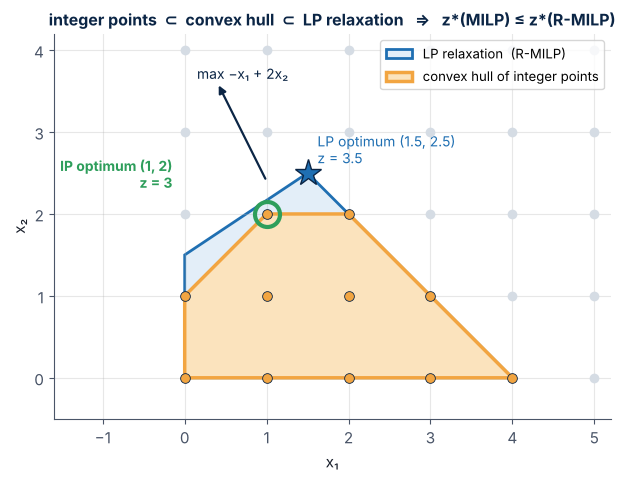

| | Maximization | Minimization |
|---|---|---|
| LP relaxation $z_{R}$ | **upper** bound: $z^* \le z_R$ | **lower** bound: $z^* \ge z_R$ |
| any feasible integer point $z_I$ | lower bound | upper bound |

**Relaxation principle:** if the relaxation's optimum happens to be **integer-feasible**, it is optimal for the MILP.

<details><summary><b> Why? (proof)</b></summary>

Let $x^*$ solve the relaxation, so $f(x^*) = z_R \ge z^*$ (max). If $x^*$ is also integer-feasible, then $f(x^*) \le z^*$. Hence $f(x^*) = z^*$ and $x^*$ is optimal.

</details>

## 20 · Why not just enumerate?

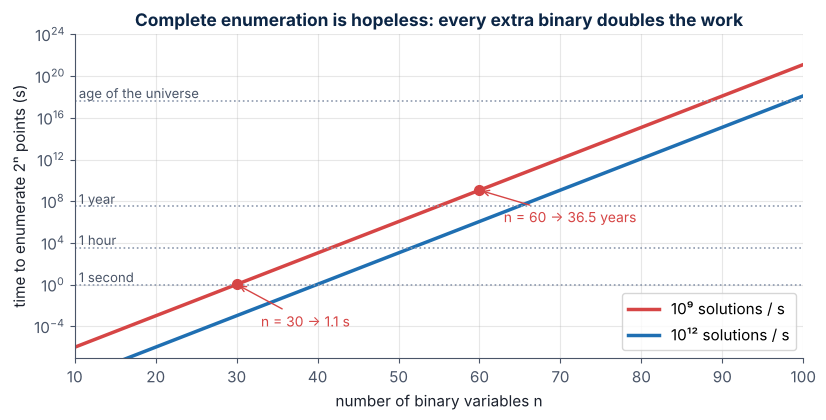

| $n$ binaries | $2^n$ combinations | at 10⁹ per second |
|---|---|---|
| 30 | 1.1 × 10⁹ | 1 second |
| 40 | 1.1 × 10¹² | 18 minutes |
| 50 | 1.1 × 10¹⁵ | 13 days |
| 60 | 1.2 × 10¹⁸ | 36.5 years |

>  A computer 1000× faster buys only **10 more binaries**. A realistic plant scheduling model has thousands. We need to enumerate **implicitly** and prune whole families of solutions at once.

## 21 · Branch & bound: the idea

| Term (maximization) | Meaning |
|---|---|
| **node** | a subproblem = the MILP + extra bounds from branching |
| $z_{LP}$ of a node | an **upper bound** for every solution below that node |
| **incumbent** $z_I$ | best integer solution found so far (a **lower bound** on $z^*$) |
| **LIST** | open nodes still to be processed |
| **fathom** | discard a node: its subtree cannot contain a better solution |

**Fathom a node when** ① its LP is **infeasible**; ② $z_{LP} \le z_I$ (fathom by **bound**); ③ its LP solution is **integer** (fathom by **integrality**, then update the incumbent).
Otherwise **branch** on a fractional variable $x_j = f$: child 1 gets $x_j \le \lfloor f \rfloor$, child 2 gets $x_j \ge \lceil f \rceil$.

```
LIST = {root};  z_I = −∞
while LIST is not empty:
    select a node S from LIST and solve its LP  →  (x_LP, z_LP)
    if LP infeasible or z_LP ≤ z_I:   fathom S
    elif x_LP is integer:             incumbent = x_LP;  z_I = z_LP
    else:                             branch on a fractional x_j  →  add 2 children to LIST
return incumbent          # optimal: every node was fathomed
```

## 22 · Branch & bound, geometrically

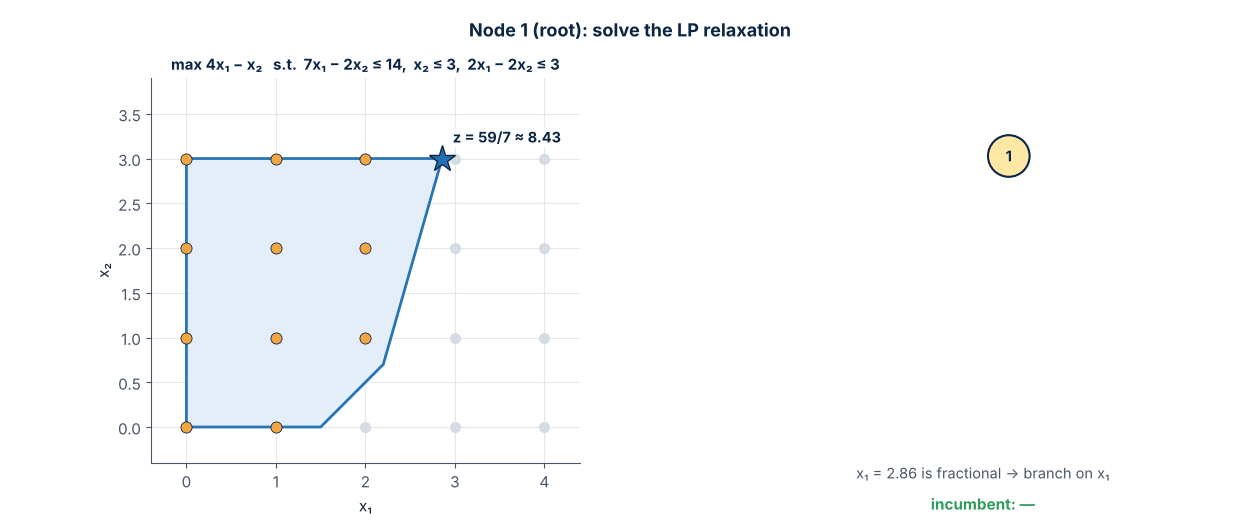

- Each branch removes a **slab of fractional points** ($2 < x_1 < 3$) but **never** an integer point.
- Node 4's LP value (6) is below the incumbent (7), so its whole subtree is pruned without being explored.
- 5 LPs prove optimality.

## 23 · Branch & bound on a 0-1 knapsack

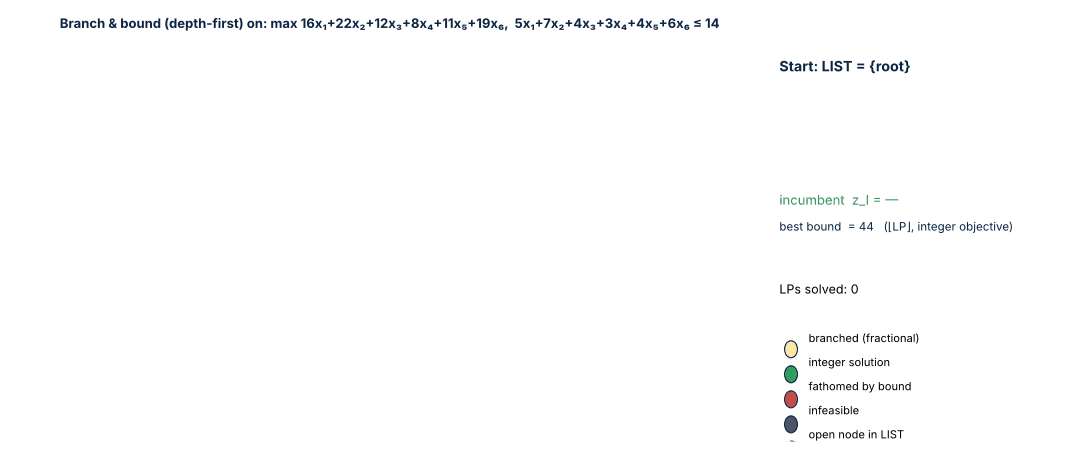

- **Depth-first** dives to integer solutions quickly (41 → 42 → 43) and backtracks.
- **Bound rounding:** all objective coefficients are integers, so any integer solution has an integer $z$. With incumbent 43, a node with $z_{LP} = 43.6$ can be fathomed ($\lfloor 43.6 \rfloor = 43$).
- 31 LPs vs. $2^6 = 64$ combinations here. On 25 items (below) B&B needs 10²–10³ LPs instead of $2^{25} \approx 3 \times 10^7$ combinations.

In [ ]:
# 🔬 A complete LP-based branch & bound in ~20 lines (binary variables, maximization)
def bnb(c, A, b, rule="depth", int_obj=True):
    n = len(c); LIST = [(np.zeros(n), np.ones(n), np.inf)]                 # (lower bounds, upper bounds, parent LP bound)
    z_I, x_I, n_lp = -np.inf, None, 0
    while LIST:
        k = int(np.argmax([nd[2] for nd in LIST])) if rule == "best" else (-1 if rule == "depth" else 0)
        lb, ub, _ = LIST.pop(k)
        r = linprog(-np.asarray(c, float), A_ub=A, b_ub=b, bounds=list(zip(lb, ub)), method="highs"); n_lp += 1
        if r.status != 0: continue                                          # ① infeasible → fathom
        z, x = -r.fun, r.x
        if (np.floor(z + 1e-9) if int_obj else z) <= z_I: continue          # ② bound → fathom
        frac = np.abs(x - np.round(x))
        if frac.max() < 1e-6: z_I, x_I = z, np.round(x); continue           # ③ integer → new incumbent
        j = int(np.argmax(frac))                                             # branch on the most fractional x_j
        ub0, lb1 = ub.copy(), lb.copy(); ub0[j], lb1[j] = 0, 1
        LIST += [(lb, ub0, z), (lb1, ub, z)]                                 # DFS explores x_j = 1 first
    return z_I, x_I, n_lp

c, A, b = [16, 22, 12, 8, 11, 19], [[5, 7, 4, 3, 4, 6]], [14]
for rule in ["depth", "best", "breadth"]:
    z, x, n = bnb(c, A, b, rule); print(f"6 items  | {rule:7s}: z* = {z:.0f}, x* = {x.astype(int)}, LPs = {n}")

rng = np.random.default_rng(1); w = rng.integers(10, 60, 25); p = w + rng.integers(-5, 15, 25); cap = int(0.45 * w.sum())
for rule in ["depth", "best", "breadth"]:
    t = time.time(); z, x, n = bnb(p, [w], [cap], rule); print(f"25 items | {rule:7s}: z* = {z:.0f}, LPs = {n:5d}  ({time.time() - t:.2f} s)")
_, z, res = solve_milp(p, [w], [cap], ub=1, maximize=True)
print(f"25 items | HiGHS  : z* = {z:.0f}, B&B nodes = {res.mip_node_count}  (presolve + cuts + heuristics!)")

6 items  | depth  : z* = 43, x* = [1 0 0 1 0 1], LPs = 31
6 items  | best   : z* = 43, x* = [1 0 0 1 0 1], LPs = 31


6 items  | breadth: z* = 43, x* = [1 0 0 1 0 1], LPs = 17


25 items | depth  : z* = 501, LPs =  1201  (2.02 s)


25 items | best   : z* = 501, LPs =   207  (0.34 s)


25 items | breadth: z* = 501, LPs =   223  (0.36 s)
25 items | HiGHS  : z* = 501, B&B nodes = 1  (presolve + cuts + heuristics!)


## 24 · Search strategies & the optimality gap

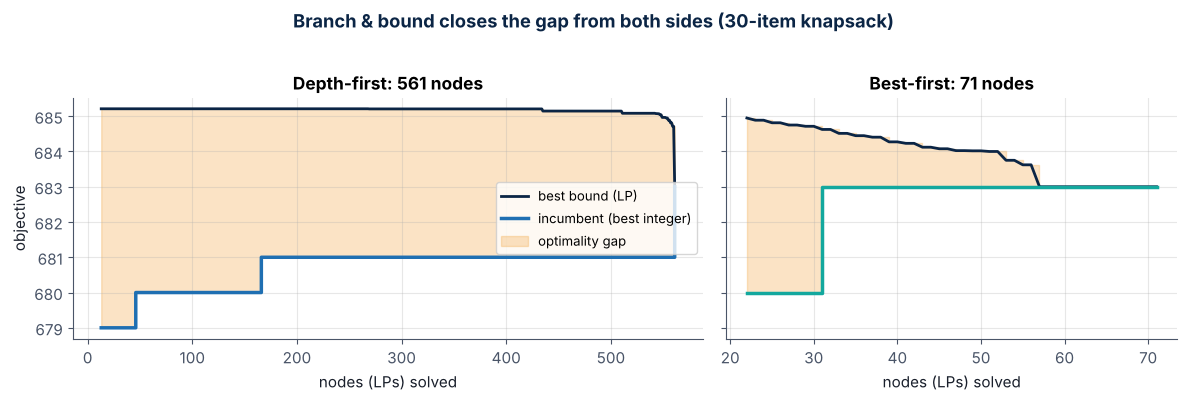

| Node selection | How | ✅ | ❌ |
|---|---|---|---|
| **Depth-first** | newest node first ("dive") | finds incumbents fast; tiny LIST; warm-started LPs | can wander in a bad subtree; bound improves slowly |
| **Best-first** | node with the best LP bound | fewest nodes to **prove** optimality | huge LIST (memory); incumbents found late |
| Breadth-first | level by level | — | memory explodes; not used in practice |

**Optimality gap** $= \dfrac{\lvert z_{\text{bound}} - z_{\text{incumbent}}\rvert}{\lvert z_{\text{incumbent}}\rvert}$. Solvers stop when gap ≤ tolerance, so **always check the solver's default gap**.
Real solvers **dive first, then switch to best-bound**, and branch on "important" variables (e.g. *build the plant?* before *pump on/off?*).

## Check Your Understanding 5 — Branch & bound

*Try each question yourself first, then click to reveal the answer.*

**Q1.** Maximization with **integer objective coefficients** and binary variables. Incumbent $z_I = 43$; a node has $z_{LP} = 43.6$. Fathom or branch?

<details><summary><b> Show answer</b></summary>

**Fathom.** Every integer solution below the node has an integer objective $\le \lfloor 43.6 \rfloor = 43 = z_I$, so it cannot be strictly better.

</details>

**Q2.** A node's LP is **infeasible**. Why can we discard the whole subtree?

<details><summary><b> Show answer</b></summary>

Its children only **add** constraints, so their feasible sets are subsets of an empty set.

</details>

**Q3.** A (minimization) solver log shows **incumbent = 1250** and **best bound = 1200**. What is the gap? Is 1250 optimal?

<details><summary><b> Show answer</b></summary>

Gap $= (1250 - 1200)/1250 = 4\%$. It is **not proven** optimal: $z^* \in [1200, 1250]$. With a 5% tolerance the solver would stop here and report "optimal".

</details>

**Q4.** Why does a solver prefer **depth-first** early in the search?

<details><summary><b> Show answer</b></summary>

To find a good **incumbent** quickly. A good $z_I$ makes fathoming by bound possible everywhere else, and the slides' example would have needed far fewer nodes had 43 been found first.

</details>

## 25 · Cutting planes: valid inequalities, facets & the convex hull

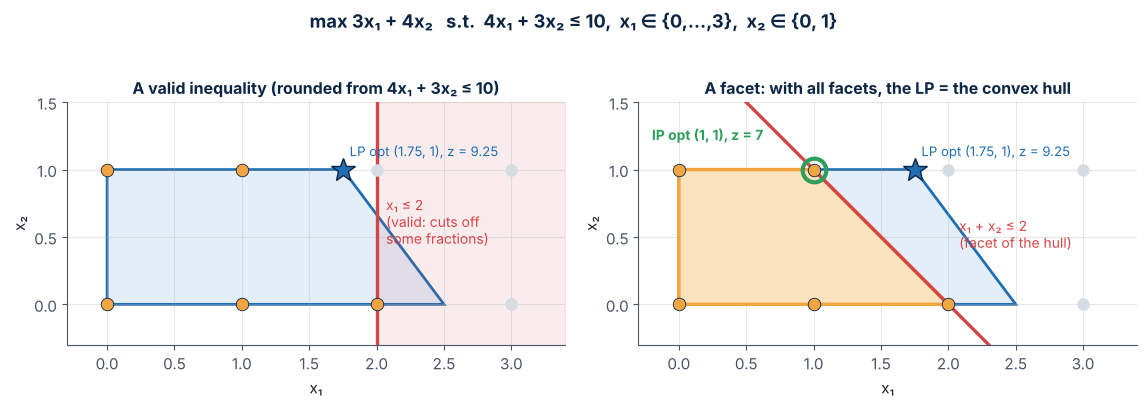

- **Valid inequality:** satisfied by **every** integer-feasible point.
- **Cutting plane:** a valid inequality that cuts off the current **fractional** LP optimum.
- **Convex hull:** the smallest convex set containing all integer points. If we knew **all its facets**, a single LP would solve the MILP!
- For realistic problems the hull has exponentially many facets, so solvers add the **useful** ones on the fly.

## 26 · Gomory cuts: rounding the simplex tableau

**Chvátal–Gomory rounding:** if $\sum_j a_j x_j \le b$ with $x \ge 0$ **integer**, then $\sum_j \lfloor a_j \rfloor x_j \le \lfloor b \rfloor$ is valid.
*Why?* $\sum_j \lfloor a_j\rfloor x_j \le \sum_j a_j x_j \le b$, and the left side is an integer, so it is $\le \lfloor b\rfloor$.

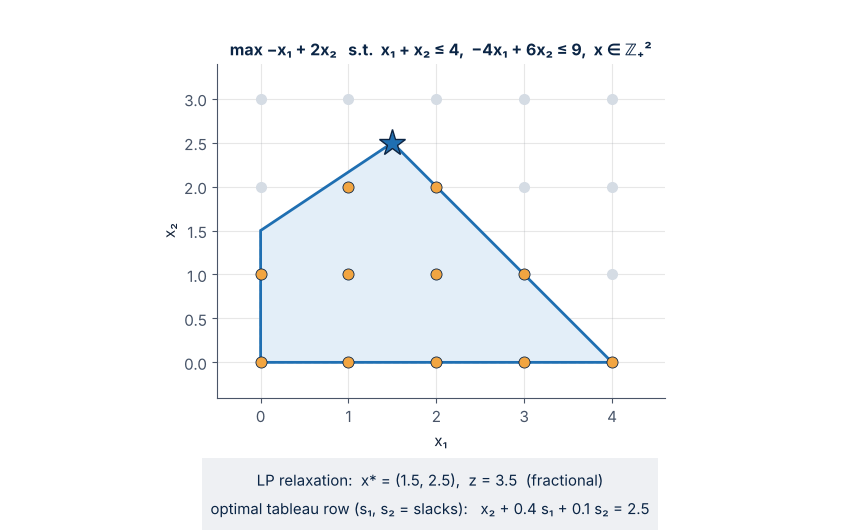

**Gomory's algorithm (1958):** ① solve the LP; ② pick a tableau row $x_i + \sum_{j \in N} \bar a_j x_j = \bar b_i$ with fractional $\bar b_i$; ③ add $x_i + \sum_{j\in N} \lfloor \bar a_j\rfloor x_j \le \lfloor \bar b_i \rfloor$; ④ repeat until the LP solution is integer.

## 27 · Cover inequalities for knapsack constraints

For $\sum_{j \in J} a_j x_j \le b$, $x$ binary: a set $C \subseteq J$ is a **cover** if $\sum_{j\in C} a_j > b$ (the items in $C$ cannot all fit). Then
$$\sum_{j \in C} x_j \le \lvert C\rvert - 1$$

Example: $5x_1 + 6x_2 + 7x_3 \le 10$ ⇒ $x_1 + x_2 \le 1$, $x_1 + x_3 \le 1$, $x_2 + x_3 \le 1$, and even $x_1 + x_2 + x_3 \le 1$ (the convex hull).

🛠️ **Our knapsack** $5x_1 + 7x_2 + 4x_3 + 3x_4 + 4x_5 + 6x_6 \le 14$:
- Every 3-subset of $\{1,2,3,6\}$ is a cover (weights 16, 18, 15, 17 > 14), so each satisfies $\le 2$.
- Adding the four: $3(x_1 + x_2 + x_3 + x_6) \le 8$ → rounding (Chvátal–Gomory) gives $\boxed{x_1 + x_2 + x_3 + x_6 \le 2}$.
- LP bound: 44.43 → **43.75**, and with integer coefficients $z^* \le 43$. **One cut vs. 31 B&B nodes!**

In [ ]:
c, w = [16, 22, 12, 8, 11, 19], [5, 7, 4, 3, 4, 6]
lp = lambda A, b: solve_milp(c, A, b, integrality=np.zeros(6), ub=1, maximize=True)
for label, A, b in [("no cuts", [w], [14]),
                    ("+ covers x1+x2+x6 ≤ 2, x2+x3+x6 ≤ 2", [w, [1, 1, 0, 0, 0, 1], [0, 1, 1, 0, 0, 1]], [14, 2, 2]),
                    ("+ CG-rounded cut x1+x2+x3+x6 ≤ 2", [w, [1, 1, 1, 0, 0, 1]], [14, 2])]:
    x, z, _ = lp(A, b); print(f"LP bound {label:40s}: {z:6.3f}   x = {x.round(2)}")
print(f"true MILP optimum{'':33s}: {solve_milp(c, [w], [14], ub=1, maximize=True)[1]:6.3f}")

LP bound no cuts                                 : 44.429   x = [1.   0.43 0.   0.   0.   1.  ]
LP bound + covers x1+x2+x6 ≤ 2, x2+x3+x6 ≤ 2     : 44.000   x = [1.  1.  0.5 0.  0.  0. ]
LP bound + CG-rounded cut x1+x2+x3+x6 ≤ 2        : 43.750   x = [0.   1.   0.   0.   0.25 1.  ]
true MILP optimum                                 : 43.000


## 28 · Branch-and-cut: how modern solvers really work

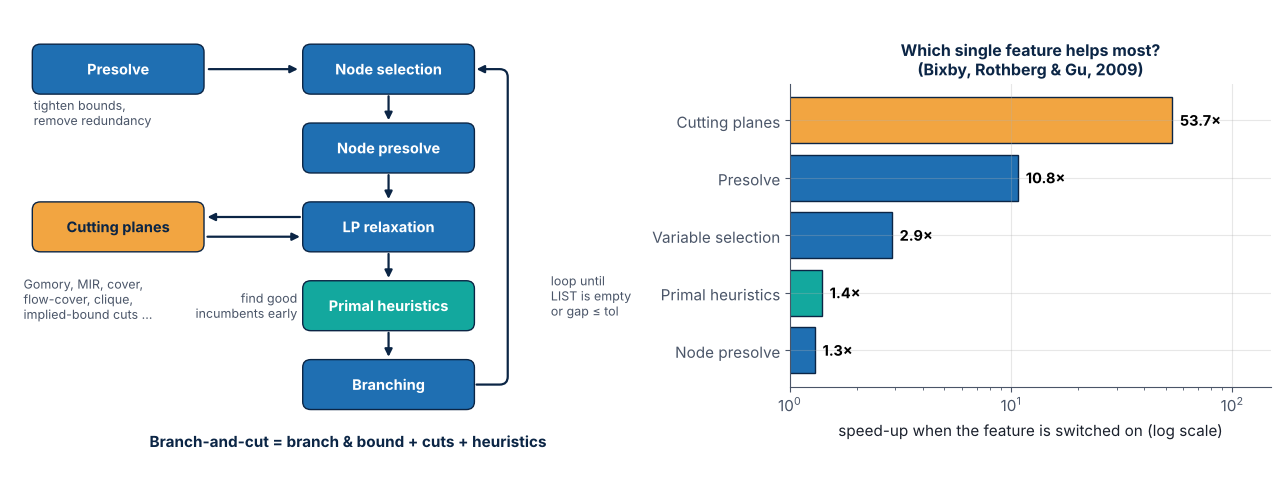

- **Solvers:** commercial: Gurobi, CPLEX, FICO Xpress, COPT · open-source: **HiGHS** (inside SciPy), SCIP, CBC. **Modeling languages:** Pyomo, GAMS, AMPL, JuMP.
- **Progress, 1988 → 2017:** algorithms ≈ **147,650×** faster, machines ≈ **17,120×** faster, combined ≈ **2.5 × 10⁹×**: a "typical" MILP that needed **124 years** in 1988 solves in about **1 second** (Bixby).
- **Milestones:** Dantzig, Fulkerson & Johnson's 42-city TSP (1954) · Gomory cuts (1958) · Land & Doig branch & bound (1960) · Dakin (1965) · Balas, disjunctive programming (1970s) · the branch-and-cut revolution (1990s).

## 29 · Formulation matters: practical tips

1. **Tight big-M:** use physical bounds (capacities, total feed), never "10⁶ just in case".
2. **Disaggregate:** $x_{ij} \le y_i\;\forall j$ (strong) instead of $\sum_j x_{ij} \le n\,y_i$ (weak).
3. Prefer **logic-based** constraints ($y_i \le z$) over aggregated ones ($\sum_i y_i \le n z$).
4. **Break symmetry:** for identical parallel units, add $y_1 \ge y_2 \ge \dots \ge y_n$.
5. **Bound & scale:** keep coefficients within a few orders of magnitude; give every variable sensible bounds.
6. **Help the solver:** supply a good starting incumbent (warm start) and set the gap tolerance consciously.

🔬 **Experiment:** facility location with 20 sites and 60 customers, **weak** vs. **strong** linking constraints. Same MILP optimum, very different relaxations:

In [ ]:
from scipy.sparse import lil_matrix
def facility_location(m=20, n=60, strong=True, seed=0):
    rng = np.random.default_rng(seed)
    Fc = rng.uniform(300, 600, m); P, Q = rng.uniform(0, 100, (m, 2)), rng.uniform(0, 100, (n, 2))
    cost = np.r_[Fc, 3 * np.linalg.norm(P[:, None] - Q[None], axis=2).ravel()]       # [y_i, x_ij]; x_ij = fraction of j served by i
    rows = n + (m * n if strong else m); A = lil_matrix((rows, m + m * n)); lo, hi = np.zeros(rows), np.zeros(rows)
    for j in range(n): A[j, m + np.arange(m) * n + j] = 1; lo[j] = hi[j] = 1                 # every customer fully served
    r = n
    for i in range(m):
        if strong:                                                                             # x_ij ≤ y_i  for every j
            for j in range(n): A[r, m + i * n + j] = 1; A[r, i] = -1; lo[r] = -np.inf; r += 1
        else:                                                                                  # Σ_j x_ij ≤ n·y_i
            A[r, m + i * n: m + (i + 1) * n] = 1; A[r, i] = -n; lo[r] = -np.inf; r += 1
    cons = LinearConstraint(A.tocsr(), lo, hi)
    lp = milp(cost, constraints=cons, integrality=np.zeros(len(cost)), bounds=Bounds(0, 1))
    ip = milp(cost, constraints=cons, integrality=np.r_[np.ones(m), np.zeros(m * n)], bounds=Bounds(0, 1))
    return lp.fun, ip.fun, ip.mip_node_count

for strong in [False, True]:
    z_lp, z_ip, nodes = facility_location(strong=strong)
    print(f"{'STRONG' if strong else 'WEAK  '}: LP bound = {z_lp:7.1f}   MILP = {z_ip:7.1f}   gap = {(z_ip - z_lp) / z_ip:5.1%}   B&B nodes = {nodes}")

WEAK  : LP bound =  2616.3   MILP =  5373.7   gap = 51.3%   B&B nodes = 65
STRONG: LP bound =  5373.7   MILP =  5373.7   gap =  0.0%   B&B nodes = 1


##  Check Your Understanding 6 — Cuts, solvers & formulations

*Try each question yourself first, then click to reveal the answer.*

**Q1.** Write two cover inequalities for $3x_1 + 4x_2 + 5x_3 + 6x_4 \le 10$, $x$ binary.

<details><summary><b> Show answer</b></summary>

$\{3, 4\}$: $5 + 6 = 11 > 10$ ⇒ $x_3 + x_4 \le 1$. $\{1, 2, 3\}$: $12 > 10$ ⇒ $x_1 + x_2 + x_3 \le 2$. Also $\{1,2,4\}$: $13 > 10$ ⇒ $x_1 + x_2 + x_4 \le 2$. ($\{2,4\}$ weighs exactly 10, so it is **not** a cover.)

</details>

**Q2.** An optimal tableau row reads $x_1 + 0.5\,s_1 - 1.25\,s_2 = 2.75$. Derive the Gomory cut.

<details><summary><b> Show answer</b></summary>

$x_1 + \lfloor 0.5\rfloor s_1 + \lfloor -1.25\rfloor s_2 \le \lfloor 2.75\rfloor \;\Rightarrow\; x_1 - 2\,s_2 \le 2$. Note that $\lfloor -1.25 \rfloor = -2$, **not** $-1$!

</details>

**Q3.** In the facility-location experiment both formulations reach the **same** MILP optimum. So why prefer the strong one?

<details><summary><b> Show answer</b></summary>

Its LP relaxation is much **tighter** (here the gap drops to 0 % and the LP is already integral), so B&B needs far fewer nodes. On large instances that is the difference between seconds and days, even though it has more constraints.

</details>

**Q4.** According to Bixby, Rothberg & Gu (2009), which single solver component gave the biggest speed-up?

<details><summary><b> Show answer</b></summary>

**Cutting planes** (≈ 54×), followed by presolve (≈ 11×). Of the cuts, Gomory mixed-integer cuts contributed the most.

</details>

## 30 · Summary & what's next

| Idea | Remember |
|---|---|
| MILP | linear model with continuous $x$ **and** integer $y$; non-convex, NP-hard, but very solvable in practice |
| Don't round | LP rounding can be infeasible or far from optimal |
| Toolkit | logic → CNF → $\sum y + \sum(1 - y) \ge 1$ · semi-continuous $Ly \le x \le Uy$ · fixed charge $\alpha y + \beta x$ · Glover products · piecewise-linear costs |
| Structures | knapsack · covering · assignment (TU!) · facility location · TSP (lazy cuts) · unit commitment · STN scheduling |
| Synthesis | superstructure + binaries for unit existence; **integer cuts** rank the alternatives |
| Bounds | the relaxation gives the bound (upper for max), any integer point gives the incumbent; gap = distance between them |
| Branch & bound | fathom by infeasibility, bound, integrality; depth-first finds incumbents, best-first proves optimality |
| Cuts | Chvátal–Gomory rounding, Gomory tableau cuts, covers; branch-and-cut = B&B + cuts + heuristics |
| Formulation | tight big-M, disaggregation, symmetry breaking: **a stronger relaxation beats a smaller model** |


**Further reading:** L.A. Wolsey, *Integer Programming*, 2nd ed., Wiley (2020) · L.T. Biegler, I.E. Grossmann & A.W. Westerberg, *Systematic Methods of Chemical Process Design*, Prentice Hall (1997) · I.E. Grossmann, *Advanced Optimization for Process Systems Engineering*, Cambridge (2021) · R. Bixby, *A Brief History of Linear and Mixed-Integer Programming Computation*, Documenta Math. (2012) · [HiGHS documentation](https://highs.dev)

<sub>Several examples are adapted from F. You, *Computational Optimization: Mixed-Integer Linear Programming*, Cornell University lecture notes.</sub>

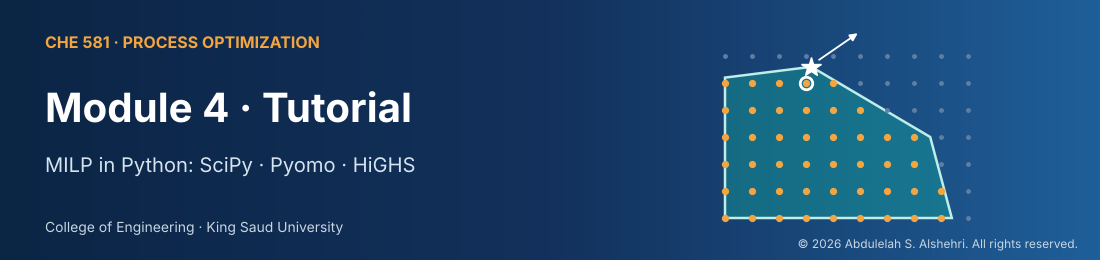

**CHE 581 · Process Optimization** | Module 4 · Tutorial | Instructor: **Dr. Abdulelah S. Alshehri** | College of Engineering — King Saud University

#  Tutorial 4 — Mixed-Integer Linear Programming in Python

This notebook turns every idea from the Module 4 lecture into **working code**. You will model, solve, analyze and *break* MILPs using three tools:

| Tool | What it is | Used for |
|---|---|---|
| `scipy.optimize.milp` | matrix-form MILP interface to the **HiGHS** solver | quick models, experiments, our own algorithms |
| **Pyomo** | algebraic modeling language (sets, parameters, variables, constraints) | readable process models |
| **HiGHS** | open-source LP/MILP solver (branch-and-cut) | solving everything |

**How to use this notebook**
1. Run the **Setup** cell first. On Colab it installs Pyomo + HiGHS in about 30 s.
2. Work through the parts in order. Each part ends with a **🧪 Your turn** exercise: try it in the empty cell, then open the hidden solution.
3. Change numbers, re-run, and **predict before you run**: that is how intuition for MILP is built.

| Part | Topic | Lecture slides |
|---|---|---|
| 1 | MILP in matrix form with SciPy; enumeration vs. solver | 1 – 4 |
| 2 | Algebraic modeling with Pyomo; reading a solver log | 4 – 5 |
| 3 | Fixed charges: should we build the plant? | 6 – 7 |
| 4 | Distillation-sequence synthesis with a superstructure | 16 – 18 |
| 5 | Technology pathway selection with economies of scale (piecewise linear) | 9 |
| 6 | Logic propositions → CNF → inequalities, automatically | 10 – 11 |
| 7 | Unit commitment of an industrial utility system | 14 |
| 8 | Build your own branch & bound | 19 – 24 |
| 9 | Cutting planes: Gomory and cover inequalities | 25 – 27 |
| 10 | Formulation strength: weak vs. strong, big-M | 11, 29 |
| 11 | Production sequencing with changeovers (TSP + lazy cuts) | 13 |
| 12 | Challenge problems | — |

## Part 0 · Setup

In [ ]:
# ⚙️ Setup: installs Pyomo + HiGHS if needed (≈ 30 s on Colab), then imports everything
import sys, subprocess, importlib
for pkg in ["pyomo", "highspy", "sympy", "networkx"]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import itertools, time, warnings, logging, os, re
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import pyomo.environ as pyo
from pyomo.opt import TerminationCondition as TC
from scipy.optimize import milp, linprog, LinearConstraint, Bounds
from scipy.sparse import lil_matrix
warnings.filterwarnings("ignore"); logging.getLogger("pyomo").setLevel(logging.ERROR)

NAVY, BLUE, TEAL, GOLD, RED, GRAY, GREEN = "#0B2545", "#1F6FB2", "#13A89E", "#F2A541", "#D64545", "#8D99AE", "#2E9E5B"
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})

def get_solver():
    """Return the first available MILP solver for Pyomo (HiGHS preferred)."""
    for name in ["appsi_highs", "highs", "cbc", "glpk"]:
        try:
            s = pyo.SolverFactory(name)
            if s.available(exception_flag=False):
                return s, name
        except Exception:
            pass
    raise RuntimeError("No MILP solver found: run  pip install highspy")

SOLVER, SOLVER_NAME = get_solver()

def solve(m, tee=False):
    """Solve Pyomo model m. Loads the solution if one is optimal; returns the termination condition as text."""
    res = SOLVER.solve(m, tee=tee, load_solutions=False)
    tc = res.solver.termination_condition
    if tc == TC.optimal:
        m.solutions.load_from(res)
    return str(tc)

from pyomo.version import version as PYOMO_VERSION
print(f"✅ Setup complete · Pyomo {PYOMO_VERSION} · solver = {SOLVER_NAME}")

✅ Setup complete · Pyomo 6.10.1 · solver = appsi_highs


###  A 60-second Pyomo primer

| Math | Pyomo |
|---|---|
| index set $I$ | `m.I = pyo.Set(initialize=[...])` |
| parameter $p_i$ | `m.p = pyo.Param(m.I, initialize={...}, mutable=True)` |
| $y_i \in \{0,1\}$, $x_i \ge 0$, $n \in \mathbb{Z}$ | `pyo.Var(m.I, domain=pyo.Binary)`, `NonNegativeReals`, `Integers` |
| $\max \sum_i p_i y_i$ | `m.obj = pyo.Objective(expr=sum(m.p[i]*m.y[i] for i in m.I), sense=pyo.maximize)` |
| one constraint per $i$ | `m.c = pyo.Constraint(m.I, rule=lambda m, i: ...)` |
| constraints added later (cuts!) | `m.cuts = pyo.ConstraintList(); m.cuts.add(expr)` |
| read a value | `pyo.value(m.y[i])` |
| fix / free a variable | `m.y[i].fix(1)` / `m.y[i].unfix()` |
| switch a constraint off / on | `m.c.deactivate()` / `m.c.activate()` |
| LP relaxation | `pyo.TransformationFactory("core.relax_integer_vars").create_using(m)` |

---
## Part 1 · MILP in matrix form with `scipy.optimize.milp`

`milp` solves
$$\min_x\; c^\top x \quad \text{s.t.}\quad b_l \le A x \le b_u,\qquad l \le x \le u,\qquad x_j \in \mathbb{Z} \text{ if integrality}_j = 1$$

- It always **minimizes**: to maximize, pass $-c$ and flip the sign of the result.
- A **binary** variable = integer variable with bounds $[0, 1]$.

### 1.1 Project selection (lecture slide 4)

In [ ]:
profit  = np.array([9, 5, 6, 4])            # $M
capital = np.array([6, 3, 5, 2])            # $M
budget  = 10
names   = ["factory LA", "factory SF", "warehouse LA", "warehouse SF"]

res = milp(c=-profit,                                                # milp MINIMIZES → negate to maximize
           constraints=LinearConstraint(capital[None, :], lb=-np.inf, ub=budget),
           integrality=np.ones(4),                                   # 1 = integer variable
           bounds=Bounds(0, 1))                                      # integer in [0, 1] = binary

print("status :", res.status, "-", res.message)
print("y      :", res.x)
print("profit : $", -res.fun, "M   →  build:", [n for n, yi in zip(names, res.x) if yi > 0.5])

status : 0 - Optimization terminated successfully. (HiGHS Status 7: Optimal)
y      : [0. 1. 1. 1.]
profit : $ 15.0 M   →  build: ['factory SF', 'warehouse LA', 'warehouse SF']


### 1.2 Why we need a solver: enumeration explodes

For $n$ binaries there are $2^n$ candidate solutions. Below, we enumerate **all** of them (vectorized NumPy) for random knapsacks and compare with HiGHS.

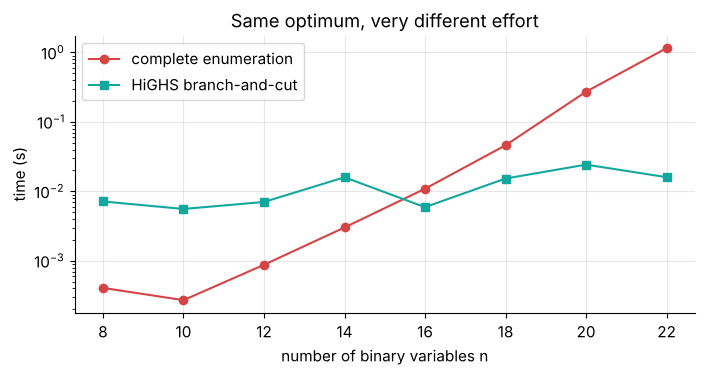

enumeration time grows ≈ 2^(0.89·n). Extrapolated to n = 50: 1 years


In [ ]:
def brute_force_knapsack(p, w, cap):
    n = len(p)
    S = ((np.arange(2 ** n)[:, None] >> np.arange(n)) & 1).astype(np.float32)   # all 2^n 0-1 vectors
    value = S @ p; value[S @ w > cap] = -np.inf                                     # infeasible → −∞
    k = int(np.argmax(value)); return value[k], S[k]

rng = np.random.default_rng(0); ns, t_bf, t_hi = [], [], []
for n in range(8, 23, 2):
    w = rng.integers(10, 60, n).astype(float); p = w + rng.integers(-5, 15, n); cap = 0.45 * w.sum()
    t0 = time.perf_counter(); z_bf, _ = brute_force_knapsack(p, w, cap); t_bf.append(time.perf_counter() - t0)
    t0 = time.perf_counter()
    r = milp(-p, constraints=LinearConstraint(w[None], -np.inf, cap), integrality=np.ones(n), bounds=Bounds(0, 1))
    t_hi.append(time.perf_counter() - t0); ns.append(n)
    assert abs(z_bf + r.fun) < 1e-6, "both methods must agree!"

slope = np.polyfit(ns, np.log2(t_bf), 1)[0]
plt.semilogy(ns, t_bf, "o-", color=RED, label="complete enumeration")
plt.semilogy(ns, t_hi, "s-", color=TEAL, label="HiGHS branch-and-cut")
plt.xlabel("number of binary variables n"); plt.ylabel("time (s)"); plt.legend(); plt.title("Same optimum, very different effort"); plt.show()
print(f"enumeration time grows ≈ 2^({slope:.2f}·n). Extrapolated to n = 50: {t_bf[-1] * 2 ** (slope * (50 - ns[-1])) / 86400 / 365:,.0f} years")

### 1.3 The LP relaxation and the rounding trap (lecture slide 3)

`integrality=0` turns the MILP into its **LP relaxation**.

In [ ]:
def compare_lp_milp(c, A, b, label):
    """max c·x s.t. A x <= b, x >= 0: LP relaxation, rounded LP and true MILP."""
    c, A, b = np.asarray(c, float), np.asarray(A, float), np.asarray(b, float)
    lp = milp(-c, constraints=LinearConstraint(A, -np.inf, b), integrality=np.zeros(len(c)))
    ip = milp(-c, constraints=LinearConstraint(A, -np.inf, b), integrality=np.ones(len(c)))
    print(f"── {label}")
    print(f"   LP relaxation : x = {lp.x.round(3)},  z = {-lp.fun:.3f}")
    for name, xr in [("round", np.round(lp.x)), ("round down", np.floor(lp.x + 1e-9))]:
        ok = np.all(A @ xr <= b + 1e-9)
        print(f"   {name:13s} : x = {xr},  " + (f"z = {c @ xr:.0f}" if ok else "INFEASIBLE ❌"))
    print(f"   MILP optimum  : x = {ip.x},  z = {-ip.fun:.0f}   (gap LP→IP = {(-lp.fun + ip.fun) / -ip.fun:.1%})")

compare_lp_milp([3, 4], [[5, 8]], [24], "Example 1: max 3x + 4y,  5x + 8y ≤ 24")
compare_lp_milp([3, 4], [[2, 6], [0, -1], [3, 1]], [27, -2, 19], "Example 2: max 3x1 + 4x2,  2x1 + 6x2 ≤ 27,  x2 ≥ 2,  3x1 + x2 ≤ 19")

── Example 1: max 3x + 4y,  5x + 8y ≤ 24
   LP relaxation : x = [4.8 0. ],  z = 14.400
   round         : x = [5. 0.],  INFEASIBLE ❌
   round down    : x = [4. 0.],  z = 12
   MILP optimum  : x = [3. 1.],  z = 13   (gap LP→IP = 10.8%)
── Example 2: max 3x1 + 4x2,  2x1 + 6x2 ≤ 27,  x2 ≥ 2,  3x1 + x2 ≤ 19
   LP relaxation : x = [5.438 2.688],  z = 27.062
   round         : x = [5. 3.],  INFEASIBLE ❌
   round down    : x = [5. 2.],  z = 23
   MILP optimum  : x = [4. 3.],  z = 24   (gap LP→IP = 12.8%)


###  Your turn 1 — add logic to project selection

Using `milp`, add these rules to the project-selection model and re-solve:
- (a) **at most one** warehouse may be built;
- (b) a warehouse may only be built in a city that also gets a **factory** ($y_3 \le y_1$, $y_4 \le y_2$).

*Predict first:* will the profit go up, down, or stay at 15?

In [ ]:
#  Your turn: write your code here, then compare with the solution below

<details><summary><b> Show solution</b></summary>

```python
A = np.array([capital,            # budget
              [0, 0, 1, 1],       # (a) y3 + y4 <= 1
              [-1, 0, 1, 0],      # (b) y3 - y1 <= 0
              [0, -1, 0, 1]])     #     y4 - y2 <= 0
ub = np.array([budget, 1, 0, 0])
r = milp(-profit, constraints=LinearConstraint(A, -np.inf, ub), integrality=np.ones(4), bounds=Bounds(0, 1))
print(r.x, -r.fun)   # → [1, 1, 0, 0], profit = 14: both factories, no warehouse
```
Profit **drops to 14**: the old optimum {SF factory, LA warehouse, SF warehouse} violates both rules. Adding constraints can never improve the optimum of a maximization.

</details>

---
## Part 2 · Algebraic modeling with Pyomo

Matrix form is fine for 4 variables but unreadable for 4,000. Pyomo lets us write the model **as we write the math**.

### 2.1 Project selection in Pyomo

In [ ]:
m = pyo.ConcreteModel("project selection")
m.I       = pyo.Set(initialize=names)
m.profit  = pyo.Param(m.I, initialize=dict(zip(names, [9, 5, 6, 4])))
m.capital = pyo.Param(m.I, initialize=dict(zip(names, [6, 3, 5, 2])))
m.B       = pyo.Param(initialize=10, mutable=True)                    # mutable → can be changed later

m.y      = pyo.Var(m.I, domain=pyo.Binary)
m.obj    = pyo.Objective(expr=sum(m.profit[i] * m.y[i] for i in m.I), sense=pyo.maximize)
m.budget = pyo.Constraint(expr=sum(m.capital[i] * m.y[i] for i in m.I) <= m.B)

print("status:", solve(m), "| profit =", pyo.value(m.obj))
for i in m.I:
    print(f"   {i:13s}  y = {pyo.value(m.y[i]):.0f}")

status: optimal | profit = 15.0
   factory LA     y = 0
   factory SF     y = 1
   warehouse LA   y = 1
   warehouse SF   y = 1


### 2.2 Reading a solver log

Let's watch HiGHS solve a harder **multi-constraint knapsack** (35 items, 3 resources). HiGHS prints its log at the C level, which notebooks do not capture, so we ask it to write the log to a file and then print the interesting part.

In [ ]:
import os, re
def solve_with_log(m, logfile="highs.log", max_rows=25):
    """Solve with HiGHS writing its log to a file, then print the branch-and-bound table and summary."""
    if SOLVER_NAME != "appsi_highs":
        return SOLVER.solve(m, tee=True)
    opt = pyo.SolverFactory("appsi_highs"); opt.highs_options = {"log_file": logfile, "log_to_console": False}
    if os.path.exists(logfile): os.remove(logfile)
    opt.solve(m)
    log = open(logfile).read()
    table = log[log.index("        Nodes"):log.index("Solving report")].rstrip().split("\n")
    print("\n".join(table[:4 + max_rows]) + ("\n   ..." if len(table) > 4 + max_rows else ""))
    for key in ["Status", "Primal bound", "Dual bound", "Gap", "Nodes", "Timing"]:
        hit = re.search(rf"\n\s+{key}\s+(.+)", log.split("Solving report")[1]); print(f"{key:13s}: {hit.group(1).strip()}")

rng = np.random.default_rng(3); n, R = 35, 3
W = rng.integers(10, 100, (R, n)); p = (W.sum(0) / R + rng.integers(0, 15, n)).round()
k = pyo.ConcreteModel(); k.I = pyo.RangeSet(n); k.R = pyo.RangeSet(R); k.x = pyo.Var(k.I, domain=pyo.Binary)
k.obj = pyo.Objective(expr=sum(float(p[i - 1]) * k.x[i] for i in k.I), sense=pyo.maximize)
k.cap = pyo.Constraint(k.R, rule=lambda k, r: sum(int(W[r - 1, i - 1]) * k.x[i] for i in k.I) <= int(0.5 * W[r - 1].sum()))
solve_with_log(k)

        Nodes      |    B&B Tree     |            Objective Bounds              |  Dynamic Constraints |       Work      
Src  Proc. InQueue |  Leaves   Expl. | BestBound       BestSol              Gap |   Cuts   InLp Confl. | LpIters     Time

 z       0       0         0   0.00%   inf             -0                 Large        0      0      0         0     0.0s
 J       0       0         0   0.00%   inf             86                 Large        0      0      0         0     0.0s
 S       0       0         0   0.00%   2159            1079             100.09%        0      0      0         0     0.0s
         0       0         0   0.00%   1147.054623     1079               6.31%        0      0      2         7     0.0s
 L       0       0         0   0.00%   1145.536731     1132               1.20%      206     11      6        33     0.0s
 L       0       0         0   0.00%   1145.536731     1135               0.93%      206     11      6       288     0.1s
 T     300      20     

**How to read the log** (maximization):

| Column | Meaning | Lecture concept |
|---|---|---|
| `Src` | how the row was produced: `S` = LP solve, `R` `J` `L` `H` = heuristics, `T` = node evaluated, `B` = branching | primal heuristics |
| `Proc.` / `InQueue` | nodes processed / still open | B&B tree and LIST |
| `BestBound` | best objective still possible (from LP relaxations + cuts) | relaxation bound |
| `BestSol` | best integer solution found so far | incumbent $z_I$ |
| `Gap` | $(\text{BestBound} - \text{BestSol}) / \lvert\text{BestSol}\rvert$ | optimality gap |
| `Cuts` / `InLp` | cutting planes generated / currently in the LP | branch-and-cut |

>  Watch the two columns converge: `BestSol` **rises** as better incumbents are found and `BestBound` **falls** as nodes are explored. The solver stops when the gap is below its tolerance (0.01 % by default in HiGHS).

### 2.3 Logic constraints, fixing variables, switching constraints off

In [ ]:
m.logic = pyo.ConstraintList()
m.logic.add(m.y["warehouse LA"] + m.y["warehouse SF"] <= 1)          # at most one warehouse
m.logic.add(m.y["warehouse SF"] <= m.y["factory SF"])                # warehouse only where a factory is
solve(m); print("with logic          :", {i: int(pyo.value(m.y[i])) for i in m.I}, "profit =", pyo.value(m.obj))

m.y["factory LA"].fix(0)                                             # what if LA is ruled out?
solve(m); print("+ no LA factory     :", {i: int(pyo.value(m.y[i])) for i in m.I}, "profit =", pyo.value(m.obj))

m.y["factory LA"].unfix(); m.logic.deactivate()                      # back to the original model
solve(m); print("original model again:", {i: int(pyo.value(m.y[i])) for i in m.I}, "profit =", pyo.value(m.obj))

with logic          : {'factory LA': 1, 'factory SF': 1, 'warehouse LA': 0, 'warehouse SF': 0} profit = 14.0


+ no LA factory     : {'factory LA': 0, 'factory SF': 1, 'warehouse LA': 1, 'warehouse SF': 0} profit = 11.0


original model again: {'factory LA': 0, 'factory SF': 1, 'warehouse LA': 1, 'warehouse SF': 1} profit = 15.0


### 2.4 Sensitivity: the value of capital is a staircase

With a mutable parameter we can re-solve for many budgets. We compare against the **LP relaxation**, created with Pyomo's `core.relax_integer_vars` transformation.

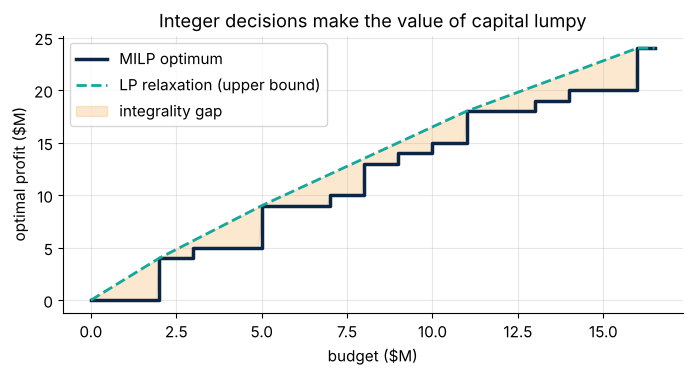

In [ ]:
budgets = np.arange(0, 16.6, 0.1); z_ip, z_lp = [], []
for Bv in budgets:
    m.B = Bv
    solve(m); z_ip.append(pyo.value(m.obj))
    r = pyo.TransformationFactory("core.relax_integer_vars").create_using(m)   # copy with 0 ≤ y ≤ 1
    solve(r); z_lp.append(pyo.value(r.obj))
m.B = 10

plt.step(budgets, z_ip, where="post", color=NAVY, lw=2.5, label="MILP optimum")
plt.plot(budgets, z_lp, "--", color=TEAL, lw=2, label="LP relaxation (upper bound)")
plt.fill_between(budgets, z_ip, z_lp, step=None, color=GOLD, alpha=0.25, label="integrality gap")
plt.xlabel("budget ($M)"); plt.ylabel("optimal profit ($M)"); plt.legend(); plt.title("Integer decisions make the value of capital lumpy"); plt.show()

>  The LP curve is **concave and smooth**: every extra dollar earns the best available "fraction of a project". The MILP curve **jumps**: an extra 1M dollars is worth nothing until a whole new combination becomes affordable. That is why shadow prices from the LP relaxation are unreliable for discrete decisions.

###  Your turn 2 — "exactly one factory"

Add the rule *"exactly one factory must be built"* to the Pyomo model `m`, solve for budget = 10, then **deactivate** the rule again.

In [ ]:
#  Your turn: write your code here, then compare with the solution below

<details><summary><b> Show solution</b></summary>

```python
m.one_factory = pyo.Constraint(expr=m.y["factory LA"] + m.y["factory SF"] == 1)
solve(m); print({i: int(pyo.value(m.y[i])) for i in m.I}, pyo.value(m.obj))   # SF factory + both warehouses: 15
m.one_factory.deactivate()
```
The original optimum already uses exactly one factory, so nothing changes. Try `== 2` instead: profit falls to 14.

</details>

---
## Part 3 · Fixed charges: should we build the plant? (lecture slides 6 – 7)

$$\max\; -4y - 0.15x_1 + (p_B - 0.07)\,x_2 \quad\text{s.t.}\quad x_1 = 1.4\,x_2,\quad x_1 \le 80\,y,\quad x_2 \le D_B\,y,\quad y\in\{0,1\}$$

### 3.1 A reusable model function

In [ ]:
def plant_model(price_B=0.35, demand_B=50.0, avail_A=80.0, fixed=4.0):
    m = pyo.ConcreteModel()
    m.x1 = pyo.Var(domain=pyo.NonNegativeReals)              # A consumed   (M lb/yr)
    m.x2 = pyo.Var(domain=pyo.NonNegativeReals)              # B produced   (M lb/yr)
    m.y  = pyo.Var(domain=pyo.Binary)                        # build the plant?
    m.profit = pyo.Objective(expr=price_B * m.x2 - 0.15 * m.x1 - (fixed * m.y + 0.01 * m.x2) - 0.06 * m.x2,
                             sense=pyo.maximize)
    m.yield_ = pyo.Constraint(expr=m.x1 == 1.4 * m.x2)
    m.availA = pyo.Constraint(expr=m.x1 <= avail_A * m.y)    # semi-continuous links (big-M = physical limits)
    m.demB   = pyo.Constraint(expr=m.x2 <= demand_B * m.y)
    return m

m = plant_model(); solve(m)
print(f"build? y = {pyo.value(m.y):.0f}   B = {pyo.value(m.x2):.1f} M lb/yr   profit = {pyo.value(m.profit):.2f} $M/yr")

build? y = 0   B = 0.0 M lb/yr   profit = 0.00 $M/yr


### 3.2 When does the plant pay off?

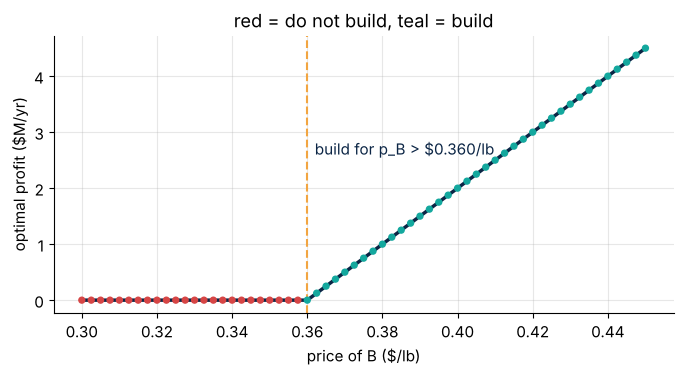

break-even price: 4 = (p_B − 0.28) · 50  →  p_B = 0.36 $/lb


In [ ]:
prices = np.linspace(0.30, 0.45, 61); prof, build = [], []
for pB in prices:
    m = plant_model(price_B=pB); solve(m); prof.append(pyo.value(m.profit)); build.append(pyo.value(m.y))
prof, build = np.array(prof), np.array(build)
pB_star = prices[np.argmax(build > 0.5)]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(prices, prof, color=NAVY, lw=2.5)
ax.scatter(prices, prof, c=np.where(build > 0.5, TEAL, RED), s=18, zorder=3)
ax.axvline(pB_star, color=GOLD, ls="--"); ax.text(pB_star + 0.002, 2.6, f"build for p_B > ${pB_star:.3f}/lb", color=NAVY)
ax.set(xlabel="price of B ($/lb)", ylabel="optimal profit ($M/yr)", title="red = do not build, teal = build")
plt.show()
print("break-even price: 4 = (p_B − 0.28) · 50  →  p_B = 0.36 $/lb")

### 3.3 Two candidate processes compete for raw material A (slide 11 exercise)

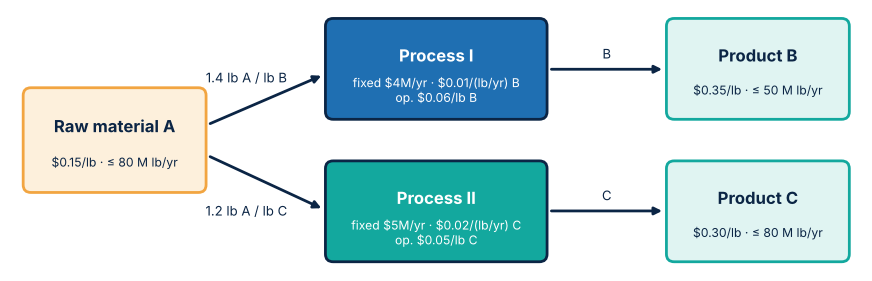

In [ ]:
def two_process_model(pB=0.35, pC=0.30, at_most_one=False, avail_A=80.0):
    m = pyo.ConcreteModel()
    m.P = pyo.Set(initialize=["I", "II"])
    a     = {"I": 1.4, "II": 1.2}          # lb A per lb product
    price = {"I": pB,  "II": pC}           # $/lb product
    op    = {"I": 0.06, "II": 0.05}        # operating cost $/lb product
    fix   = {"I": 4.0,  "II": 5.0}         # fixed investment $M/yr
    var   = {"I": 0.01, "II": 0.02}        # variable investment $/(lb/yr)
    dem   = {"I": 50.0, "II": 80.0}        # demand M lb/yr
    m.x = pyo.Var(m.P, domain=pyo.NonNegativeReals)                       # product made (M lb/yr)
    m.y = pyo.Var(m.P, domain=pyo.Binary)
    m.profit = pyo.Objective(sense=pyo.maximize, expr=sum(
        (price[p] - op[p] - var[p] - 0.15 * a[p]) * m.x[p] - fix[p] * m.y[p] for p in m.P))
    m.A   = pyo.Constraint(expr=sum(a[p] * m.x[p] for p in m.P) <= avail_A)   # shared raw material
    m.dem = pyo.Constraint(m.P, rule=lambda m, p: m.x[p] <= dem[p] * m.y[p])
    if at_most_one:
        m.one = pyo.Constraint(expr=sum(m.y[p] for p in m.P) <= 1)
    return m

m = two_process_model(); solve(m)
print("base case:", {p: (int(pyo.value(m.y[p])), round(pyo.value(m.x[p]), 1)) for p in m.P}, f"profit = {pyo.value(m.profit):.2f} $M/yr")

base case: {'I': (0, 0.0), 'II': (0, 0.0)} profit = 0.00 $M/yr


With the slide data **neither** process pays off. Margins per lb: Process I: $0.35 - 0.06 - 0.01 - 1.4(0.15) = 0.07$; Process II: $0.30 - 0.05 - 0.02 - 1.2(0.15) = 0.05$, too small to recover the fixed charges.
Let's map the optimal decision over a range of product prices:

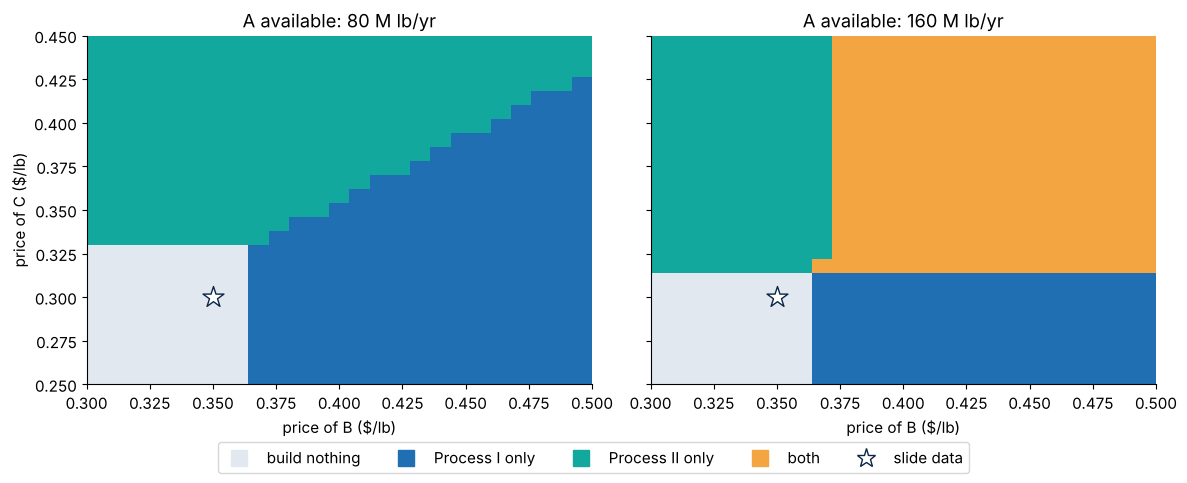

In [ ]:
def decision_map(at_most_one=False, avail_A=80.0, N=25):
    pBs, pCs = np.linspace(0.30, 0.50, N), np.linspace(0.25, 0.45, N); D = np.zeros((N, N))
    for i, pC in enumerate(pCs):
        for j, pB in enumerate(pBs):
            m = two_process_model(pB, pC, at_most_one, avail_A); solve(m)
            D[i, j] = round(pyo.value(m.y["I"])) + 2 * round(pyo.value(m.y["II"]))   # 0 none, 1 I, 2 II, 3 both
    return pBs, pCs, D

from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#E2E8F0", BLUE, TEAL, GOLD]); labels = ["build nothing", "Process I only", "Process II only", "both"]
def show_maps(at_most_one=False):
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
    for ax, availA in zip(axs, [80, 160]):
        pBs, pCs, D = decision_map(at_most_one, availA)
        ax.imshow(D, origin="lower", extent=[pBs[0], pBs[-1], pCs[0], pCs[-1]], cmap=cmap, vmin=-0.5, vmax=3.5, aspect="auto")
        ax.scatter([0.35], [0.30], marker="*", s=250, color="white", edgecolor=NAVY)
        ax.set(xlabel="price of B ($/lb)", title=f"A available: {availA} M lb/yr" + ("  (one process max)" if at_most_one else "")); ax.grid(False)
    axs[0].set_ylabel("price of C ($/lb)")
    handles = [plt.Line2D([], [], marker="s", ls="", ms=11, color=cmap(k)) for k in range(4)] + \
              [plt.Line2D([], [], marker="*", ls="", ms=14, mfc="white", mec=NAVY)]
    fig.legend(handles, labels + ["slide data"], loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.06))
    plt.tight_layout(); plt.show()

show_maps()

>  With the slide's **80 M lb/yr** of A, the two processes compete for raw material: Process I at full demand already uses 70, so building **both** is never worth the second fixed charge. The boundary between "I only" and "II only" is where the better *single* process switches. Double the supply (right) and a gold **"both"** region appears once both margins are high. An LP would never give you this map: it would happily build "0.4 of a plant".

###  Your turn 3 — a shared site

Only **one** process fits on the available plot of land. Re-draw the decision maps with `at_most_one=True`. What happens to the gold "both" region in the 160 M lb/yr case, and what replaces it?

In [ ]:
#  Your turn: write your code here, then compare with the solution below

<details><summary><b> Show solution</b></summary>

```python
show_maps(at_most_one=True)
```
The gold "both" region disappears. It is split between "I only" and "II only" along the line where the **better single process** switches. The 80 M lb/yr map does not change at all, because "both" was never optimal there. The site constraint is only *active* when raw material is plentiful.

</details>

---
## Part 4 · Distillation-sequence synthesis (lecture slides 16 – 18)

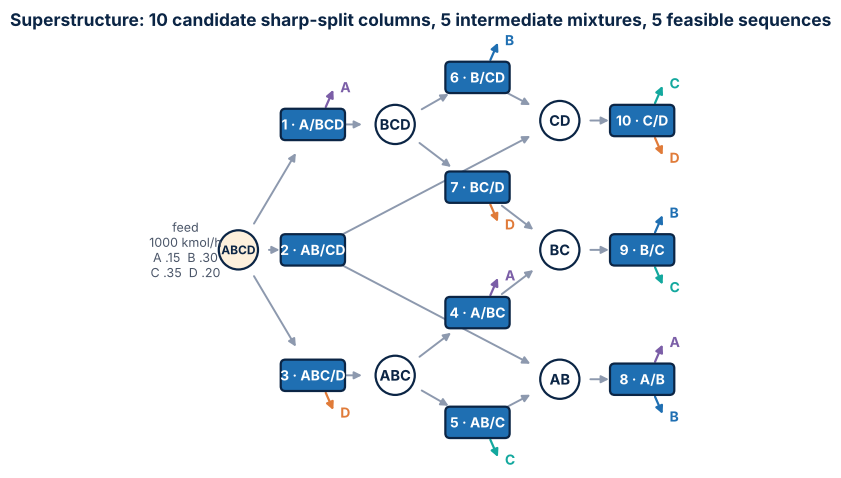

### 4.1 The superstructure model in Pyomo
Sharp splits make the split fractions $\xi$ simple functions of the feed composition, so the model stays **linear**.

In [ ]:
COLS = {  # k: (top, bottom, alpha [k$/yr], beta [k$·h/(kmol·yr)], K [10^6 kJ/kmol])
    1: ("A", "BCD", 145, 0.42, 0.028), 2: ("AB", "CD", 52, 0.12, 0.042), 3: ("ABC", "D", 76, 0.25, 0.054),
    4: ("A", "BC", 25, 0.78, 0.024),   5: ("AB", "C", 44, 0.11, 0.039),  6: ("B", "CD", 38, 0.14, 0.040),
    7: ("BC", "D", 66, 0.21, 0.047),   8: ("A", "B", 112, 0.39, 0.022),  9: ("B", "C", 37, 0.08, 0.036),
    10: ("C", "D", 58, 0.19, 0.044)}
Z0 = {"A": 0.15, "B": 0.30, "C": 0.35, "D": 0.20}

def sequencing_model(z=Z0, F=1000.0, CH=34.0, CC=1.3):
    feed = lambda k: COLS[k][0] + COLS[k][1]
    xi   = lambda k, part: sum(z[c] for c in part) / sum(z[c] for c in feed(k))       # sharp-split fraction
    MIX  = ["BCD", "ABC", "AB", "BC", "CD"]                                            # intermediate mixtures
    m = pyo.ConcreteModel()
    m.K = pyo.Set(initialize=list(COLS))
    m.F = pyo.Var(m.K, bounds=(0, F))                   # feed flow to column k (kmol/h)
    m.y = pyo.Var(m.K, domain=pyo.Binary)               # column k exists?
    m.invest  = pyo.Expression(expr=sum(COLS[k][2] * m.y[k] + COLS[k][3] * m.F[k] for k in m.K))
    m.utility = pyo.Expression(expr=(CH + CC) * sum(COLS[k][4] * m.F[k] for k in m.K))
    m.cost    = pyo.Objective(expr=m.invest + m.utility)                                # k$/yr
    m.feed    = pyo.Constraint(expr=sum(m.F[k] for k in m.K if feed(k) == "ABCD") == F)
    m.balance = pyo.Constraint(MIX, rule=lambda m, mix:
        sum(m.F[k] for k in m.K if feed(k) == mix) == sum(xi(k, mix) * m.F[k] for k in m.K if mix in COLS[k][:2]))
    m.exists  = pyo.Constraint(m.K, rule=lambda m, k: m.F[k] <= F * m.y[k])           # big-M = total feed
    m.cuts    = pyo.ConstraintList()                                                    # for integer cuts later
    return m

def report(m):
    on = [k for k in m.K if pyo.value(m.y[k]) > 0.5]
    seq = ", ".join(f"{COLS[k][0]}/{COLS[k][1]} ({pyo.value(m.F[k]):.0f})" for k in on)
    return on, seq

m = sequencing_model(); solve(m); on, seq = report(m)
print("active columns (flow, kmol/h):", seq)
print(f"investment = {pyo.value(m.invest):7.1f} k$/yr\nutilities  = {pyo.value(m.utility):7.1f} k$/yr\nTOTAL      = {pyo.value(m.cost):7.1f} k$/yr")

active columns (flow, kmol/h): AB/CD (1000), A/B (450), C/D (550)
investment =   622.0 k$/yr
utilities  =  2686.3 k$/yr
TOTAL      =  3308.3 k$/yr


>  Utilities make up **~80 %** of the cost. That is why the sequence that processes the least total flow wins.

### 4.2 Rank **all** sequences with integer cuts

We forbid each design found with $\sum_{k \in B} y_k \le \lvert B\rvert - 1$, where $B$ is its set of active columns.
⚠️ Why not the full cut $\sum_{B} y_k - \sum_{N} y_k \le \lvert B\rvert - 1$ from the lecture? It forbids only that *exact* 0-1 vector, so the solver could return "the same design + one idle column" ($y_k = 1$, $F_k = 0$) as the "next best". The active-set cut also excludes those dominated supersets.

5 feasible sequences found, then the model became infeasible ✔

#1:  3.308 M$/yr   AB/CD (1000), A/B (450), C/D (550)
#2:  3.927 M$/yr   A/BCD (1000), B/CD (850), C/D (550)
#3:  4.103 M$/yr   ABC/D (1000), AB/C (800), A/B (450)
#4:  4.123 M$/yr   A/BCD (1000), BC/D (850), B/C (650)
#5:  4.474 M$/yr   ABC/D (1000), A/BC (800), B/C (650)


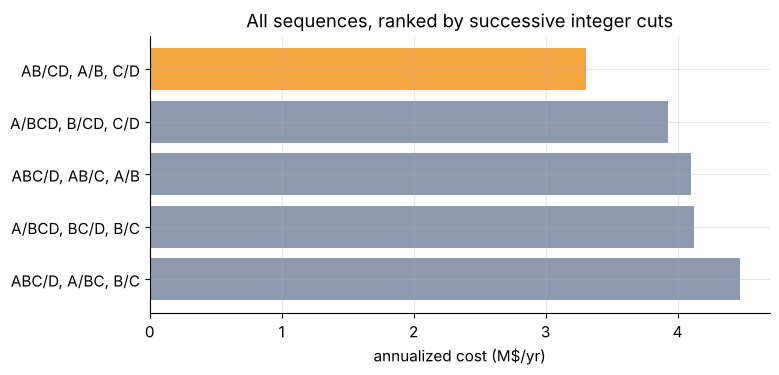

In [ ]:
m = sequencing_model(); ranking = []
while solve(m) == "optimal" and len(ranking) < 20:
    on, seq = report(m); ranking.append((pyo.value(m.cost), seq))
    m.cuts.add(sum(m.y[k] for k in on) <= len(on) - 1)          # "not all of these columns together"
print(f"{len(ranking)} feasible sequences found, then the model became infeasible ✔\n")
for r_, (c_, s_) in enumerate(ranking, 1):
    print(f"#{r_}: {c_ / 1000:6.3f} M$/yr   {s_}")

plt.barh(range(len(ranking))[::-1], [c / 1000 for c, _ in ranking], color=[GOLD] + [GRAY] * (len(ranking) - 1))
plt.yticks(range(len(ranking))[::-1], [re.sub(r" \(\d+\)", "", s) for _, s in ranking]); plt.xlabel("annualized cost (M$/yr)")
plt.title("All sequences, ranked by successive integer cuts"); plt.show()

### 4.3 How does the feed composition change the best sequence?

We vary the fractions of the lightest (A) and heaviest (D) components and keep the B : C ratio fixed.

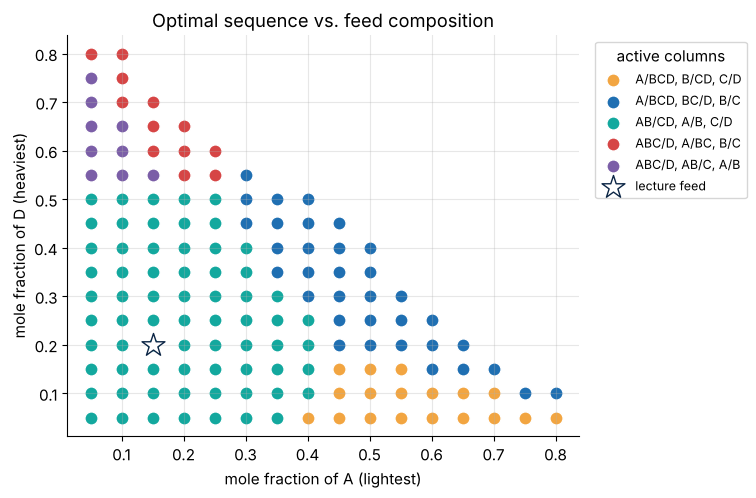

In [ ]:
grid = np.linspace(0.05, 0.80, 16); pts, labels = [], []
for zA in grid:
    for zD in grid:
        if zA + zD > 0.90: continue
        rest = 1 - zA - zD; z = {"A": zA, "B": rest * 0.30 / 0.65, "C": rest * 0.35 / 0.65, "D": zD}
        m = sequencing_model(z); solve(m); on, _ = report(m)
        pts.append((zA, zD)); labels.append(", ".join(f"{COLS[k][0]}/{COLS[k][1]}" for k in on))

uniq = sorted(set(labels)); colors = [GOLD, BLUE, TEAL, RED, "#7B5EA7"]
plt.figure(figsize=(6.6, 5.2))
for u, col in zip(uniq, colors):
    P = np.array([p for p, l in zip(pts, labels) if l == u]); plt.scatter(P[:, 0], P[:, 1], s=90, color=col, label=u, edgecolor="white")
plt.scatter([0.15], [0.20], marker="*", s=300, color="white", edgecolor=NAVY, zorder=5, label="lecture feed")
plt.xlabel("mole fraction of A (lightest)"); plt.ylabel("mole fraction of D (heaviest)"); plt.legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.02, 1), title="active columns")
plt.title("Optimal sequence vs. feed composition"); plt.show()

> The MILP rediscovers classic **separation heuristics**: *remove the most plentiful component first* (A-rich → A/BCD first; D-rich → ABC/D first) and *favor equimolar splits* (AB/CD in the middle).

###  Your turn 4 — a column you cannot build

The AB/CD split (column 2) turns out to need an exotic, corrosion-resistant alloy and is ruled out. Fix $y_2 = 0$ and re-solve. What is the new optimum, and how much does losing the option cost per year?

In [ ]:
#  Your turn: write your code here, then compare with the solution below

<details><summary><b> Show solution</b></summary>

```python
m = sequencing_model(); m.y[2].fix(0); solve(m)
print(report(m)[1], pyo.value(m.cost))     # A/BCD → B/CD → C/D : 3927.4 k$/yr
print("cost of losing column 2:", pyo.value(m.cost) - 3308.3, "k$/yr")   # ≈ 619 k$/yr
```

</details>

---
## Part 5 · Technology pathway selection with economies of scale (lecture slide 9)

A new complex must deliver **≥ 150 t/d methanol** and **≥ 20 t/d hydrogen**. Syngas can come from natural gas (SMR or ATR) or from biomass gasification, and a **carbon price** $\tau$ penalizes CO₂.

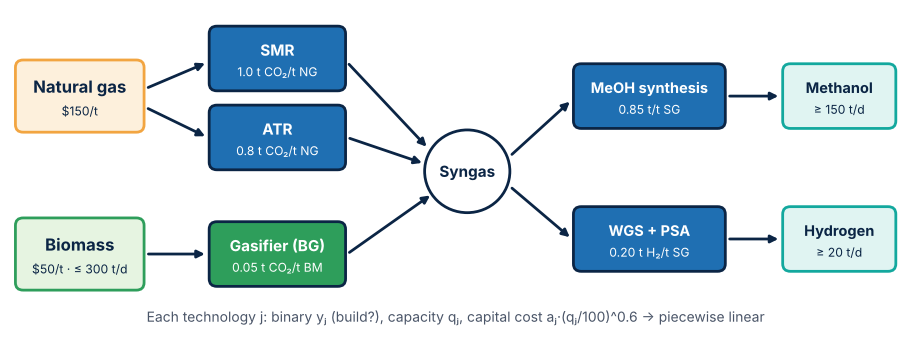

Capital cost follows the six-tenths rule $f_j(q) = a_j (q/100)^{0.6}$ (k USD/day, $q$ in t/d of feed), which we approximate with **piecewise-linear segments** (one binary per segment):

$$\text{capex}_j = \sum_p \big(\alpha_{jp} z_{jp} + \beta_{jp} y_{jp}\big),\quad \sum_p y_{jp} = y_j,\quad q_j = \sum_p z_{jp},\quad B_{p-1} y_{jp} \le z_{jp} \le B_p y_{jp}$$

plus mass balances $p_i - s_i + \sum_j M_{ij} w_j = 0$, capacity $w_j \le q_j$, and $Q^L y_j \le q_j$.

In [ ]:
MATS   = ["NG", "BM", "SG", "MeOH", "H2"]
PRICE  = {"NG": 0.15, "BM": 0.05}                     # k$/t raw material
AVAIL  = {"NG": 2000, "BM": 300}                      # t/d
DEMAND = {"MeOH": 150, "H2": 20}                      # t/d
TECH = {  # name: ({material: t per t feed}, a = capex k$/d at 100 t/d, opex k$/t feed, CO2 t/t feed)
    "SMR": ({"NG": -1, "SG": 2.10}, 26, 0.03, 1.00),
    "ATR": ({"NG": -1, "SG": 2.00}, 26, 0.05, 0.80),
    "BG":  ({"BM": -1, "SG": 0.75}, 16, 0.03, 0.05),
    "MS":  ({"SG": -1, "MeOH": 0.85}, 35, 0.02, 0.02),
    "WGS": ({"SG": -1, "H2": 0.20}, 15, 0.03, 0.30)}
QL, QU = 20, 500                                      # t/d feed

def capex(j, q):  return TECH[j][1] * (np.asarray(q, float) / 100) ** 0.6

def pathway_model(tau=0.0, nseg=6):
    Bk = np.linspace(0, QU, nseg + 1)                                          # breakpoints
    al = {(j, p): (capex(j, Bk[p]) - capex(j, Bk[p - 1])) / (Bk[p] - Bk[p - 1]) for j in TECH for p in range(1, nseg + 1)}
    be = {(j, p): capex(j, Bk[p]) - al[j, p] * Bk[p] for j in TECH for p in range(1, nseg + 1)}
    m = pyo.ConcreteModel()
    m.J, m.I, m.P = pyo.Set(initialize=list(TECH)), pyo.Set(initialize=MATS), pyo.RangeSet(1, nseg)
    m.tau = pyo.Param(initialize=tau, mutable=True)                            # carbon price (k$/t CO2)
    m.y  = pyo.Var(m.J, domain=pyo.Binary)                                     # build technology j?
    m.ys = pyo.Var(m.J, m.P, domain=pyo.Binary)                                # ... in size segment p?
    m.z  = pyo.Var(m.J, m.P, domain=pyo.NonNegativeReals)
    m.q  = pyo.Var(m.J, domain=pyo.NonNegativeReals)                           # capacity (t/d feed)
    m.w  = pyo.Var(m.J, domain=pyo.NonNegativeReals)                           # throughput (t/d feed)
    m.pur = pyo.Var(m.I, domain=pyo.NonNegativeReals); m.sal = pyo.Var(m.I, domain=pyo.NonNegativeReals)
    m.capex = pyo.Expression(m.J, rule=lambda m, j: sum(al[j, p] * m.z[j, p] + be[j, p] * m.ys[j, p] for p in m.P))
    m.co2   = pyo.Expression(expr=sum(TECH[j][3] * m.w[j] for j in m.J))
    m.cost  = pyo.Objective(expr=sum(m.capex[j] + TECH[j][2] * m.w[j] for j in m.J)
                                 + sum(PRICE[i] * m.pur[i] for i in PRICE) + m.tau * m.co2)
    m.seg   = pyo.Constraint(m.J, rule=lambda m, j: sum(m.ys[j, p] for p in m.P) == m.y[j])
    m.qdef  = pyo.Constraint(m.J, rule=lambda m, j: m.q[j] == sum(m.z[j, p] for p in m.P))
    m.lo    = pyo.Constraint(m.J, m.P, rule=lambda m, j, p: m.z[j, p] >= Bk[p - 1] * m.ys[j, p])
    m.hi    = pyo.Constraint(m.J, m.P, rule=lambda m, j, p: m.z[j, p] <= Bk[p] * m.ys[j, p])
    m.qmin  = pyo.Constraint(m.J, rule=lambda m, j: m.q[j] >= QL * m.y[j])
    m.cap   = pyo.Constraint(m.J, rule=lambda m, j: m.w[j] <= m.q[j])
    m.bal   = pyo.Constraint(m.I, rule=lambda m, i: m.pur[i] - m.sal[i] + sum(TECH[j][0].get(i, 0) * m.w[j] for j in m.J) == 0)
    for i in MATS:                                                             # raw / product / intermediate
        if i in AVAIL:    m.sal[i].fix(0); m.pur[i].setub(AVAIL[i])
        elif i in DEMAND: m.pur[i].fix(0); m.sal[i].setlb(DEMAND[i])
        else:             m.pur[i].fix(0); m.sal[i].fix(0)
    return m

for tau in [0.0, 0.2]:
    m = pathway_model(tau); solve(m)
    built = {j: round(pyo.value(m.q[j])) for j in m.J if pyo.value(m.y[j]) > 0.5}
    print(f"carbon price {tau * 1000:3.0f} $/t → cost {pyo.value(m.cost):6.1f} k$/d, CO2 {pyo.value(m.co2):5.1f} t/d, capacities (t/d feed): {built}")

carbon price   0 $/t → cost  124.4 k$/d, CO2 165.2 t/d, capacities (t/d feed): {'SMR': 132, 'MS': 176, 'WGS': 100}


carbon price 200 $/t → cost  151.2 k$/d, CO2  73.0 t/d, capacities (t/d feed): {'SMR': 25, 'BG': 300, 'MS': 176, 'WGS': 100}


### 5.2 Carbon-price sweep: when does biomass enter?

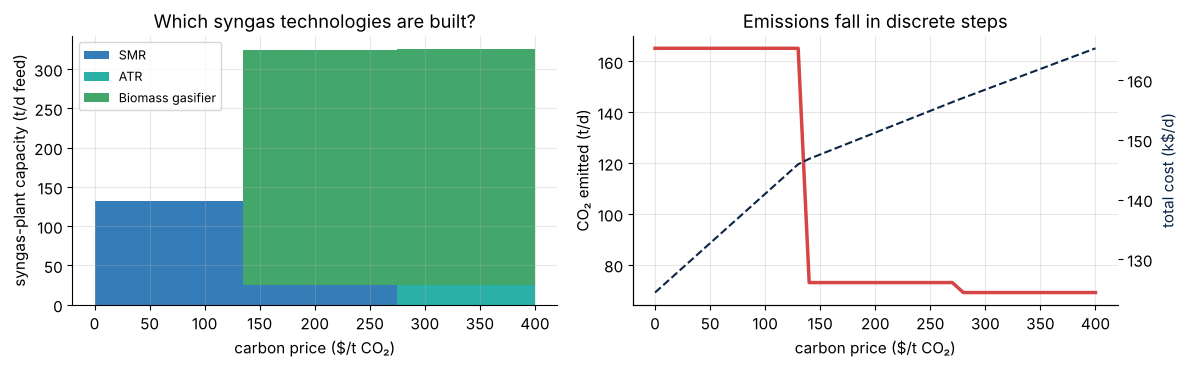

In [ ]:
taus = np.arange(0, 0.41, 0.01); m = pathway_model(); rows = []
for tau in taus:
    m.tau = tau; solve(m)                                   # re-use the model: only the mutable parameter changes
    rows.append([pyo.value(m.cost), pyo.value(m.co2)] + [pyo.value(m.q[j]) * (pyo.value(m.y[j]) > 0.5) for j in ["SMR", "ATR", "BG"]])
rows = np.array(rows)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].stackplot(taus * 1000, rows[:, 2], rows[:, 3], rows[:, 4], colors=[BLUE, TEAL, GREEN], labels=["SMR", "ATR", "Biomass gasifier"], alpha=0.9, step="mid")
ax[0].set(xlabel="carbon price ($/t CO₂)", ylabel="syngas-plant capacity (t/d feed)", title="Which syngas technologies are built?")
ax[0].legend(loc="upper left", fontsize=9)
ax[1].plot(taus * 1000, rows[:, 1], color=RED, lw=2.5); ax[1].set(xlabel="carbon price ($/t CO₂)", ylabel="CO₂ emitted (t/d)", title="Emissions fall in discrete steps")
ax2 = ax[1].twinx(); ax2.plot(taus * 1000, rows[:, 0], color=NAVY, lw=1.5, ls="--"); ax2.set_ylabel("total cost (k$/d)", color=NAVY); ax2.grid(False)
plt.tight_layout(); plt.show()

>  **Economies of scale shape the answer.** Biomass is limited to 300 t/d, so going green means building **two** syngas plants: a big gasifier plus a *small* NG unit, which is expensive per tonne under a concave cost curve. The switch therefore needs a carbon price of about **140 USD/t**, and at about **280 USD/t** the residual NG unit changes from SMR to the lower-emission ATR.

### 5.3 How many segments do we need?

 segments | objective | capex (PWL) | capex (true f) | error


      1   |   105.05  |     58.31   |      94.88     | -38.5%


      2   |   123.68  |     76.94   |      94.88     | -18.9%


      3   |   135.87  |     89.13   |      94.88     |  -6.1%


      4   |   139.52  |     92.77   |      94.88     |  -2.2%


      6   |   140.95  |     94.20   |      94.88     |  -0.7%


     10   |   141.37  |     94.63   |      94.88     |  -0.3%


     16   |   141.52  |     94.77   |      94.88     |  -0.1%


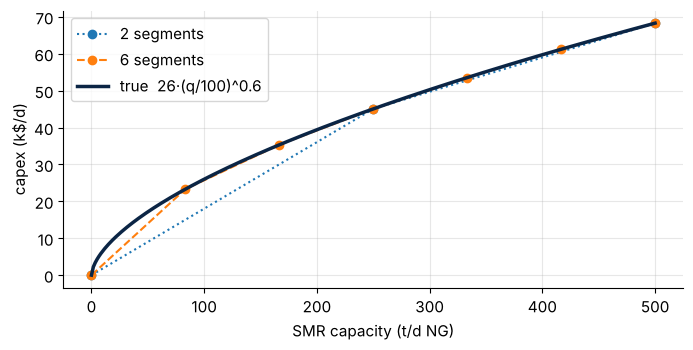

In [ ]:
print(" segments | objective | capex (PWL) | capex (true f) | error")
for ns in [1, 2, 3, 4, 6, 10, 16]:
    m = pathway_model(tau=0.1, nseg=ns); solve(m)
    pwl  = sum(pyo.value(m.capex[j]) for j in m.J)
    true = sum(float(capex(j, pyo.value(m.q[j]))) for j in m.J if pyo.value(m.y[j]) > 0.5)
    print(f"   {ns:4d}   |  {pyo.value(m.cost):7.2f}  |   {pwl:7.2f}   |    {true:7.2f}     | {(pwl - true) / true:6.1%}")

q = np.linspace(0, QU, 300)
for ns, ls in [(2, ":"), (6, "--")]:
    Bk = np.linspace(0, QU, ns + 1); plt.plot(Bk, capex("SMR", Bk), ls, marker="o", label=f"{ns} segments")
plt.plot(q, capex("SMR", q), color=NAVY, lw=2.5, label="true  26·(q/100)^0.6")
plt.xlabel("SMR capacity (t/d NG)"); plt.ylabel("capex (k$/d)"); plt.legend(); plt.show()

> ⚠️ Chords of a **concave** function lie **below** it, so a coarse piecewise-linear model *underestimates* capital cost and can favor too many small plants. Always check the true cost of the chosen design, and refine the breakpoints near the solution.

**Built-in alternative:** Pyomo's `Piecewise` component builds such formulations for you. HiGHS does not support SOS2 constraints, so use a binary-based representation such as `pw_repn="INC"`:

In [ ]:
pw = pyo.ConcreteModel(); pw.q = pyo.Var(bounds=(0, QU)); pw.c = pyo.Var()
pw.f = pyo.Piecewise(pw.c, pw.q, pw_pts=list(np.linspace(0, QU, 7)), f_rule=lambda m, x: float(capex("SMR", x)),
                     pw_constr_type="EQ", pw_repn="INC")
pw.need = pyo.Constraint(expr=pw.q >= 132); pw.obj = pyo.Objective(expr=pw.c)
solve(pw); print(f"Pyomo Piecewise: capex(132) ≈ {pyo.value(pw.c):.2f}   (true {float(capex('SMR', 132)):.2f})")

Pyomo Piecewise: capex(132) ≈ 30.33   (true 30.71)


###  Your turn 5 — more biomass

The regional biomass supply is expanded to **600 t/d**. Re-run the carbon-price sweep. At what carbon price does natural gas disappear completely, and why does the switch now happen *earlier*?

In [ ]:
#  Your turn: write your code here, then compare with the solution below

<details><summary><b> Show solution</b></summary>

```python
AVAIL["BM"] = 600
taus = np.arange(0, 0.41, 0.01); m = pathway_model(); ng = []
for tau in taus:
    m.tau = tau; solve(m); ng.append(pyo.value(m.pur["NG"]))
print("NG disappears at ≈", 1000 * taus[np.argmax(np.array(ng) < 1e-6)], "$/t")
AVAIL["BM"] = 300                                   # restore the base case
```
With 600 t/d of biomass a **single** large gasifier can supply all of the syngas, so no small, expensive NG plant is needed. Economies of scale now *favor* the switch: natural gas disappears completely at ≈ **100 USD/t**, whereas in the base case even the partial switch needed ≈ 140 USD/t and a small NG unit always remained.

</details>

---
## Part 6 · Logic propositions → CNF → inequalities, automatically (lecture slide 10)

`sympy` converts any Boolean expression to CNF. Each clause $\bigvee_{i \in P} Y_i \vee \bigvee_{j \in N} \neg Y_j$ becomes
$$\sum_{i\in P} y_i + \sum_{j \in N} (1 - y_j) \ge 1 \quad\Longleftrightarrow\quad \sum_{i\in P} y_i - \sum_{j\in N} y_j \ge 1 - \lvert N\rvert$$

In [ ]:
from sympy import symbols, Not, And, Or, Implies, Equivalent
from sympy.logic.boolalg import to_cnf

def logic_to_inequalities(expr):
    """Return a list of (coeffs, rhs) meaning  sum_i coeffs[i]·y_i >= rhs, one per CNF clause."""
    cnf = to_cnf(expr, simplify=True)
    clauses = cnf.args if isinstance(cnf, And) else (cnf,)
    out = []
    for cl in clauses:
        lits = cl.args if isinstance(cl, Or) else (cl,)
        coeffs, neg = {}, 0
        for L in lits:
            if isinstance(L, Not): coeffs[str(L.args[0])] = -1; neg += 1
            else:                  coeffs[str(L)] = +1
        out.append((coeffs, 1 - neg))
    return cnf, out

def pretty(ineqs):
    return "\n".join("   " + " ".join(f"{'+' if c > 0 else '−'} y_{v}" for v, c in sorted(co.items())).lstrip("+ ") + f"  ≥  {r}" for co, r in ineqs)

def verify(expr, ineqs):
    """Truth-table check: the inequalities must accept exactly the assignments that satisfy the logic."""
    vs = sorted(expr.free_symbols, key=str)
    for vals in itertools.product([0, 1], repeat=len(vs)):
        a = dict(zip(vs, vals)); y = {str(k): v for k, v in a.items()}
        logic = bool(expr.subs({k: bool(v) for k, v in a.items()}))
        milp_ok = all(sum(c * y[v] for v, c in co.items()) >= r for co, r in ineqs)
        if logic != milp_ok: return False
    return True

A_, M_, C_, F_, D_, K_ = symbols("A M C F D K")     # absorber, membrane, cryogenic, flash, distillation, compressor
for text, e in [("(A ∨ M) ⇒ ¬C        ", Implies(Or(A_, M_), Not(C_))),
                ("F ⇒ (D ∨ A)          ", Implies(F_, Or(D_, A_))),
                ("M ⇒ (¬A ∧ K)         ", Implies(M_, And(Not(A_), K_)))]:
    cnf, ineqs = logic_to_inequalities(e)
    print(f"{text} CNF: {cnf}\n{pretty(ineqs)}\n   truth-table check: {'✔' if verify(e, ineqs) else '✘'}\n")

(A ∨ M) ⇒ ¬C         CNF: (~A | ~C) & (~C | ~M)
   − y_A − y_C  ≥  -1
   − y_C − y_M  ≥  -1
   truth-table check: ✔

F ⇒ (D ∨ A)           CNF: A | D | ~F
   y_A + y_D − y_F  ≥  0
   truth-table check: ✔

M ⇒ (¬A ∧ K)          CNF: (K | ~M) & (~A | ~M)
   y_K − y_M  ≥  0
   − y_A − y_M  ≥  -1
   truth-table check: ✔



### 6.2 The slide-132 exercise: synthesis logic

1. If $x$ is true **and** $y$ is true, then $z$ is true.
2. If $x$ is true **or** $y$ is false, then $w$ is false.
3. If **both** $z$ and $w$ are false, then $x$ and/or $y$ should be true.

In [ ]:
X, Y, Zs, W = symbols("x y z w")
rules = [Implies(And(X, Y), Zs), Implies(Or(X, Not(Y)), Not(W)), Implies(And(Not(Zs), Not(W)), Or(X, Y))]
all_ineqs = []
for k, e in enumerate(rules, 1):
    cnf, ineqs = logic_to_inequalities(e); all_ineqs += ineqs
    print(f"Rule {k}: {e}\n  CNF: {cnf}\n{pretty(ineqs)}\n")

# Enumerate ALL feasible 0-1 configurations with Pyomo + integer cuts and compare with the truth table
m = pyo.ConcreteModel(); m.V = pyo.Set(initialize=["x", "y", "z", "w"]); m.y = pyo.Var(m.V, domain=pyo.Binary)
m.logic = pyo.ConstraintList()
for co, r in all_ineqs: m.logic.add(sum(c * m.y[v] for v, c in co.items()) >= r)
m.obj = pyo.Objective(expr=0); m.cuts = pyo.ConstraintList(); found = []
while solve(m) == "optimal":
    sol = {v: int(round(pyo.value(m.y[v]))) for v in m.V}; found.append(sol)
    m.cuts.add(sum(m.y[v] for v in m.V if sol[v]) - sum(m.y[v] for v in m.V if not sol[v]) <= sum(sol.values()) - 1)
truth = [a for a in itertools.product([0, 1], repeat=4) if bool(And(*rules).subs(dict(zip([X, Y, Zs, W], map(bool, a)))))]
print(f"MILP enumeration found {len(found)} feasible configurations; the truth table has {len(truth)} ✔")

Rule 1: Implies(x & y, z)
  CNF: z | ~x | ~y
   − y_x − y_y + y_z  ≥  -1

Rule 2: Implies(x | ~y, ~w)
  CNF: (y | ~w) & (~w | ~x)
   − y_w + y_y  ≥  0
   − y_w − y_x  ≥  -1

Rule 3: Implies(~w & ~z, x | y)
  CNF: w | x | y | z
   y_w + y_x + y_y + y_z  ≥  1



MILP enumeration found 8 feasible configurations; the truth table has 8 ✔


###  Your turn 6 — reactor logic

Translate "If the reactor R is built, then **exactly one** of the flash F or the column D must follow it" into inequalities, and verify them by truth table.

In [ ]:
#  Your turn: write your code here, then compare with the solution below

<details><summary><b> Show solution</b></summary>

```python
R, F2, D2 = symbols("R F2 D2")
e = Implies(R, And(Or(F2, D2), Not(And(F2, D2))))          # R ⇒ (F xor D)
cnf, ineqs = logic_to_inequalities(e); print(cnf); print(pretty(ineqs)); print(verify(e, ineqs))
```
Result: $y_{F} + y_{D} \ge y_R$ and $y_F + y_D \le 2 - y_R$. Together: when $y_R = 1$, $y_F + y_D = 1$; when $y_R = 0$, anything goes.

</details>

---
## Part 7 · Unit commitment of an industrial utility system (lecture slide 14)

A site in Riyadh runs a 24-h power balance: a base-load **CCGT** (already on at midnight), a mid-merit **GT-2**, a fast **OCGT** peaker, and **150 MW of solar PV**.

| Unit | $G^{\min}$ (MW) | $G^{\max}$ (MW) | fuel (USD/MWh) | no-load (USD/h) | start-up (USD) |
|---|---|---|---|---|---|
| CCGT | 120 | 300 | 30 | 600 | 6000 |
| GT-2 | 50 | 150 | 45 | 300 | 1500 |
| OCGT | 20 | 100 | 70 | 100 | 300 |

In [ ]:
H = np.arange(24)
DEM = 255 + 175 * np.exp(-((H - 16) / 4.5) ** 2) + 45 * np.exp(-((H - 21) / 2.0) ** 2) + 10 * np.cos(2 * np.pi * H / 24)
PV  = 150 * np.clip(np.sin(np.pi * (H - 6) / 12), 0, None)
UNITS = {"CCGT": dict(gmin=120, gmax=300, fuel=30, nl=600, su=6000, u0=1),
         "GT-2": dict(gmin=50,  gmax=150, fuel=45, nl=300, su=1500, u0=0),
         "OCGT": dict(gmin=20,  gmax=100, fuel=70, nl=100, su=300,  u0=0)}

def uc_model(min_up=None):
    m = pyo.ConcreteModel(); m.I = pyo.Set(initialize=list(UNITS)); m.T = pyo.Set(initialize=list(H))
    m.g = pyo.Var(m.I, m.T, domain=pyo.NonNegativeReals)        # MW
    m.u = pyo.Var(m.I, m.T, domain=pyo.Binary)                  # on/off
    m.s = pyo.Var(m.I, m.T, domain=pyo.Binary)                  # start-up
    m.pv = pyo.Var(m.T, bounds=lambda m, t: (0, PV[t]))         # solar used (curtailment allowed)
    m.cost = pyo.Objective(expr=sum(UNITS[i]["fuel"] * m.g[i, t] + UNITS[i]["nl"] * m.u[i, t] + UNITS[i]["su"] * m.s[i, t]
                                    for i in m.I for t in m.T))
    m.demand  = pyo.Constraint(m.T, rule=lambda m, t: sum(m.g[i, t] for i in m.I) + m.pv[t] == DEM[t])
    m.gmin    = pyo.Constraint(m.I, m.T, rule=lambda m, i, t: m.g[i, t] >= UNITS[i]["gmin"] * m.u[i, t])
    m.gmax    = pyo.Constraint(m.I, m.T, rule=lambda m, i, t: m.g[i, t] <= UNITS[i]["gmax"] * m.u[i, t])
    m.startup = pyo.Constraint(m.I, m.T, rule=lambda m, i, t:
                               m.s[i, t] >= m.u[i, t] - (m.u[i, t - 1] if t > 0 else UNITS[i]["u0"]))
    m.reserve = pyo.Constraint(m.T, rule=lambda m, t: sum(UNITS[i]["gmax"] * m.u[i, t] for i in m.I) >= 1.10 * DEM[t])
    if min_up:                                                  # dict {unit: hours}
        m.minup = pyo.ConstraintList()
        for i, L in min_up.items():
            for t in H:
                win = [tt for tt in H if t <= tt < t + L]
                m.minup.add(sum(m.u[i, tt] for tt in win) >= len(win) * m.s[i, t])
    return m

m = uc_model(); print("status:", solve(m), f"| total cost = {pyo.value(m.cost):,.0f} $/day")
for i in m.I:
    print(f"  {i:5s}: on {sum(pyo.value(m.u[i, t]) for t in m.T):4.0f} h, {sum(pyo.value(m.s[i, t]) for t in m.T):.0f} start(s), "
          f"{sum(pyo.value(m.g[i, t]) for t in m.T):6.0f} MWh")

status: optimal | total cost = 230,831 $/day
  CCGT : on   24 h, 0 start(s),   5745 MWh
  GT-2 : on   10 h, 1 start(s),    633 MWh
  OCGT : on    7 h, 2 start(s),    140 MWh


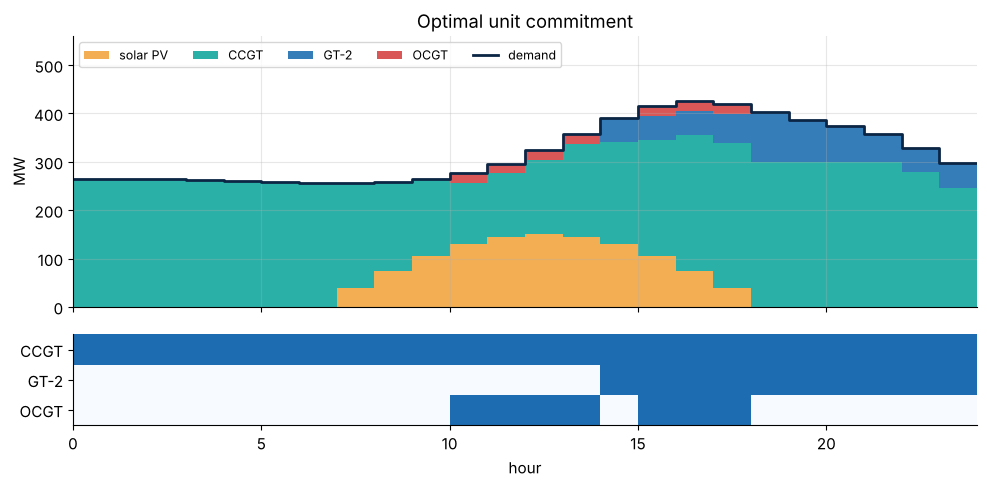

In [ ]:
def plot_uc(m, title):
    g = np.array([[pyo.value(m.g[i, t]) for t in H] for i in UNITS]); u = np.array([[pyo.value(m.u[i, t]) for t in H] for i in UNITS])
    pvu = np.array([pyo.value(m.pv[t]) for t in H]); cols = [TEAL, BLUE, RED]
    fig, ax = plt.subplots(2, 1, figsize=(10, 5), gridspec_kw=dict(height_ratios=[3, 1]), sharex=True)
    ax[0].stackplot(np.r_[H, 24], *[np.r_[s, s[-1]] for s in [pvu, *g]], step="post", colors=[GOLD] + cols,
                    labels=["solar PV"] + list(UNITS), alpha=0.9)
    ax[0].step(np.r_[H, 24], np.r_[DEM, DEM[-1]], where="post", color=NAVY, lw=2, label="demand")
    ax[0].set(ylabel="MW", title=title); ax[0].legend(ncol=5, fontsize=9, loc="upper left"); ax[0].set_ylim(0, 560)
    ax[1].imshow(u, aspect="auto", cmap="Blues", vmin=0, vmax=1.3, extent=[0, 24, 2.5, -0.5])
    ax[1].set_yticks(range(3)); ax[1].set_yticklabels(list(UNITS)); ax[1].set_xlabel("hour"); ax[1].grid(False)
    for (k, t), v in np.ndenumerate(u):
        if 0.01 < v < 0.99: ax[1].text(t + 0.5, k, f"{v:.2f}", ha="center", va="center", fontsize=7)
    plt.tight_layout(); plt.show()

plot_uc(m, "Optimal unit commitment")

### 7.2 What are the binaries worth?

optimal commitment (MILP)    :    230,831 $/day
all units always on          :    263,662 $/day  (+32,831 $/day = 14.2%)
LP relaxation (lower bound)  :    224,056 $/day  (gap 2.9%)


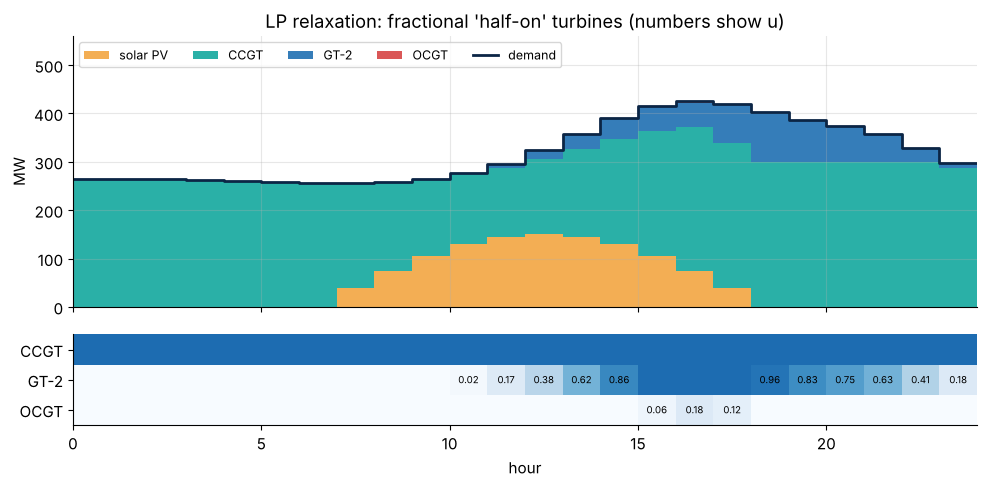

In [ ]:
m_on = uc_model()                                   # (a) "keep everything running": all u fixed to 1
for i in m_on.I:
    for t in m_on.T: m_on.u[i, t].fix(1)
solve(m_on)
m_lp = pyo.TransformationFactory("core.relax_integer_vars").create_using(uc_model()); solve(m_lp)   # (b) LP relaxation
z_opt = pyo.value(m.cost)
print(f"optimal commitment (MILP)    : {z_opt:10,.0f} $/day")
print(f"all units always on          : {pyo.value(m_on.cost):10,.0f} $/day  (+{pyo.value(m_on.cost) - z_opt:,.0f} $/day = {pyo.value(m_on.cost) / z_opt - 1:.1%})")
print(f"LP relaxation (lower bound)  : {pyo.value(m_lp.cost):10,.0f} $/day  (gap {1 - pyo.value(m_lp.cost) / z_opt:.1%})")
plot_uc(m_lp, "LP relaxation: fractional 'half-on' turbines (numbers show u)")

###  Your turn 7 — minimum up-time

Gas turbines must not cycle too often. Require that GT-2 and the OCGT stay on for **at least 4 h** after each start:
$$\sum_{\tau = t}^{t+L-1} u_{i\tau} \ge L\, s_{it}$$
(`uc_model` already supports this through `min_up`.) How much does the restriction cost, and how does the OCGT schedule change?

In [ ]:
#  Your turn: write your code here, then compare with the solution below

<details><summary><b> Show solution</b></summary>

```python
m4 = uc_model(min_up={"GT-2": 4, "OCGT": 4}); solve(m4)
print(f"{pyo.value(m4.cost):,.0f} $/day  (+{pyo.value(m4.cost) - z_opt:,.0f})")
plot_uc(m4, "With 4-h minimum up-time")
```
The OCGT can no longer drop out for a single hour, so it runs **one continuous 8-h block** instead of two separate starts, for only +600 USD/day. This is typical: operational rules cost little money but add many constraints.

</details>

---
## Part 8 · Build your own branch & bound (lecture slides 21 – 24)

We now implement the algorithm from the lecture **from scratch**, with LP relaxations solved by `scipy.optimize.linprog`. It handles general integers (branch $x_j \le \lfloor f\rfloor$ / $x_j \ge \lceil f \rceil$) and three node-selection rules, and it logs every node so we can draw the tree.

In [ ]:
def branch_and_bound(c, A, b, lb, ub, rule="depth", int_obj=False, tol=1e-6, max_nodes=50_000, pick=None):
    """LP-based B&B for  max c·x  s.t.  A x <= b,  lb <= x <= ub,  x integer.
    rule: 'depth' (LIFO), 'best' (best bound first), 'breadth' (FIFO).
    int_obj: objective is integer at integer points → fathom when floor(z_LP) <= incumbent.
    pick: optional function (frac, x) → index j of the branching variable (default: most fractional)."""
    c = np.asarray(c, float)
    LIST = [dict(id=1, parent=None, depth=0, lb=np.asarray(lb, float), ub=np.asarray(ub, float), bound=np.inf, label="root")]
    log, hist, next_id, x_best, z_best = [], [], 2, None, -np.inf
    while LIST and len(log) < max_nodes:
        if   rule == "best":  k = max(range(len(LIST)), key=lambda i: (LIST[i]["bound"], LIST[i]["depth"]))
        elif rule == "depth": k = len(LIST) - 1
        else:                 k = 0
        nd = LIST.pop(k)
        res = linprog(-c, A_ub=A, b_ub=b, bounds=list(zip(nd["lb"], nd["ub"])), method="highs")
        if res.status != 0:                                                     # ① infeasible
            nd.update(status="infeasible", z=None, x=None)
        else:
            nd["x"], nd["z"] = res.x, -res.fun
            bound = np.floor(nd["z"] + tol) if int_obj else nd["z"]
            frac = np.abs(res.x - np.round(res.x))
            if bound <= z_best + tol:                                           # ② fathom by bound
                nd["status"] = "bound"
            elif frac.max() <= tol:                                             # ③ integer → incumbent
                nd["status"] = "integer"; x_best, z_best = np.round(res.x), nd["z"]
            else:                                                               # branch (default: most fractional x_j)
                j = int(np.argmax(frac)) if pick is None else pick(frac, res.x)
                v = res.x[j]; nd["status"] = "branched"; nd["children"] = []
                for side in ("down", "up"):                                     # LIFO explores 'up' first
                    kid = dict(id=next_id, parent=nd["id"], depth=nd["depth"] + 1, lb=nd["lb"].copy(), ub=nd["ub"].copy(), bound=bound)
                    if side == "down": kid["ub"][j] = np.floor(v); kid["label"] = f"x{j+1}≤{np.floor(v):.0f}"
                    else:              kid["lb"][j] = np.ceil(v);  kid["label"] = f"x{j+1}≥{np.ceil(v):.0f}"
                    LIST.append(kid); nd["children"].append(next_id); next_id += 1
        log.append(nd)
        hist.append((len(log), z_best, max([z_best] + [n["bound"] for n in LIST])))
    return x_best, z_best, log, hist

c, A, b = [16, 22, 12, 8, 11, 19], [[5, 7, 4, 3, 4, 6]], [14]
x, z, log, hist = branch_and_bound(c, A, b, np.zeros(6), np.ones(6), rule="depth", int_obj=True)
print(f"z* = {z:.0f}, x* = {x.astype(int)}, LPs solved = {len(log)}\n")
print("  #  node  branch   depth   LP z     status       incumbent")
inc = -np.inf
for k, nd in enumerate(log, 1):
    if nd["status"] == "integer": inc = max(inc, nd["z"])
    zt = "  —   " if nd["z"] is None else f"{nd['z']:6.2f}"
    print(f" {k:2d}  {nd['id']:4d}  {nd['label']:7s}  {nd['depth']:4d}   {zt}   {nd['status']:11s}  {inc if np.isfinite(inc) else '—'}")

z* = 43, x* = [1 0 0 1 0 1], LPs solved = 31

  #  node  branch   depth   LP z     status       incumbent
  1     1  root        0    44.43   branched     —
  2     3  x2≥1        1    44.33   branched     —
  3     5  x6≥1        2    44.20   branched     —
  4     7  x1≥1        3     —      infeasible   —
  5     6  x1≤0        3    44.00   branched     —
  6     9  x3≥1        4     —      infeasible   —
  7     8  x3≤0        4    43.75   branched     —
  8    11  x5≥1        5     —      infeasible   —
  9    10  x5≤0        5    43.67   branched     —
 10    13  x4≥1        6     —      infeasible   —
 11    12  x4≤0        6    41.00   integer      41.0
 12     4  x6≤0        2    44.00   branched     41.0
 13    15  x3≥1        3    43.60   branched     41.0
 14    17  x1≥1        4     —      infeasible   41.0
 15    16  x1≤0        4    42.25   branched     41.0
 16    19  x5≥1        5     —      infeasible   41.0
 17    18  x5≤0        5    42.00   integer      42.0
 18   

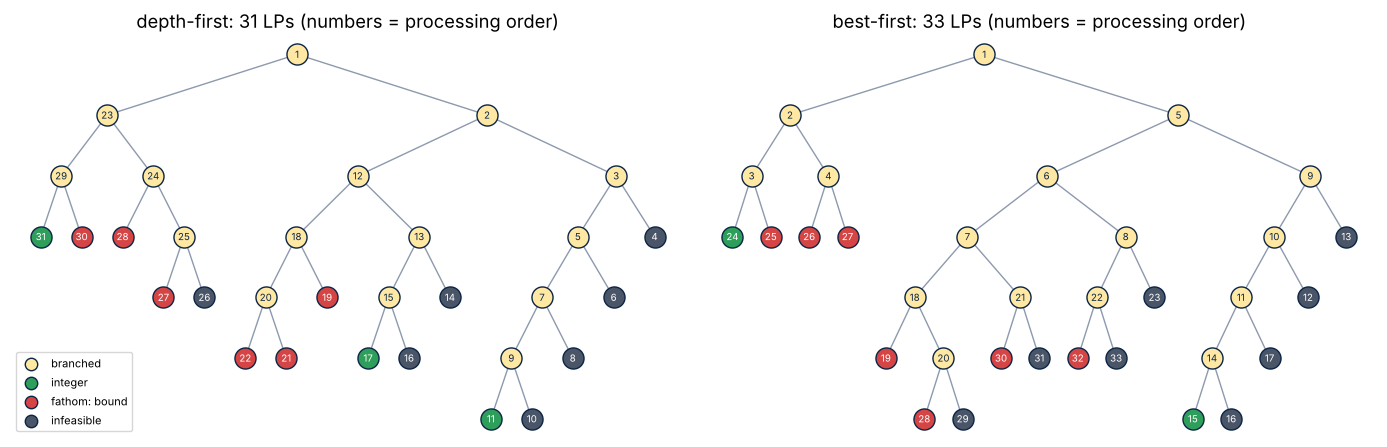

In [ ]:
def draw_tree(log, ax, title):
    byid = {nd["id"]: nd for nd in log}; pos, leaf = {}, [0]
    def place(i):
        kids = [k for k in byid[i].get("children", []) if k in byid]
        if kids:
            for k_ in kids: place(k_)
            pos[i] = (np.mean([pos[k_][0] for k_ in kids]), -byid[i]["depth"])
        else:
            pos[i] = (leaf[0], -byid[i]["depth"]); leaf[0] += 1
    place(1)
    col = {"branched": "#FFE8A3", "integer": GREEN, "bound": RED, "infeasible": "#4A5568"}
    for nd in log:
        for k_ in nd.get("children", []):
            if k_ in pos: ax.plot(*zip(pos[nd["id"]], pos[k_]), color=GRAY, lw=1, zorder=1)
    for k, nd in enumerate(log, 1):
        ax.scatter(*pos[nd["id"]], s=230, color=col[nd["status"]], edgecolor=NAVY, zorder=3)
        ax.text(*pos[nd["id"]], str(k), ha="center", va="center", fontsize=7, zorder=4,
                color="white" if nd["status"] != "branched" else NAVY)
    for s_, lab in [("branched", "branched"), ("integer", "integer"), ("bound", "fathom: bound"), ("infeasible", "infeasible")]:
        ax.scatter([], [], s=80, color=col[s_], edgecolor=NAVY, label=lab)
    ax.set_title(title); ax.axis("off")

fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, rule in zip(axs, ["depth", "best"]):
    _, _, lg, _ = branch_and_bound(c, A, b, np.zeros(6), np.ones(6), rule=rule, int_obj=True)
    draw_tree(lg, ax, f"{rule}-first: {len(lg)} LPs (numbers = processing order)")
axs[0].legend(loc="lower left", fontsize=8); plt.tight_layout(); plt.show()

### 8.2 General integers: the 2-D example from the lecture

Depth-first search with bound rounding reproduces the 5 LPs of the lecture animation.

In [ ]:
x, z, lg, _ = branch_and_bound([4, -1], [[7, -2], [0, 1], [2, -2]], [14, 3, 3], [0, 0], [10, 10], rule="depth", int_obj=True)
print(f"x* = {x}, z* = {z:.0f}, LPs = {len(lg)}")
for k, nd in enumerate(lg, 1):
    print(f"  {k}. {nd['label']:6s} → " + ("infeasible" if nd["x"] is None else f"x = {np.round(nd['x'], 3)}, z = {nd['z']:.3f}") + f"  [{nd['status']}]")

x* = [2. 1.], z* = 7, LPs = 5
  1. root   → x = [2.857 3.   ], z = 8.429  [branched]
  2. x1≥3   → infeasible  [infeasible]
  3. x1≤2   → x = [2.  0.5], z = 7.500  [branched]
  4. x2≥1   → x = [2. 1.], z = 7.000  [integer]
  5. x2≤0   → x = [1.5 0. ], z = 6.000  [bound]


### 8.3 Experiment: which node-selection rule is best?

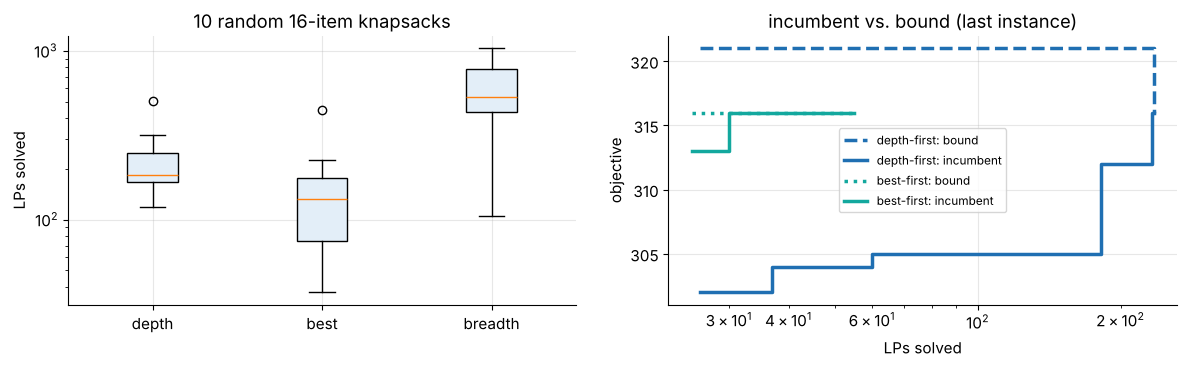

{'depth': 184, 'best': 132, 'breadth': 532} ← median LPs


In [ ]:
rng = np.random.default_rng(7); stats = {r_: [] for r_ in ["depth", "best", "breadth"]}
for trial in range(10):
    n = 16; w = rng.integers(10, 60, n).astype(float); p = w + rng.integers(-5, 15, n); cap = 0.45 * w.sum()
    for rule in stats:
        _, z_, lg, _ = branch_and_bound(p, [w], [cap], np.zeros(n), np.ones(n), rule=rule, int_obj=True)
        stats[rule].append(len(lg))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].boxplot(list(stats.values()), patch_artist=True, boxprops=dict(facecolor="#E3EEF8"))
ax[0].set_xticks([1, 2, 3], list(stats.keys())); ax[0].set(ylabel="LPs solved", title="10 random 16-item knapsacks"); ax[0].set_yscale("log")
for rule, col, ls in [("depth", BLUE, "--"), ("best", TEAL, ":")]:
    _, _, _, h = branch_and_bound(p, [w], [cap], np.zeros(n), np.ones(n), rule=rule, int_obj=True)
    h = np.array([r_ for r_ in h if np.isfinite(r_[1])])
    ax[1].step(h[:, 0], h[:, 2], color=col, lw=2.5, ls=ls, where="post", label=f"{rule}-first: bound")
    ax[1].step(h[:, 0], h[:, 1], color=col, lw=2.5, where="post", label=f"{rule}-first: incumbent")
ax[1].set(xlabel="LPs solved", ylabel="objective", title="incumbent vs. bound (last instance)", xscale="log"); ax[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()
print({r_: int(np.median(v)) for r_, v in stats.items()}, "← median LPs")

###  Your turn 8 — branching-variable selection

Our code branches on the **most fractional** variable. `branch_and_bound` accepts a `pick=` argument: a function `pick(frac, x)` that returns the index of the variable to branch on.

1. Write two rules: **first** fractional variable (smallest index), and **most valuable** fractional variable (largest $c_j$, the lecture's rule of thumb *"branch on important variables"*).
2. Compare them with the default on 10 random **3-resource** knapsacks ($n = 15$, best-first search). Count the LPs.

 Why 3 resources? With a **single** knapsack constraint every LP vertex has **at most one** fractional variable (the "critical item"), so all rules would pick the same $j$.

In [ ]:
#  Your turn: write your code here, then compare with the solution below

<details><summary><b> Show solution</b></summary>

```python
first   = lambda frac, x: int(np.flatnonzero(frac > 1e-6)[0])                 # smallest index
biggest = lambda frac, x: int(np.argmax(np.where(frac > 1e-6, P_, -np.inf)))  # largest c_j

rng = np.random.default_rng(11)
lps = {"most fractional": [], "first fractional": [], "largest c_j": []}
for trial in range(10):
    W   = rng.integers(10, 60, (3, 15)).astype(float)                         # 3 resources, 15 items
    P_  = W.mean(0) + rng.integers(-5, 15, 15); cap = 0.45 * W.sum(1)
    for name, pk in zip(lps, [None, first, biggest]):
        log = branch_and_bound(P_, W, cap, np.zeros(15), np.ones(15), rule="best", pick=pk)[2]
        lps[name].append(len(log))
print({k: sum(v) for k, v in lps.items()})        # total LPs: ≈ 3774 / 4836 / 3762
```
**First fractional** needs about **28 % more** LPs than **most fractional**, while **largest $c_j$** is as good as most fractional (and wins on 5 of the 10 instances). The variable you branch on decides how fast the bounds move. Real solvers estimate that directly with *pseudocost* or *strong branching*.

</details>

---
## Part 9 · Cutting planes (lecture slides 25 – 27)

### 9.1 Gomory fractional cuts from the simplex tableau
For $\max c^\top x$, $Ax \le b$, $x \ge 0$ integer, with integer data: add slacks $s = b - Ax$, read the optimal tableau row of a fractional basic variable, round down every coefficient, and substitute $s$ back to get the cut in $x$-space.

In [ ]:
def gomory_cutting_planes(c, A, b, max_cuts=10, verbose=True):
    A, b, c = np.array(A, float), np.array(b, float), np.array(c, float); n = len(c); cuts = []
    for it in range(max_cuts + 1):
        m_ = len(b); r = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None)] * n, method="highs")
        x = r.x; X = np.r_[x, b - A @ x]; Af = np.hstack([A, np.eye(m_)])
        if verbose: print(f"LP {it}: x = {np.round(x, 4)},  z = {-r.fun:.4f}")
        if np.all(np.abs(x - np.round(x)) < 1e-7): return x, -r.fun, cuts
        basis = [j for j in np.argsort(-X) if X[j] > 1e-9][:m_]                     # basic variables …
        for j in range(n + m_):                                                    # … completed to a full-rank basis
            if len(basis) == m_: break
            if j not in basis and np.linalg.matrix_rank(Af[:, basis + [j]]) == len(basis) + 1: basis.append(j)
        basis = sorted(basis); Binv = np.linalg.inv(Af[:, basis]); Tab = Binv @ Af; rhs = Binv @ b
        frac = rhs - np.floor(rhs + 1e-9)
        cand = [k for k in range(m_) if basis[k] < n and 1e-6 < frac[k] < 1 - 1e-6]
        k = max(cand, key=lambda k: (round(min(frac[k], 1 - frac[k]), 6), basis[k]))  # most fractional row
        coef = np.floor(Tab[k] + 1e-9); coef[basis] = 0; coef[basis[k]] = 1; g0 = np.floor(rhs[k] + 1e-9)
        a_x, r_x = coef[:n] - coef[n:] @ A, g0 - coef[n:] @ b                        # substitute s = b − A x
        name = lambda j: f"x{j+1}" if j < n else f"s{j-n+1}"
        if verbose:
            print("   row :", f"{name(basis[k])} + " + " + ".join(f"({Tab[k, j]:.3g}){name(j)}" for j in range(n + m_) if j not in basis and abs(Tab[k, j]) > 1e-9), f"= {rhs[k]:.4g}")
            print("   cut :", " + ".join(f"({a:g})x{j+1}" for j, a in enumerate(a_x)), f"<= {r_x:g}")
        cuts.append((a_x, r_x)); A = np.vstack([A, a_x]); b = np.r_[b, r_x]
    return x, -r.fun, cuts

print("Example 1 (lecture GIF):  max −x1 + 2x2,  x1 + x2 ≤ 4,  −4x1 + 6x2 ≤ 9")
x, z, cuts1 = gomory_cutting_planes([-1, 2], [[1, 1], [-4, 6]], [4, 9])
print("\nExample 2 (B&B example): max 4x1 − x2,  7x1 − 2x2 ≤ 14,  x2 ≤ 3,  2x1 − 2x2 ≤ 3")
x, z, cuts2 = gomory_cutting_planes([4, -1], [[7, -2], [0, 1], [2, -2]], [14, 3, 3])

Example 1 (lecture GIF):  max −x1 + 2x2,  x1 + x2 ≤ 4,  −4x1 + 6x2 ≤ 9
LP 0: x = [1.5 2.5],  z = 3.5000
   row : x2 + (0.4)s1 + (0.1)s2 = 2.5
   cut : (0)x1 + (1)x2 <= 2
LP 1: x = [0.75 2.  ],  z = 3.2500
   row : x1 + (-0.25)s2 + (1.5)s3 = 0.75
   cut : (-3)x1 + (5)x2 <= 7
LP 2: x = [1. 2.],  z = 3.0000

Example 2 (B&B example): max 4x1 − x2,  7x1 − 2x2 ≤ 14,  x2 ≤ 3,  2x1 − 2x2 ≤ 3
LP 0: x = [2.8571 3.    ],  z = 8.4286
   row : x1 + (0.143)s1 + (0.286)s2 = 2.857
   cut : (1)x1 + (0)x2 <= 2
LP 1: x = [2.  0.5],  z = 7.5000
   row : x2 + (-0.5)s3 + (1)s4 = 0.5
   cut : (1)x1 + (-1)x2 <= 1
LP 2: x = [2. 1.],  z = 7.0000


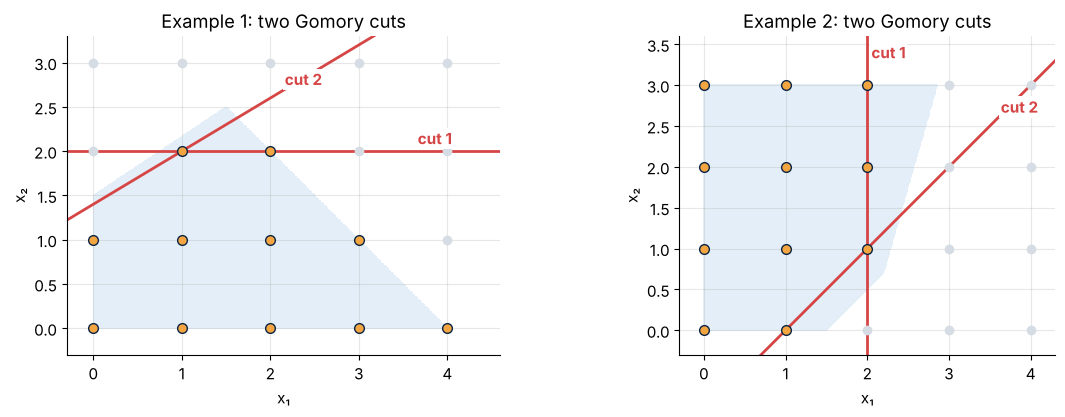

In [ ]:
def plot_cuts(A, b, cuts, xlim, ylim, title, ax):
    X1, X2 = np.meshgrid(np.linspace(*xlim, 500), np.linspace(*ylim, 500)); P = np.stack([X1, X2], -1)
    inside = np.all(P @ np.array(A, float).T <= np.array(b, float) + 1e-9, axis=-1) & (X1 >= 0) & (X2 >= 0)
    ax.contourf(X1, X2, inside, levels=[0.5, 1.5], colors=["#E3EEF8"])
    for k, (a, r_) in enumerate(cuts, 1):
        if abs(a[1]) > 1e-9:
            xs = np.linspace(*xlim, 200); ys = (r_ - a[0] * xs) / a[1]; ax.plot(xs, ys, color=RED, lw=2)
            vis = np.flatnonzero((ys > ylim[0]) & (ys < ylim[1] - 0.25)); px, py = xs[vis[int(0.8 * (len(vis) - 1))]], ys[vis[int(0.8 * (len(vis) - 1))]]
        else:
            ax.axvline(r_ / a[0], color=RED, lw=2); px, py = r_ / a[0], ylim[1] - 0.35
        ax.text(px + 0.05, py + 0.08, f"cut {k}", color=RED, fontweight="bold", bbox=dict(fc="white", ec="none", pad=1))
    for i in range(int(xlim[1]) + 1):
        for j in range(int(ylim[1]) + 1):
            ok = np.all(np.array(A, float) @ [i, j] <= np.array(b, float) + 1e-9)
            ax.plot(i, j, "o", color=GOLD if ok else "#D5DCE4", mec=NAVY if ok else "none", ms=7)
    ax.set(xlim=xlim, ylim=ylim, title=title, xlabel="x₁", ylabel="x₂"); ax.set_aspect("equal")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
plot_cuts([[1, 1], [-4, 6]], [4, 9], cuts1, (-0.3, 4.6), (-0.3, 3.3), "Example 1: two Gomory cuts", ax[0])
plot_cuts([[7, -2], [0, 1], [2, -2]], [14, 3, 3], cuts2, (-0.3, 4.3), (-0.3, 3.6), "Example 2: two Gomory cuts", ax[1])
plt.tight_layout(); plt.show()

### 9.2 Separating cover inequalities for a knapsack constraint

Given an LP point $x^*$, the **most violated cover** solves a tiny knapsack itself:
$$\min_u \sum_j (1 - x^*_j)\,u_j \quad\text{s.t.}\quad \sum_j a_j u_j \ge b + 1,\; u \in \{0,1\}^n.$$
If the optimum is $< 1$, the cover $C = \{j : u_j = 1\}$ gives a violated inequality $\sum_{j\in C} x_j \le \lvert C\rvert - 1$.

In [ ]:
c = np.array([16, 22, 12, 8, 11, 19.]); w = np.array([5, 7, 4, 3, 4, 6.]); cap = 14
def separate_cover(xs):
    r = milp(1 - xs, constraints=LinearConstraint(w[None], cap + 1, np.inf), integrality=np.ones(len(w)), bounds=Bounds(0, 1))
    return np.round(r.x), r.fun

A_cut, b_cut = [w], [cap]
for it in range(10):
    r = linprog(-c, A_ub=np.array(A_cut), b_ub=b_cut, bounds=[(0, 1)] * 6, method="highs"); xs = r.x
    u, val = separate_cover(xs)
    print(f"round {it}: LP bound = {-r.fun:7.3f}   x* = {xs.round(3)}")
    if val >= 1 - 1e-9: print("          no violated cover left"); break
    C = [int(j) + 1 for j in np.flatnonzero(u)]; print(f"          add cover cut  sum x_j (j in {C}) <= {len(C) - 1}   (violation {1 - val:.3f})")
    A_cut.append(u); b_cut.append(u.sum() - 1)

# Chvátal–Gomory rounding of the four 3-covers of {1,2,3,6}  →  x1 + x2 + x3 + x6 <= 2
cg = np.array([1, 1, 1, 0, 0, 1.]); r = linprog(-c, A_ub=np.vstack(A_cut + [cg]), b_ub=b_cut + [2], bounds=[(0, 1)] * 6, method="highs")
print(f"\n+ CG cut x1+x2+x3+x6 <= 2 → LP bound = {-r.fun:.3f}  ⇒  z* <= 43 (integer objective)")
for label, AA, bb in [("original", [w], [cap]), ("with cuts", A_cut + [cg], b_cut + [2])]:
    _, z_, lg, _ = branch_and_bound(c, np.array(AA), bb, np.zeros(6), np.ones(6), rule="depth", int_obj=True)
    print(f"own B&B on {label:9s} formulation: z* = {z_:.0f} after {len(lg)} LPs")

round 0: LP bound =  44.429   x* = [1.    0.429 0.    0.    0.    1.   ]
          add cover cut  sum x_j (j in [1, 2, 6]) <= 2   (violation 0.429)
round 1: LP bound =  44.000   x* = [0.   1.   0.25 0.   0.   1.  ]
          add cover cut  sum x_j (j in [2, 3, 6]) <= 2   (violation 0.250)
round 2: LP bound =  44.000   x* = [1.  1.  0.5 0.  0.  0. ]
          add cover cut  sum x_j (j in [1, 2, 3]) <= 2   (violation 0.500)
round 3: LP bound =  44.000   x* = [0.333 1.    0.333 0.    0.    0.667]
          no violated cover left

+ CG cut x1+x2+x3+x6 <= 2 → LP bound = 43.750  ⇒  z* <= 43 (integer objective)
own B&B on original  formulation: z* = 43 after 31 LPs
own B&B on with cuts formulation: z* = 43 after 11 LPs


###  Your turn 9 — find all minimal covers

List **all minimal covers** of $3x_1 + 4x_2 + 5x_3 + 6x_4 \le 10$. A cover is *minimal* if removing any item makes it fit. Write a short enumeration with `itertools.combinations`.

In [ ]:
#  Your turn: write your code here, then compare with the solution below

<details><summary><b> Show solution</b></summary>

```python
a, b = [3, 4, 5, 6], 10
covers = [set(C) for r in range(1, 5) for C in itertools.combinations(range(4), r) if sum(a[j] for j in C) > b]
minimal = [C for C in covers if all(sum(a[j] for j in C - {k}) <= b for k in C)]
print([{j + 1 for j in C} for C in minimal])      # → [{3, 4}, {1, 2, 3}, {1, 2, 4}]
```
Minimal covers: $\{3,4\}$, $\{1,2,3\}$, $\{1,2,4\}$ ⇒ $x_3 + x_4 \le 1$, $x_1 + x_2 + x_3 \le 2$, $x_1 + x_2 + x_4 \le 2$.

</details>

---
## Part 10 · Formulation strength (lecture slides 11 & 29)

### 10.1 Facility location: aggregated (weak) vs. disaggregated (strong) linking constraints
- **Weak:** $\sum_j x_{ij} \le n\,y_i$ (one constraint per site)
- **Strong:** $x_{ij} \le y_i \;\; \forall j$ ($n$ constraints per site)

In [ ]:
def facility_location(m=20, n=60, strong=True, seed=0):
    rng = np.random.default_rng(seed)
    Fc = rng.uniform(300, 600, m); P, Q = rng.uniform(0, 100, (m, 2)), rng.uniform(0, 100, (n, 2))
    cost = np.r_[Fc, 3 * np.linalg.norm(P[:, None] - Q[None], axis=2).ravel()]
    rows = n + (m * n if strong else m); A = lil_matrix((rows, m + m * n)); lo, hi = np.zeros(rows), np.zeros(rows)
    for j in range(n): A[j, m + np.arange(m) * n + j] = 1; lo[j] = hi[j] = 1
    r = n
    for i in range(m):
        if strong:
            for j in range(n): A[r, m + i * n + j] = 1; A[r, i] = -1; lo[r] = -np.inf; r += 1
        else:
            A[r, m + i * n: m + (i + 1) * n] = 1; A[r, i] = -n; lo[r] = -np.inf; r += 1
    cons = LinearConstraint(A.tocsr(), lo, hi)
    lp = milp(cost, constraints=cons, integrality=np.zeros(len(cost)), bounds=Bounds(0, 1))
    t0 = time.perf_counter()
    ip = milp(cost, constraints=cons, integrality=np.r_[np.ones(m), np.zeros(m * n)], bounds=Bounds(0, 1))
    return dict(rows=rows, gap=(ip.fun - lp.fun) / ip.fun, nodes=ip.mip_node_count, time=time.perf_counter() - t0, z=ip.fun)

print(" size     form    rows   LP gap   nodes   time (s)")
res10 = {}
for (mm, nn) in [(10, 30), (20, 60), (30, 90)]:
    for strong in [False, True]:
        d = facility_location(mm, nn, strong); res10[(mm, nn, strong)] = d
        print(f"{mm:3d}×{nn:<3d}  {'strong' if strong else 'weak  '}  {d['rows']:5d}   {max(d['gap'], 0):6.1%}  {d['nodes']:5d}   {d['time']:7.2f}")

 size     form    rows   LP gap   nodes   time (s)


 10×30   weak       40    31.7%     13      0.10
 10×30   strong    330     0.0%      1      0.01


 20×60   weak       80    51.3%     65      0.44
 20×60   strong   1260     0.0%      1      0.02


 30×90   weak      120    49.3%     39      0.75
 30×90   strong   2790     0.0%      1      0.04


>  The strong model has **many more rows**, yet its LP relaxation is already integral (0 % gap, 1 node). *A stronger relaxation beats a smaller model.*

### 10.2 The price of a lazy big-M (fixed-charge transportation)
$x_{ij} \le M_{ij}\, y_{ij}$ with the tight $M_{ij} = \min(s_i, d_j)$ vs. 10×, 100×, 1000× larger.

In [ ]:
def fixed_charge_transport(Mfac=1.0, m=8, n=12, seed=3):
    rng = np.random.default_rng(seed)
    s = rng.integers(20, 60, m).astype(float); d = rng.integers(10, 40, n).astype(float); d *= 0.9 * s.sum() / d.sum()
    cv, fx = rng.uniform(1, 5, (m, n)), rng.uniform(40, 120, (m, n)); N = 2 * m * n
    A = lil_matrix((m + n + m * n, N)); lo = np.zeros(m + n + m * n); hi = np.zeros(m + n + m * n); r = 0
    for i in range(m): A[r, i * n:(i + 1) * n] = 1; lo[r] = -np.inf; hi[r] = s[i]; r += 1        # supply
    for j in range(n): A[r, np.arange(m) * n + j] = 1; lo[r] = d[j]; hi[r] = np.inf; r += 1      # demand
    for i in range(m):
        for j in range(n):                                                                       # x_ij <= M y_ij
            A[r, i * n + j] = 1; A[r, m * n + i * n + j] = -Mfac * min(s[i], d[j]); lo[r] = -np.inf; r += 1
    cons, ub = LinearConstraint(A.tocsr(), lo, hi), np.r_[np.full(m * n, np.inf), np.ones(m * n)]
    c = np.r_[cv.ravel(), fx.ravel()]
    lp = milp(c, constraints=cons, integrality=np.zeros(N), bounds=Bounds(0, ub))
    t0 = time.perf_counter(); ip = milp(c, constraints=cons, integrality=np.r_[np.zeros(m * n), np.ones(m * n)], bounds=Bounds(0, ub))
    return lp.fun, ip.fun, ip.mip_node_count, time.perf_counter() - t0

print("  M factor   LP bound   MILP opt   LP gap   nodes   time (s)")
for Mf in [1, 10, 100, 1000]:
    lp_, ip_, nodes, t_ = fixed_charge_transport(Mf)
    print(f"  {Mf:6d}    {lp_:8.1f}   {ip_:8.1f}   {(ip_ - lp_) / ip_:6.1%}   {nodes:5d}   {t_:6.2f}")

  M factor   LP bound   MILP opt   LP gap   nodes   time (s)


       1      1404.5     1448.4     3.0%       1     0.16


      10       571.2     1448.4    60.6%      37     1.48


     100       478.2     1448.4    67.0%      37     1.55


    1000       468.7     1448.4    67.6%      37     1.39


>  Same optimum, but the loose big-M destroys the relaxation (gap 3 % → 68 %) and multiplies the search effort. HiGHS's presolve repairs part of the damage (the node counts for 10×–1000× are equal), but **do not rely on it**: always use the tightest bound the physics gives you.

<details><summary><b> Discussion: symmetry</b></summary>

Five **identical** parallel compressors $y_1, \dots, y_5$: the solutions "units 1 & 2 on" and "units 4 & 5 on" are different binary vectors with the same cost, so B&B may explore $\binom{5}{2} = 10$ equivalent subtrees. Adding $y_1 \ge y_2 \ge \dots \ge y_5$ keeps **one** representative per class, a cheap and powerful fix. Better still, use one integer variable $n = \sum_k y_k$.

</details>

---
## Part 11 · Production sequencing with changeovers (TSP + lazy cuts, lecture slide 13)

A multiproduct paint reactor makes 9 colors in a repeating cycle. Cleaning time depends on the **order**: dark → light needs a thorough wash, and Red ↔ Green carries an extra contamination penalty. **Which cycle minimizes total cleaning time?** This is an *asymmetric* traveling salesman problem.

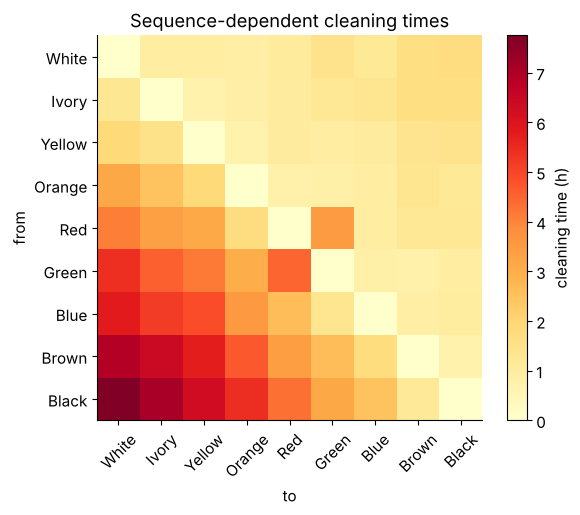

In [ ]:
PRODS = ["White", "Ivory", "Yellow", "Orange", "Red", "Green", "Blue", "Brown", "Black"]
dark = np.array([0, 0.5, 1, 2, 3, 4, 4.5, 5.5, 6]); nP = len(PRODS); rng = np.random.default_rng(7)
CLEAN = 0.5 + 1.0 * np.maximum(0, dark[:, None] - dark[None, :]) + 0.15 * np.abs(dark[:, None] - dark[None, :]) + rng.uniform(0, 0.4, (nP, nP))
CLEAN[4, 5] += 2.5; CLEAN[5, 4] += 2.5; np.fill_diagonal(CLEAN, 0)            # Red ↔ Green contamination
PROC = np.array([6, 4, 5, 5, 6, 4, 5, 3, 6.])                                   # processing time (h)

plt.figure(figsize=(6.5, 5)); plt.imshow(CLEAN, cmap="YlOrRd"); plt.colorbar(label="cleaning time (h)")
plt.xticks(range(nP), PRODS, rotation=45); plt.yticks(range(nP), PRODS); plt.xlabel("to"); plt.ylabel("from"); plt.grid(False)
plt.title("Sequence-dependent cleaning times"); plt.show()

In [ ]:
m = pyo.ConcreteModel(); m.N = pyo.RangeSet(0, nP - 1)
m.A = pyo.Set(initialize=[(i, j) for i in range(nP) for j in range(nP) if i != j])
m.x = pyo.Var(m.A, domain=pyo.Binary)                                           # 1 if j directly follows i
m.obj = pyo.Objective(expr=sum(CLEAN[i, j] * m.x[i, j] for (i, j) in m.A))
m.out = pyo.Constraint(m.N, rule=lambda m, i: sum(m.x[i, j] for j in m.N if j != i) == 1)
m.inn = pyo.Constraint(m.N, rule=lambda m, j: sum(m.x[i, j] for i in m.N if i != j) == 1)
m.sec = pyo.ConstraintList()                                                     # subtour cuts, added lazily

for it in range(1, 50):
    solve(m)
    G = nx.DiGraph([(i, j) for (i, j) in m.A if pyo.value(m.x[i, j]) > 0.5]); cycles = list(nx.simple_cycles(G))
    print(f"iteration {it}: cleaning = {pyo.value(m.obj):6.2f} h, subtours = {[[PRODS[k][:3] for k in cyc] for cyc in cycles]}")
    if len(cycles) == 1: break
    for S in cycles:
        m.sec.add(sum(m.x[i, j] for i in S for j in S if i != j) <= len(S) - 1)

order = [0]
while len(order) < nP: order.append(next(j for j in range(nP) if j != order[-1] and pyo.value(m.x[order[-1], j]) > 0.5))
intuitive = list(range(nP))                                                      # light → dark campaign
cyc_cost = lambda o: sum(CLEAN[o[k], o[(k + 1) % nP]] for k in range(nP))
print("\noptimal cycle :", " → ".join(PRODS[k] for k in order), f"→ ({cyc_cost(order):.2f} h cleaning)")
print("light → dark  :", " → ".join(PRODS[k] for k in intuitive), f"→ ({cyc_cost(intuitive):.2f} h cleaning)")

iteration 1: cleaning =   9.93 h, subtours = [['Bla', 'Bro'], ['Gre', 'Blu'], ['Ora', 'Red'], ['Whi', 'Ivo', 'Yel']]


iteration 2: cleaning =  11.93 h, subtours = [['Bla', 'Bro', 'Blu', 'Gre'], ['Yel', 'Ora', 'Red'], ['Whi', 'Ivo']]


iteration 3: cleaning =  13.16 h, subtours = [['Red', 'Blu', 'Gre', 'Bla', 'Bro'], ['Whi', 'Yel', 'Ora', 'Ivo']]


iteration 4: cleaning =  13.47 h, subtours = [['Whi', 'Yel', 'Ora', 'Gre', 'Blu', 'Bla', 'Bro', 'Red', 'Ivo']]

optimal cycle : White → Yellow → Orange → Green → Blue → Black → Brown → Red → Ivory → (13.47 h cleaning)
light → dark  : White → Ivory → Yellow → Orange → Red → Green → Blue → Brown → Black → (16.75 h cleaning)


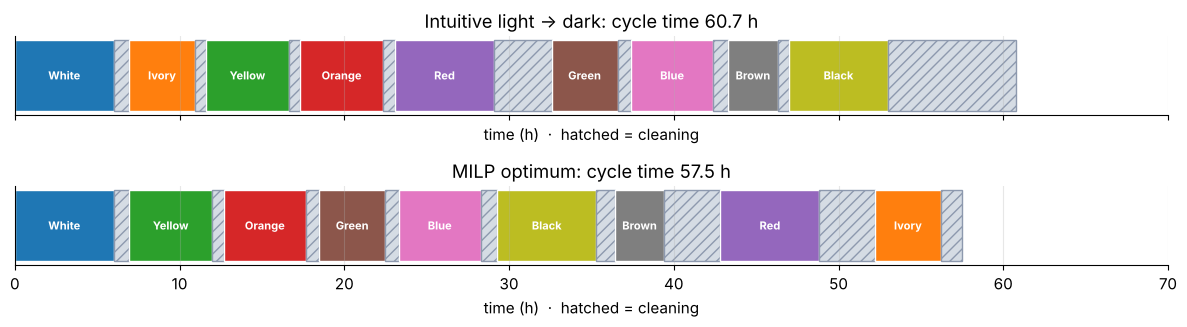

In [ ]:
def gantt(order, ax, title):
    t = 0; cmap_ = plt.cm.tab10
    for k, p in enumerate(order):
        ax.barh(0, PROC[p], left=t, color=cmap_(p % 10), edgecolor="white"); ax.text(t + PROC[p] / 2, 0, PRODS[p], ha="center", va="center", fontsize=8, color="white", fontweight="bold")
        t += PROC[p]; cl = CLEAN[p, order[(k + 1) % nP]]
        ax.barh(0, cl, left=t, color="#D5DCE4", hatch="///", edgecolor=GRAY); t += cl
    ax.set_yticks([]); ax.set_xlim(0, 70); ax.set_title(f"{title}: cycle time {t:.1f} h"); ax.set_xlabel("time (h)  ·  hatched = cleaning")

fig, ax = plt.subplots(2, 1, figsize=(12, 3.4), sharex=True)
gantt(intuitive, ax[0], "Intuitive light → dark"); gantt(order, ax[1], "MILP optimum")
plt.tight_layout(); plt.show()

### 11.2 Compact alternative: Miller–Tucker–Zemlin (MTZ) constraints
MTZ adds order variables $u_i$ and $n^2$ constraints $u_i - u_j + (n-1)x_{ij} \le n-2$ instead of exponentially many cuts. It is compact, but its LP relaxation is **weaker**:

In [ ]:
m2 = pyo.ConcreteModel(); m2.N = pyo.RangeSet(0, nP - 1); m2.A = pyo.Set(initialize=list(m.A))
m2.x = pyo.Var(m2.A, domain=pyo.Binary); m2.u = pyo.Var(m2.N, bounds=(1, nP - 1))
m2.obj = pyo.Objective(expr=sum(CLEAN[i, j] * m2.x[i, j] for (i, j) in m2.A))
m2.out = pyo.Constraint(m2.N, rule=lambda m, i: sum(m.x[i, j] for j in m.N if j != i) == 1)
m2.inn = pyo.Constraint(m2.N, rule=lambda m, j: sum(m.x[i, j] for i in m.N if i != j) == 1)
m2.mtz = pyo.Constraint(m2.A, rule=lambda m, i, j: m.u[i] - m.u[j] + (nP - 1) * m.x[i, j] <= nP - 2 if (i and j) else pyo.Constraint.Skip)
solve(m2)
lp_mtz = pyo.TransformationFactory("core.relax_integer_vars").create_using(m2); solve(lp_mtz)
lp_sec = pyo.TransformationFactory("core.relax_integer_vars").create_using(m);  solve(lp_sec)
print(f"MTZ optimum              : {pyo.value(m2.obj):.2f} h   (same as lazy cuts ✔)")
print(f"LP bound, MTZ            : {pyo.value(lp_mtz.obj):.2f} h")
print(f"LP bound, final SEC model: {pyo.value(lp_sec.obj):.2f} h   ← much tighter")

MTZ optimum              : 13.47 h   (same as lazy cuts ✔)
LP bound, MTZ            : 10.40 h
LP bound, final SEC model: 13.47 h   ← much tighter


###  Your turn 11 — a customer rule

A customer requires that **Black is always produced immediately after Brown** (shared pigment line). Fix the corresponding arc in the lazy-cut model `m` and re-solve with the same loop. How many extra cleaning hours does the rule cost?

In [ ]:
#  Your turn: write your code here, then compare with the solution below

<details><summary><b> Show solution</b></summary>

```python
m.x[PRODS.index("Brown"), PRODS.index("Black")].fix(1)
while True:
    solve(m); G = nx.DiGraph([(i, j) for (i, j) in m.A if pyo.value(m.x[i, j]) > 0.5]); cyc = list(nx.simple_cycles(G))
    if len(cyc) == 1: break
    for S in cyc: m.sec.add(sum(m.x[i, j] for i in S for j in S if i != j) <= len(S) - 1)
print(pyo.value(m.obj))
m.x[PRODS.index("Brown"), PRODS.index("Black")].unfix()
```
Result: **13.63 h** instead of 13.47 h, so the customer rule costs only **≈ 0.16 h** of cleaning per cycle. Fixing a binary is the simplest way to impose a business rule, and comparing with the unconstrained optimum **prices** the rule.

</details>

---
## Part 12 · Challenge problems

###  Challenge A — multi-period capacity expansion (lecture: "Extension to multi-period capacity planning")

Two processes make the same product. Over 4 years, demand grows to 150, 210, 280, 340 kt/yr. Expanding process $i$ in year $t$ costs $\alpha_i$ (fixed, M USD) $+ \beta_i \cdot QE_{it}$ (per kt/yr added); an expansion, if made, must be between 20 and 150 kt/yr; the budget is 40 M USD per year. Operating cost: 0.10 (process 1) and 0.07 (process 2) M USD per kt. Initial capacities: 100 and 0 kt/yr.

$$Q_{it} = Q_{i,t-1} + QE_{it},\qquad QE^L y_{it} \le QE_{it} \le QE^U y_{it},\qquad \sum_i (\alpha_i y_{it} + \beta_i QE_{it}) \le CI_t,\qquad \sum_i w_{it} \ge D_t,\; w_{it} \le Q_{it}$$

Minimize investment + operating cost. *Which process gets expanded, and when?*

In [ ]:
YEARS, PROCS = [1, 2, 3, 4], [1, 2]
D_ = {1: 150, 2: 210, 3: 280, 4: 340}; Q0 = {1: 100, 2: 0}; alpha = {1: 8, 2: 15}; beta = {1: 0.20, 2: 0.15}; opc = {1: 0.10, 2: 0.07}
# 🧪 Build and solve the model here

<details><summary><b> Show solution</b></summary>

```python
m = pyo.ConcreteModel(); m.T = pyo.Set(initialize=YEARS); m.I = pyo.Set(initialize=PROCS)
m.QE = pyo.Var(m.I, m.T, bounds=(0, 150)); m.Q = pyo.Var(m.I, m.T, domain=pyo.NonNegativeReals)
m.y = pyo.Var(m.I, m.T, domain=pyo.Binary); m.w = pyo.Var(m.I, m.T, domain=pyo.NonNegativeReals)
m.obj = pyo.Objective(expr=sum(alpha[i] * m.y[i, t] + beta[i] * m.QE[i, t] + opc[i] * m.w[i, t] for i in m.I for t in m.T))
m.cap = pyo.Constraint(m.I, m.T, rule=lambda m, i, t: m.Q[i, t] == (Q0[i] if t == 1 else m.Q[i, t - 1]) + m.QE[i, t])
m.lo  = pyo.Constraint(m.I, m.T, rule=lambda m, i, t: m.QE[i, t] >= 20 * m.y[i, t])
m.hi  = pyo.Constraint(m.I, m.T, rule=lambda m, i, t: m.QE[i, t] <= 150 * m.y[i, t])
m.bud = pyo.Constraint(m.T, rule=lambda m, t: sum(alpha[i] * m.y[i, t] + beta[i] * m.QE[i, t] for i in m.I) <= 40)
m.dem = pyo.Constraint(m.T, rule=lambda m, t: sum(m.w[i, t] for i in m.I) >= D_[t])
m.use = pyo.Constraint(m.I, m.T, rule=lambda m, i, t: m.w[i, t] <= m.Q[i, t])
solve(m)
for t in m.T: print(t, {i: (round(pyo.value(m.QE[i, t])), round(pyo.value(m.Q[i, t]))) for i in m.I})
print("total cost:", round(pyo.value(m.obj), 1), "M USD")
```
The cheaper-to-operate process 2 is built early (despite its higher fixed cost). The yearly budget forces the expansion to be **staged**, a decision an LP would smear into fractional "partial projects".

</details>

###  Challenge B — gas-detector placement with double coverage

A process area has 12 leak-risk points and 9 candidate detector locations (coordinates below). A detector covers a point within **4 m**. Safety logic requires **2-out-of-N voting**, so every risk point must be covered by **at least two** detectors. Minimize the number of detectors. How many do you need with single coverage?

In [ ]:
rng = np.random.default_rng(5)
RISK = rng.uniform(0, 12, (12, 2)); CAND = rng.uniform(0, 12, (9, 2)); RADIUS = 4.0
COVER = (np.linalg.norm(RISK[:, None] - CAND[None], axis=2) <= RADIUS).astype(int)    # a_ij = 1 if detector j sees point i
print("each risk point is visible from", COVER.sum(1), "candidate locations")
# 🧪 Formulate the set-multicover MILP with milp or Pyomo

each risk point is visible from [1 3 2 1 2 4 3 1 4 3 3 3] candidate locations


<details><summary><b> Show solution</b></summary>

```python
for k in [1, 2]:
    r = milp(np.ones(9), constraints=LinearConstraint(COVER, k, np.inf), integrality=np.ones(9), bounds=Bounds(0, 1))
    print(f"coverage ≥ {k}:", "infeasible" if r.x is None else f"{int(r.fun)} detectors at {np.flatnonzero(r.x > 0.5) + 1}")

need = np.minimum(2, COVER.sum(1))                    # double coverage wherever it is physically possible
r = milp(np.ones(9), constraints=LinearConstraint(COVER, need, np.inf), integrality=np.ones(9), bounds=Bounds(0, 1))
print(f"best achievable: {int(r.fun)} detectors at {np.flatnonzero(r.x > 0.5) + 1}; points {np.flatnonzero(need < 2) + 1} need new locations")
```
Single coverage needs **4** detectors. Double coverage is **infeasible**: risk points 1, 4 and 8 are visible from only **one** candidate location. Infeasibility is useful information here, because it tells the layout team **where** new candidate locations are needed. Demanding double coverage wherever it is possible takes **6** detectors.

</details>

---
##  Summary

| You implemented … | Key lesson |
|---|---|
| `milp` and Pyomo models | the same MILP in matrix and algebraic form; Pyomo scales to real process models |
| enumeration vs. solver | $2^n$ explodes; branch-and-cut solves the same problems in milliseconds |
| fixed-charge plant decisions | binaries create break-even thresholds and non-trivial decision maps |
| distillation superstructure | integer cuts rank all designs; MILP rediscovers separation heuristics |
| piecewise-linear capex | concave costs need binaries; coarse chords underestimate cost |
| logic → CNF → inequalities | automate with `sympy` and always verify against the truth table |
| unit commitment | binaries for on/off + semi-continuous output; LP relaxation = "half a turbine" |
| your own B&B | fathoming rules, node selection, incumbent vs. bound |
| Gomory & cover cuts | cuts tighten the LP; one good cut can replace dozens of nodes |
| formulation experiments | strong (disaggregated, tight-M) models win even with more rows |
| changeover TSP | lazy constraint generation vs. compact MTZ |

**References:** L.A. Wolsey, *Integer Programming*, 2nd ed. (2020) · L.T. Biegler, I.E. Grossmann & A.W. Westerberg, *Systematic Methods of Chemical Process Design* (1997) · [Pyomo documentation](https://pyomo.readthedocs.io) · [HiGHS documentation](https://highs.dev) · [SciPy `milp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html)

---
<div align="center">

**© 2026 Abdulelah S. Alshehri. All rights reserved.**<br>
CHE 581: Process Optimization · College of Engineering — King Saud University<br>
<sub>This material may not be reproduced or distributed without written permission of the author.</sub>

</div>

---
<div align="center">

**© 2026 Abdulelah S. Alshehri. All rights reserved.**<br>
CHE 581: Process Optimization · College of Engineering — King Saud University<br>
<sub>This material may not be reproduced or distributed without written permission of the author.</sub>

</div>